# Explore the DES Y3 × Planck PR4 shear predictions

This notebook calls the compiled CosmoLike library of the `desy1xplanck` project directly from Python, without Cobaya, to inspect the predictions behind its likelihood. The data combine DES Year 3 galaxy shapes and magnitude-limited (MagLim) lens galaxies with the Planck PR4 map of CMB lensing. The cells cover

- the cosmic-shear angular power spectra $C_\ell^{EE}$ and correlation functions $\xi_\pm(\theta)$, and their response to cosmological, intrinsic-alignment and baryonic-feedback parameters;
- the numerical changes produced by the accuracy settings of CAMB and CosmoLike;
- the cosmic-shear $\chi^2$ against the measured data vector, as in [EXAMPLE_EVALUATE1.yaml](EXAMPLE_EVALUATE1.yaml), with two models of the nonlinear matter power spectrum (Halofit and EuclidEmulator2);
- response functions: the wavenumbers $k$ of the matter power spectrum on which each measurement depends;
- the cross-correlation of CMB lensing and cosmic shear, $C_\ell^{\kappa s}$ and $w_{\kappa s}(\theta)$.

The likelihood's data vector, the ordered list of measured values, has 1,809 entries. The 1,500 galaxy/shear entries are $\xi_+$ and $\xi_-$ (300 each: 10 source-bin pairs × 30 angular bins), galaxy–galaxy lensing $\gamma_t$ (720: 24 lens–source pairs × 30) and galaxy clustering $w$ (180: 6 lens bins × 30). The 309 CMB-lensing entries are CMB lensing × galaxies (180), CMB lensing × shear (120) and nine bandpowers of the CMB-lensing auto-spectrum. These observables need their own model ingredients: a single source plane at last scattering, the filtering of the lensing map and the bandpower binning. The covariance generated by [EXAMPLE_EVALUATE_COVARIANCE.ipynb](EXAMPLE_EVALUATE_COVARIANCE.ipynb) covers the galaxy/shear entries only; the likelihood uses the supplied 1,809-entry matrix.

Compile the project and start Jupyter from an activated Cocoa environment, as the [project README](README.md#notebooks) describes. Every prediction runs CAMB once, so a sweep over 10–40 parameter values takes minutes.

| Convention | In this notebook |
| --- | --- |
| Source bins | 4 tomographic (redshift) bins; cosmic shear has 10 pairs $(i,j)$ with $i\le j$ |
| Lens bins | 6 MagLim bins; they enter the $\chi^2$ machinery, not the figures |
| Angle $\theta$ | arcminutes; 30 logarithmic bins from 0.25′ to 250′, each represented by its area-weighted center |
| Multipole $\ell$ | spectra are evaluated at the multipoles in `ell`, in the Limber approximation: multipole $\ell$ at comoving distance $\chi$ probes $k=(\ell+1/2)/\chi$ |
| Wavenumber $k$ | $h\,\mathrm{Mpc}^{-1}$ |
| Array axes | `C_ss` (EE and BB): `[ell, i, j]`; `xi_plus`, `xi_minus`: `[theta, i, j]`; `C_ks`, `w_ks`: `[ell or theta, i]` |
| Bin numbers | arrays count bins from 0 and panel labels from 1: panel (1,2) draws `[:, 0, 1]` |

## Set up the Python session

The first two cells prepare the *kernel*, the Python process that runs the cells of this notebook.

- `OMP_NUM_THREADS` sets how many OpenMP threads (parallel workers inside the compiled C code) CosmoLike uses. The cell assigns it before the compiled library is imported, replacing the value exported in the shell.
- `cosmolike_desy1xplanck_interface`, imported as `ci`, is this project's compiled CosmoLike library, exposed to Python with pybind11.
- The `rcParams` lines set matplotlib's figure style for the whole session. `text.usetex = True` typesets every label with LaTeX and needs the LaTeX packages listed in the cell.
- The second cell imports CAMB, the shared package `cosmolike_notebook_utils` (as `cnu`: the CAMB helper and the plotting functions every Cocoa project uses) and this project's notebook wrappers (as `nw`, defined in [interface/cosmolike_desy1xplanck_notebook_wrappers.py](interface/cosmolike_desy1xplanck_notebook_wrappers.py)).

The printed working directory must be this project's folder, because the wrappers find the dataset through a path relative to it. The other printed paths show which installations were loaded.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import sys, platform, os
# OpenMP threads of the compiled CosmoLike loops: assigned before the
# interface import below, replacing the shell's OMP_NUM_THREADS. Keep it
# at or below the number of physical cores.
os.environ['OMP_NUM_THREADS'] = '4'
import matplotlib
import math
import warnings
from matplotlib import pyplot as plt
import numpy as np
import euclidemu2
import scipy
import cosmolike_desy1xplanck_interface as ci
from getdist import IniFile
import itertools
import iminuit
import functools
from scipy.interpolate import interp1d
print(sys.version)
print(os.getcwd())

# Figure style for the whole session (matplotlib's global rcParams); the
# shared plotting functions never change these settings.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'

# ----------------------------------------------------------------------------------------------------------------------------------
# ----------------------------------------------------------------------------------------------------------------------------------
# ----------------------------------------------------------------------------------------------------------------------------------
# usetex typesets every label with LaTeX. It needs texlive-latex-base,
# texlive-latex-extra, texlive-fonts-recommended, dvipng, ghostscript and
# cm-super; set it to False when they are not installed.
matplotlib.rcParams['text.usetex'] = True
# ----------------------------------------------------------------------------------------------------------------------------------
# ----------------------------------------------------------------------------------------------------------------------------------
# ----------------------------------------------------------------------------------------------------------------------------------

# Display only: a wider notebook page and a taller output scroll area.
import IPython
IPython.display.display(IPython.display.HTML("<style>:root { --jp-notebook-max-width: 85% !important; }</style>"))
IPython.display.display(IPython.display.HTML("<style>div.output_scroll { height: 54em; }</style>"))


Classy could not be found in your system.
Here are some suggestions:

	 -Download the Class from class-code.net and install it
	  together with its wrapper classy (type 'make' instead of
	  'make class'
	 -If you know that Class is installed on your system
	  and yet classy could not be installed, try re-compiling
	  Class with just ''make'' instead of ''make class''
NOTICE: Even without classy you can still use EuclidEmulator2
        to emulate boost factors. You won't be able to compute
        full power spectra, though.


3.11.12 | packaged by conda-forge | (main, Apr 10 2025, 22:18:52) [Clang 18.1.8 ]
/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/desy1xplanck


In [2]:
# CAMB. Python skips the build folder named below when it does not exist (other
# platforms and build tools name it differently) and then imports the CAMB
# already on its search path; the print shows which installation was loaded.
sys.path.insert(0, os.environ['ROOTDIR']+'/external_modules/code/CAMB/build/lib.linux-x86_64-'+os.environ['PYTHON_VERSION'])
import camb
from camb import model
print('Using CAMB %s installed at %s'%(camb.__version__,os.path.dirname(camb.__file__)))

# The notebook package shared by every Cocoa project (CAMB helper, plots).
sys.path.insert(0, os.environ['ROOTDIR']+'/external_modules/code/cosmolike_core')
import cosmolike_notebook_utils as cnu
print('Using cosmolike_notebook_utils installed at %s'%(os.path.dirname(cnu.__file__)))


# This project's notebook wrappers (interface/, on the PYTHONPATH that
# start_cocoa.sh extends): the probe, chi2 and response functions shared
# by every notebook of this project.
import cosmolike_desy1xplanck_notebook_wrappers as nw
print('Using notebook wrappers installed at %s'%(nw.__file__))

Using CAMB 1.6.7 installed at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/.local/lib/python3.11/site-packages/camb
Using cosmolike_notebook_utils installed at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/cosmolike_core/cosmolike_notebook_utils
Using notebook wrappers installed at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/desy1xplanck/interface/cosmolike_desy1xplanck_notebook_wrappers.py


## Mirror the YAML settings

The next cell repeats choices of [EXAMPLE_EVALUATE1.yaml](EXAMPLE_EVALUATE1.yaml). `nw.configure` hands five of them to the wrappers:

- `ntheta`, `theta_min_arcmin` and `theta_max_arcmin`, the angular binning of $\xi_\pm(\theta)$;
- `non_linear_emul`, the nonlinear matter power spectrum: 1 for EuclidEmulator2, 2 for Halofit;
- `lmax`, the highest multipole of the internal $C_\ell$ table that is summed into $\xi_\pm(\theta)$. The smallest angle, 0.25′, needs multipoles of several times $10^4$, far above the range plotted below.

The remaining names only document the YAML; no later cell reads them. The wrappers already hold the same intrinsic-alignment model, NLA with a power-law redshift dependence.

The cell after it imports the fiducial point, the reference parameter values stored in the wrappers module. Each sweep below varies one of them and keeps the others; any wrapper call can also override a value, e.g. `nw.get_chi2(omegam=0.31)`.

In [3]:
# Values copied from EXAMPLE_EVALUATE1.yaml. Only the five handed to
# nw.configure below reach the wrappers; CAMBAccuracyBoost, CLprobe, path,
# data_file and the IA_* names are not read by later cells. The wrappers
# keep the same IA choices; nw.configure(IA_model=...) before
# nw.init_cosmolike changes them.
CAMBAccuracyBoost = 1.0
non_linear_emul = 2
CLprobe="xi"

path= "../../external_modules/data/desy1xplanck"
data_file="Y3xPlanckPR4.dataset"

IA_model = 0
IA_redshift_evolution = 3
IA_code = 0  # 0 = C FASTPT, 1 = Python FAST-PT (NLA always uses 0)

ntheta = 30
theta_min_arcmin = 0.25
theta_max_arcmin = 250
lmax = 75000

# hand this notebook's yaml-mirroring values to the shared wrappers
nw.configure(lmax=lmax,
             ntheta=ntheta,
             theta_min_arcmin=theta_min_arcmin,
             theta_max_arcmin=theta_max_arcmin,
             non_linear_emul=non_linear_emul)

In [4]:
# The project fiducial point lives in the wrappers module
# (interface/cosmolike_desy1xplanck_notebook_wrappers.py), shared by
# every notebook. The names are imported so the sweep cells below can
# build shifted vectors from them; override any value per call
# instead, e.g. nw.get_chi2(omegam=0.31).
from cosmolike_desy1xplanck_notebook_wrappers import (
    As_1e9, ns, H0, omegab, omegam, mnu, w, w0pwa,
    DES_A1_1, DES_A1_2,
    DES_DZ_S1, DES_DZ_S2, DES_DZ_S3, DES_DZ_S4,
    DES_M1, DES_M2, DES_M3, DES_M4,
    DES_DZ_L1, DES_DZ_L2, DES_DZ_L3, DES_DZ_L4, DES_DZ_L5, DES_DZ_L6,
    DES_DZ2_L1, DES_DZ2_L2, DES_DZ2_L3, DES_DZ2_L4, DES_DZ2_L5, DES_DZ2_L6,
    DES_B1_1, DES_B1_2, DES_B1_3, DES_B1_4, DES_B1_5, DES_B1_6,
    DES_BMAG_1, DES_BMAG_2, DES_BMAG_3, DES_BMAG_4, DES_BMAG_5, DES_BMAG_6,
    DES_PM1, DES_PM2, DES_PM3, DES_PM4, DES_PM5, DES_PM6)

## What one wrapper call does

The compiled library keeps *global state*: it stores the cosmology tables, nuisance parameters and binning between calls, and every compute function reads the values set last. So that no call depends on the one before it, each wrapper (`nw.C_ss_tomo_limber`, `nw.xi`, `nw.get_chi2`, ...) rebuilds the complete state in four stages.

1. **CAMB.** `cnu.get_camb_cosmology` runs CAMB once. It returns the linear and nonlinear matter power spectra as $\ln P$, with $P$ in $(\mathrm{Mpc}/h)^3$, on a grid of $\log_{10}k$ with $k$ in $h\,\mathrm{Mpc}^{-1}$, together with the growth factor and the comoving distance $\chi(z)$ in $\mathrm{Mpc}/h$, on redshift and wavenumber grids that follow the likelihood's.
2. **`ci.set_cosmology`.** The tables enter the C library, which interpolates them in every later integral. New tables also invalidate CosmoLike's caches: stored intermediate results, such as $C_\ell$ tables, that are reused until an input changes.
3. **Nuisance setters.** `ci.set_nuisance_shear_calib` sets the multiplicative shear biases $m_i$ (the measured shear is $1+m_i$ times the true one), `ci.set_nuisance_shear_photoz` shifts each source redshift distribution by $\Delta z_i$, and `ci.set_nuisance_ia` sets the intrinsic-alignment parameters. `nw.get_chi2` also sets the lens redshift shifts and stretches, the galaxy and magnification biases and the point-mass terms; probes that are not selected ignore them.
4. **Prediction.** `ci.C_ss_tomo_limber`, `ci.xi_pm_tomo`, `ci.w_ks_tomo` or `ci.compute_data_vector_masked` evaluates the requested quantity from that state.

The wrappers also translate the accuracy arguments described before the accuracy figures. The three comment cells below say where each function lives; `help(nw.xi)` prints the arguments of a wrapper.

In [5]:
# get_camb_cosmology lives in cosmolike_core, shared by every project's
# notebooks; call it as cnu.get_camb_cosmology (imported above):
# external_modules/code/cosmolike_core/cosmolike_notebook_utils


In [6]:
# C_ss_tomo_limber lives in this project's interface/
# (cosmolike_desy1xplanck_notebook_wrappers, imported above as nw),
# shared by every notebook of this project; call as
# nw.C_ss_tomo_limber.

In [7]:
# xi lives in this project's interface/
# (cosmolike_desy1xplanck_notebook_wrappers, imported above as nw),
# shared by every notebook of this project; call as
# nw.xi.

## Initialize the interface

`nw.init_cosmolike()` performs the setup that the likelihood runs when it starts. It reads [the dataset file](data/Y3xPlanckPR4.dataset), a small text file naming the redshift distributions, data vector, covariance, mask and CMB-lensing inputs. It then sets the angular binning, the redshift-distribution conventions, the CMB-lensing filters, the intrinsic-alignment model and the 6 lens and 4 source redshift distributions. Called without arguments, it skips the probe selection and the data files, which only the $\chi^2$ cells need. `nw.allsims` names the HDF5 file of hydrodynamical-simulation power-spectrum ratios used by the baryonic-feedback cells.

In [8]:
# Init Cosmolike (the full sequence lives in nw.init_cosmolike)
ini = nw.init_cosmolike()
# The HDF5 file of hydrodynamical-simulation power-spectrum ratios named
# in the dataset; the baryonic-feedback cells pass it back to the wrappers.
allsims = nw.allsims

## The shared plotting functions

The figures use plotting functions of `cosmolike_notebook_utils` (`cnu`), which the two comment cells below name. They receive numpy arrays only and never call CAMB or the compiled library.

- `cnu.plot_C_ss_tomo_limber` and `cnu.plot_xi` draw one panel per source-bin pair $(i,j)$, arranged as a lower triangle.
- Without a reference, a $C_\ell$ panel shows $\ell(\ell+1)C_\ell^{EE}/2\pi$ on a logarithmic axis, and a $\xi$ panel shows $\theta\,\xi_\pm\times10^4$ with $\theta$ in arcminutes. With `rescale=1`, each panel is multiplied by its own power of ten, printed inside it as $\alpha$, so that all panels share one y range.
- With a reference (`C_ss_ref`, `xi_ref`), each panel shows the fractional difference value/reference − 1, and `ylim` is given as multipliers around 1: `ylim=(0.98, 1.02)` draws a ±2% band.
- `param` and `colorbarlabel` color a parameter sweep: each curve takes the color that the colorbar shows at its value. `plot_xi(pm=1, ...)` draws $\xi_+$; a `pm` of zero or less draws $\xi_-$.

`help(cnu.plot_xi)` lists every option.

In [9]:
# plot_C_ss_tomo_limber lives in cosmolike_core (shared); call it as
# cnu.plot_C_ss_tomo_limber (imported above)


In [10]:
# plot_xi lives in cosmolike_core (shared); call it as cnu.plot_xi
# (imported above)

## How cosmological and intrinsic-alignment parameters change $C_\ell^{EE}$

$C_\ell^{EE,ij}$ is the angular power spectrum of the E-mode (curl-free) part of the cosmic shear between source bins $i$ and $j$. Each sweep calls the wrapper once per value and keeps every other parameter at the fiducial point:

- $\Omega_m$ from 0.20 to 0.38, drawn as absolute spectra with `rescale=1`;
- the spectral index $n_s$ from 0.85 to 1.09, as fractional differences from the fiducial spectrum `ref`;
- the intrinsic-alignment amplitude $A_\mathrm{IA}$ from 0 to 2.9 and its redshift exponent $\eta_\mathrm{IA}$ from −2 to 1.9, also relative to `ref`.

Intrinsic alignment is the correlated orientation of galaxy shapes caused by the tidal field around them; it adds to the lensing signal. In the NLA (nonlinear alignment) model used here, the amplitude at redshift $z$ is $A_\mathrm{IA}\,[(1+z)/1.62]^{\eta_\mathrm{IA}}$, with fiducial values $A_\mathrm{IA}=-0.7$ and $\eta_\mathrm{IA}=-1.7$. The wrappers receive both as `A1 = [A_IA, eta_IA, 0, 0]`. In each sweep, `tmp` receives the B-mode spectrum $C_\ell^{BB}$, which these figures do not use.

In [11]:
# lmin and lmax set the plotted multipole range only; the C_ell table
# cutoff lmax = 75000 was handed to nw.configure above.
lmin = 100.
lmax = 4500.
ell = np.arange(lmin, lmax, 20.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
param = np.arange(0.2, 0.4, 0.02)     
C_ss = []
for x in param:
    # The wrapper returns (EE, BB); tmp receives the B-mode spectrum.
    (Cl, tmp) = nw.C_ss_tomo_limber(ell=ell, omegam=x)
    C_ss.append(Cl)

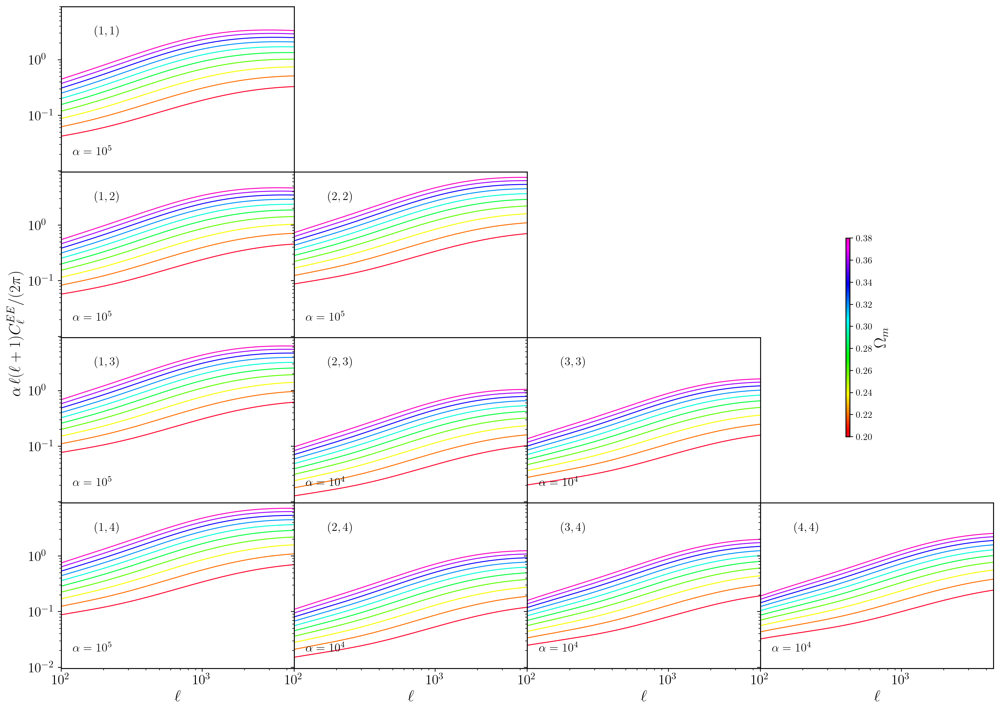

In [12]:
cnu.plot_C_ss_tomo_limber(ell=ell,
                          C_ss=C_ss,
                          param=param,
                          colorbarlabel="$\Omega_m$",
                          yaxislabelsize = 17,
                          xaxislabelsize = 17,
                          xaxisticklabelsize=15,
                          yaxisticklabelsize=15,
                          figsize = (18, 13),
                          lmin = lmin,
                          lmax = lmax,
                          wspace=0.4,
                          rescale=1,
                          ydecades=4)

In [13]:
lmin = 100.
lmax = 4500.
ell = np.arange(lmin,lmax, 20.) # Make sure arange are with float numbers (otherwise there are aliasing problems)
param = np.arange(0.85, 1.1, 0.02)
C_ss = []
for x in param:
    (Cl, tmp) = nw.C_ss_tomo_limber(ell=ell, ns=x)
    C_ss.append(Cl)
# Fiducial spectrum: the reference of this figure and of the two
# intrinsic-alignment sweeps below.
(ref, tmp) = nw.C_ss_tomo_limber(ell=ell)

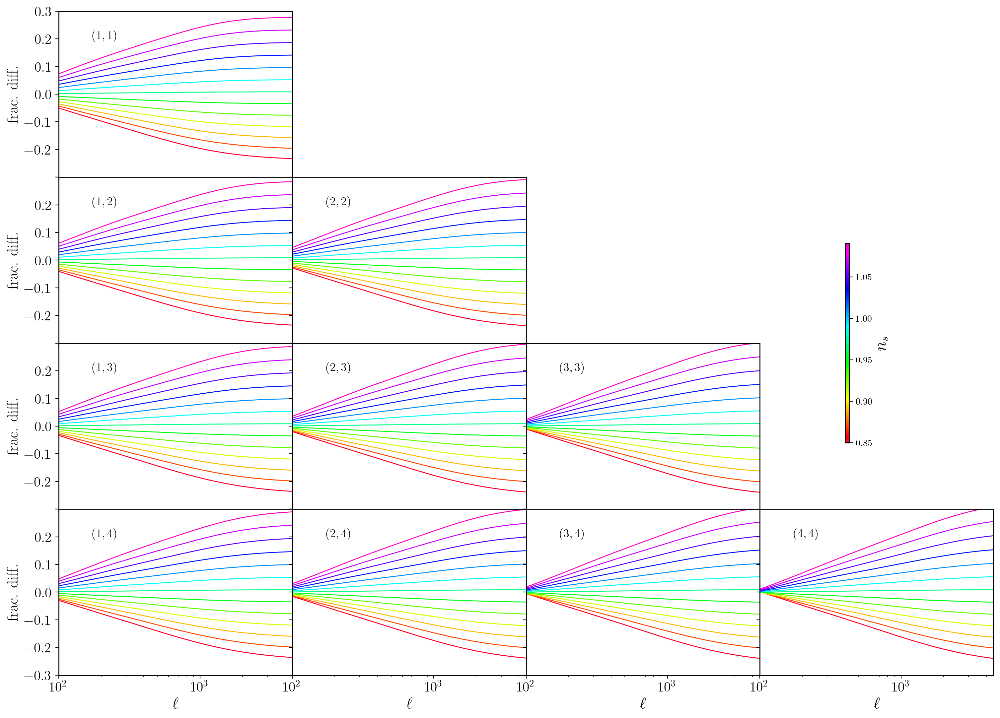

In [14]:
cnu.plot_C_ss_tomo_limber(ell=ell,
                          C_ss=C_ss,
                          C_ss_ref=ref,
                          param=param,
                          colorbarlabel="$n_s$",
                          figsize = (18, 13),
                          yaxislabelsize = 17,
                          xaxislabelsize = 17,
                          xaxisticklabelsize=15,
                          yaxisticklabelsize=15,
                          lmin = lmin,
                          lmax = lmax,
                          ylim = [0.7,1.3],
                          wspace=0.4)

In [15]:
lmin = 100.
lmax = 4500.
ell = np.arange(lmin, lmax, 20.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
param = np.arange(0.0, 3, 0.1)     
C_ss = []
for x in param:
    # A1 = [A_IA, eta_IA, 0, 0]: the NLA amplitude at redshift z is
    # A_IA ((1 + z)/1.62)^eta_IA. This sweep varies A_IA.
    (Cl, tmp) = nw.C_ss_tomo_limber(ell=ell, A1 = [x, DES_A1_2, 0, 0])
    C_ss.append(Cl)

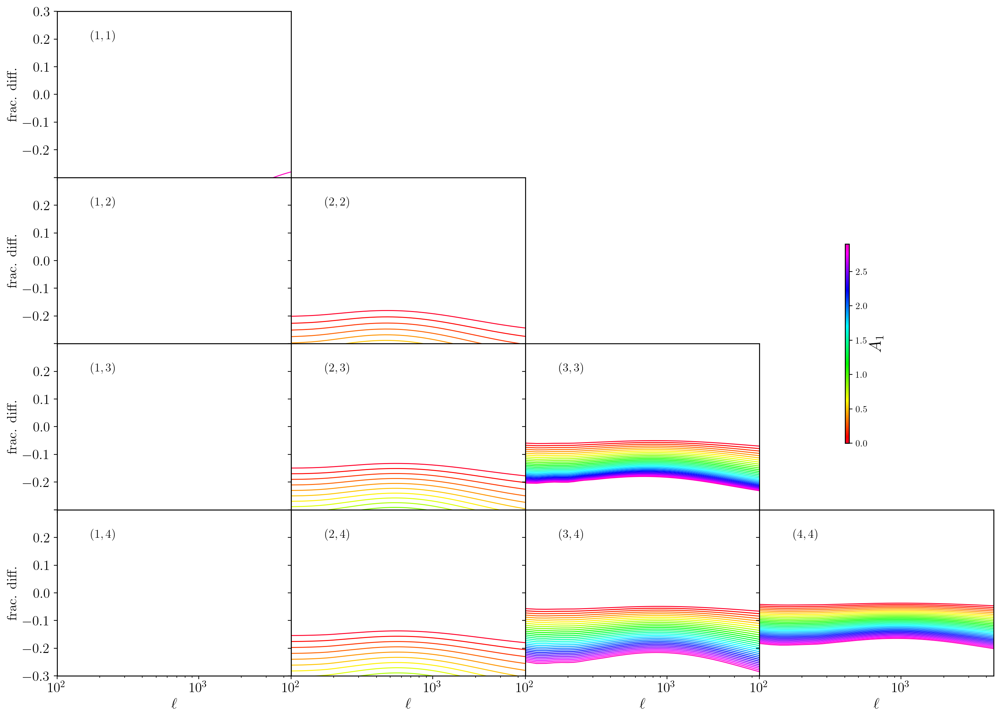

In [16]:
cnu.plot_C_ss_tomo_limber(ell=ell,
                          C_ss=C_ss,
                          C_ss_ref=ref,
                          param=param,
                          colorbarlabel="$A_1$",
                          figsize = (18, 13),
                          yaxislabelsize = 15,
                          xaxisticklabelsize=15,
                          yaxisticklabelsize=15,
                          lmin = lmin,
                          lmax = lmax,
                          ylim = [0.7,1.3],
                          wspace=0.4)

In [17]:
lmin = 100.
lmax = 4500.
ell = np.arange(lmin, lmax, 20.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
param = np.arange(-2, 2, 0.1)     
C_ss = []
for x in param:
    # This sweep varies eta_IA, the redshift exponent in A1; the colorbar
    # label A_2 in the next cell names this exponent.
    (Cl, tmp) = nw.C_ss_tomo_limber(ell=ell, A1 = [DES_A1_1, x, 0, 0])
    C_ss.append(Cl)

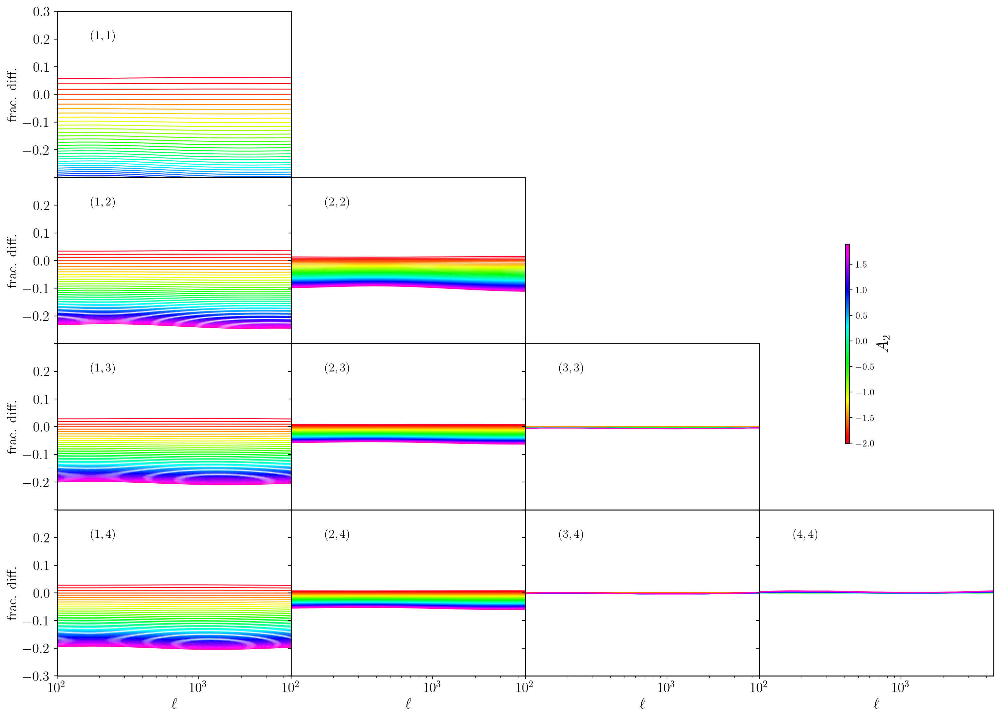

In [18]:
cnu.plot_C_ss_tomo_limber(ell=ell,
                          C_ss=C_ss,
                          C_ss_ref=ref,
                          param=param,
                          colorbarlabel="$A_2$",
                          figsize = (18, 13),
                          yaxislabelsize = 15,
                          xaxisticklabelsize=15,
                          yaxisticklabelsize=15,
                          lmin = lmin,
                          lmax = lmax,
                          ylim = [0.7,1.3],
                          wspace=0.4)

## How $\Omega_m$ changes $\xi_\pm(\theta)$

The real-space correlation functions are bin-averaged Legendre sums of the angular spectra, $\xi_+=\sum_\ell G^+_\ell\,(C_\ell^{EE}+C_\ell^{BB})$ and $\xi_-=\sum_\ell G^-_\ell\,(C_\ell^{EE}-C_\ell^{BB})$, where the kernels $G^\pm_\ell(\theta)$ average Legendre functions over each angular bin. At the same angle, $\xi_-$ weights higher multipoles than $\xi_+$, so it is more sensitive to small-scale, nonlinear power. `nw.xi` returns the tuple `(theta, xi_plus, xi_minus)` with `theta` in arcminutes; `pm=1` plots $\xi_+$ and `pm=-1` plots $\xi_-$.

In [19]:
param = np.arange(0.2, 0.4, 0.02)
xi_theta = []
for x in param:
    xi_theta.append(nw.xi(omegam = x))

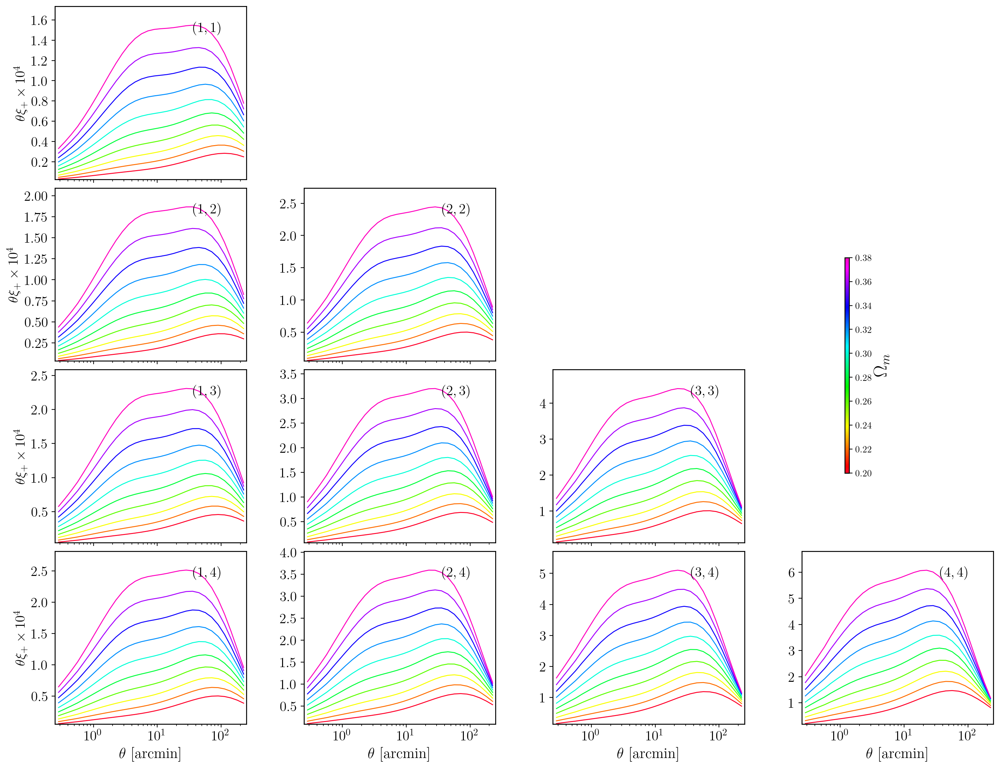

In [20]:
cnu.plot_xi(pm = 1,
            xi = xi_theta,
            param = param,
            colorbarlabel = "$\Omega_m$",
            yaxislabelsize = 15,
            xaxisticklabelsize=15,
            yaxisticklabelsize=15,
            figsize = (18, 14),
            thetashow=[0.25,250],
            wspace=0.3,
            rescale=None)

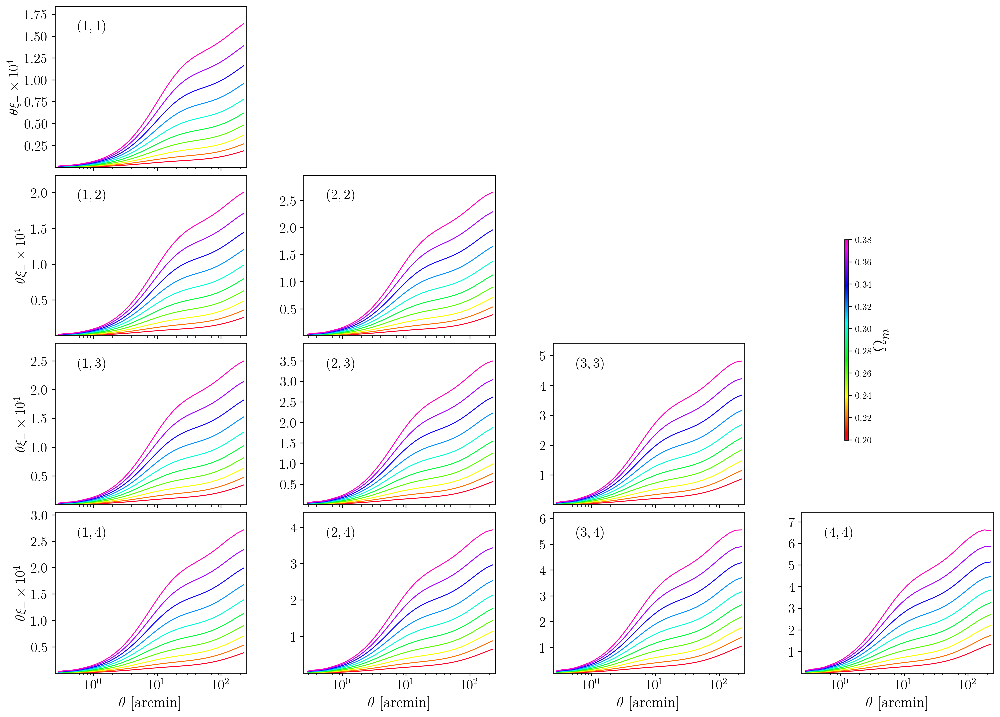

In [21]:
cnu.plot_xi(pm = -1,
            xi = xi_theta,
            param = param,
            colorbarlabel = "$\Omega_m$",
            yaxislabelsize = 15,
            xaxisticklabelsize=15,
            yaxisticklabelsize=15,
            figsize = (18, 13),
            thetashow=[0.25,250],
            wspace=0.3,
            rescale=None)

## Change the angular binning without restarting the kernel

CosmoLike keeps expensive intermediate results in C *static variables*, which persist inside the compiled library between calls. The Legendre kernels $G^\pm_\ell(\theta)$ depend on the angular bins, so a stale copy would silently describe the old binning. Each cache therefore carries a key: `nw.xi(ntheta=...)` calls `ci.init_binning`, which issues a new key whenever the number of bins or the angular range changes, and the kernels are rebuilt. The curves below use 9, 12, 17 and 44 bins between 0.25′ and 250′. Each binning has its own bin centers, so the curves are overlaid as absolute values, one marker style per binning.

In [22]:
nthetas=[9, 12, 17, 44]
result = []
for x in nthetas:
    result.append(nw.xi(ntheta=x))

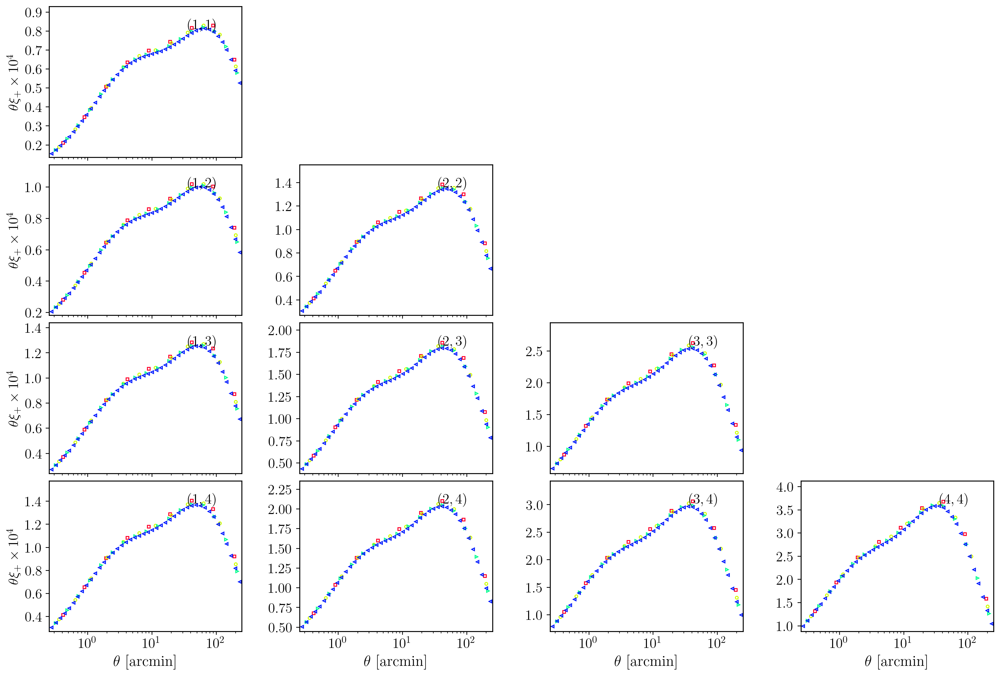

In [23]:
cnu.plot_xi(pm = 1,
            xi = result,
            marker=['s', 'o', ">", "<"],
            yaxislabelsize = 15,
            xaxisticklabelsize=15,
            yaxisticklabelsize=15,
            figsize = (18, 12),
            thetashow=[0.25,250],
            wspace=0.3,
            rescale=None)

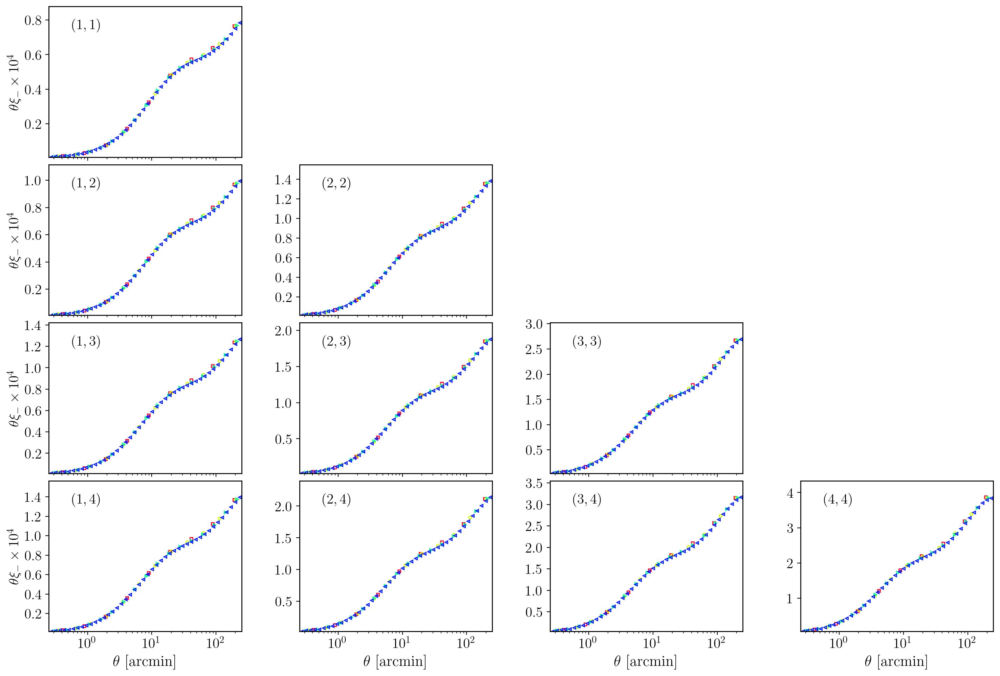

In [24]:
cnu.plot_xi(pm = -1,
            xi = result,
            marker=['s', 'o', ">", "<"],
            yaxislabelsize = 15,
            xaxisticklabelsize=15,
            yaxisticklabelsize=15,
            figsize = (18, 12),
            thetashow=[0.25,250],
            wspace=0.3,
            rescale=None)

## Baryonic feedback in $C_\ell^{EE}$ and $\xi_\pm(\theta)$

Gas cooling, star formation and feedback from supernovae and active galactic nuclei redistribute matter inside halos. Depending on the simulation, they suppress the matter power spectrum by up to a few tens of percent at wavenumbers of a few $h\,\mathrm{Mpc}^{-1}$. `baryon_sims=name` multiplies the nonlinear power spectrum by the ratio $P_\mathrm{hydro}(k,z)/P_\mathrm{DMO}(k,z)$ between a hydrodynamical simulation and its dark-matter-only counterpart, read from the HDF5 file `allsims`; `baryon_sims=None` removes it. The nine scenarios come from TNG100, Horizon-AGN, MassiveBlack-II, Illustris, EAGLE, three OWLS AGN variants and BAHAMAS.

Each reference is the same cosmology without feedback, so the panels show the fractional change caused by each scenario. Colors identify the scenarios consistently in all three figures, in the order of `param` that the $\xi_\pm$ legends list. Line styles are not a key: they cycle from panel to panel.

In [25]:
lmin = 100.
lmax = 4500.
ell = np.arange(lmin, lmax, 20.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
param = ("TNG100-1", "HzAGN-1", "mb2-1", "illustris-1", "eagle-1", "owls_AGN-1", "owls_AGN-2", "owls_AGN-3", "BAHAMAS-2")
C_ss = []
for x in param:
    (Cl, tmp) = nw.C_ss_tomo_limber(ell=ell, baryon_sims=x,allsims=allsims)
    C_ss.append(Cl)
    
# Reference: the same cosmology without baryonic feedback.
(C_ss_ref, tmp) = nw.C_ss_tomo_limber(ell=ell)

# 40 angular bins for the curves and the reference alike: a ratio needs
# one theta grid.
xi_theta = []
for x in param:
    xi_theta.append(nw.xi(baryon_sims=x,allsims=allsims, ntheta=40, AccuracyBoost=1.0))

xi_theta_ref = nw.xi(ntheta=40, AccuracyBoost=1.0)

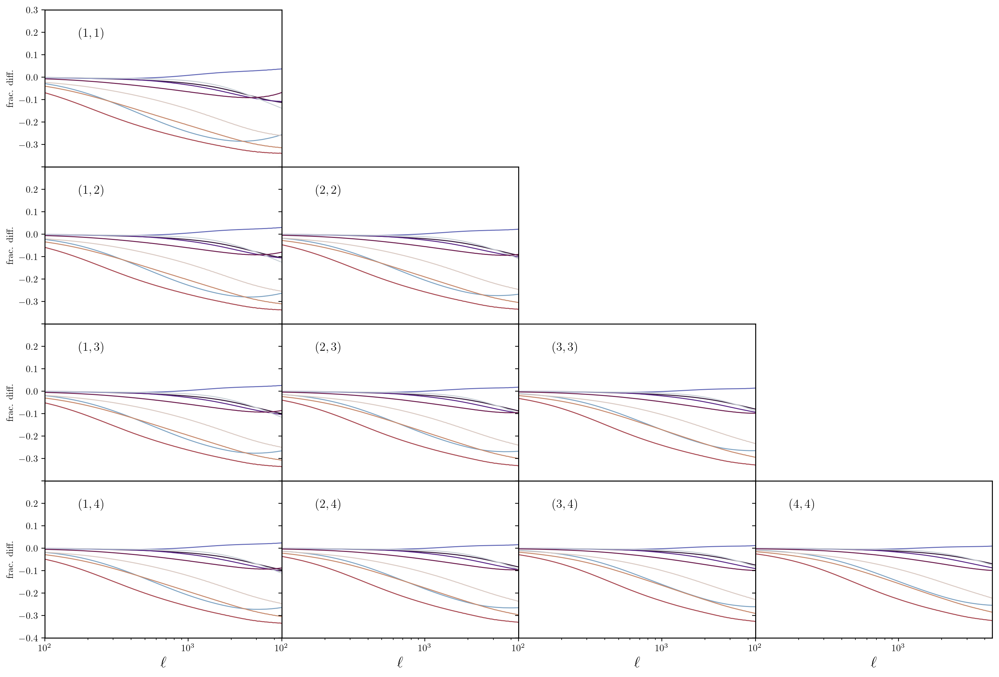

In [26]:
cnu.plot_C_ss_tomo_limber(ell=ell,
                          C_ss=C_ss,
                          C_ss_ref=C_ss_ref,
                          lmin=lmin,
                          lmax=lmax,
                          cmap="twilight_shifted",
                          yaxislabelsize = 10,
                          xaxisticklabelsize=10,
                          yaxisticklabelsize=10,
                          ylim=(0.6,1.3),
                          figsize = (18, 12),
                          wspace=0.4)

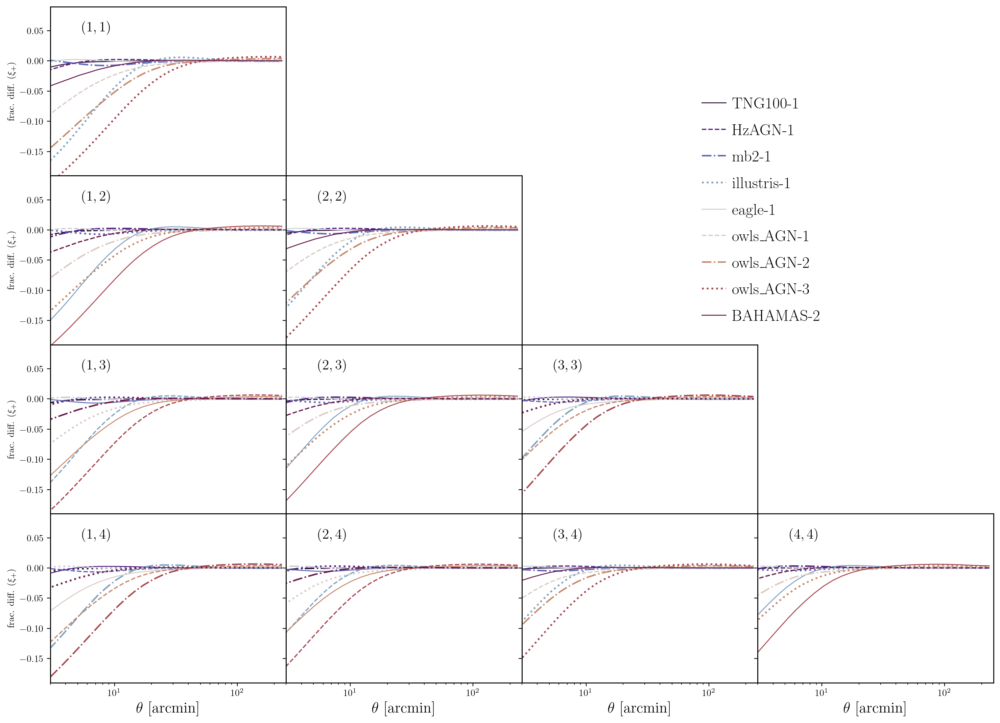

In [27]:
# rcParams changes persist for every later figure of this kernel.
matplotlib.rcParams['legend.fontsize'] = 17
cnu.plot_xi(pm = 1,
            param=None,
            xi=xi_theta,
            xi_ref=xi_theta_ref,
            cmap="twilight_shifted",
            ylim=(0.81,1.09),
            linewidth=[1.0, 1.3, 1.6, 1.9],
            linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
            legend = param,
            legendloc=(0.7,0.55),
            bintextpos = [[0.2, 0.875],[0.2,0.875]],
            yaxislabelsize = 10,
            xaxisticklabelsize=10,
            yaxisticklabelsize=10,
            figsize = (18, 13),
            wspace=0.4)

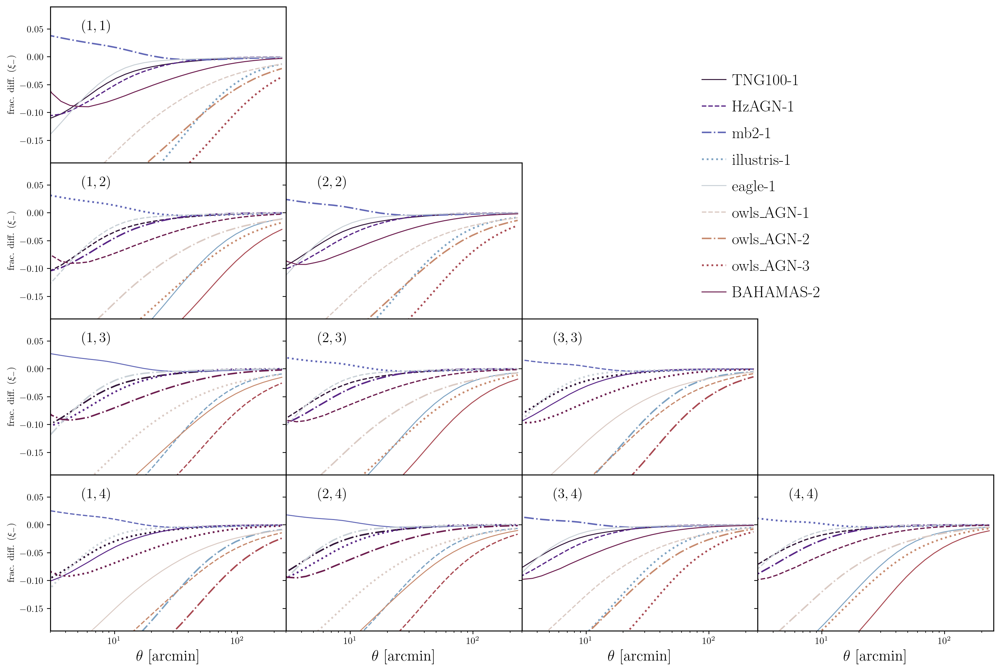

In [28]:
cnu.plot_xi(pm = -1,
            param=None,
            xi=xi_theta,
            xi_ref=xi_theta_ref,
            cmap="twilight_shifted",
            ylim=(0.81,1.09),
            linewidth=[1.0, 1.3, 1.6, 1.9],
            linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
            legend = param,
            legendloc=(0.7,0.55),
            bintextpos = [[0.2, 0.875],[0.2,0.875]],
            yaxislabelsize = 10,
            xaxisticklabelsize=10,
            yaxisticklabelsize=10,
            figsize = (18, 12),
            wspace=0.4)

## Baryonic feedback from the `bfmt` theory block

The previous section multiplies the nonlinear matter power spectrum by fixed ratios $P_\mathrm{hydro}(k,z)/P_\mathrm{DMO}(k,z)$ from nine hydrodynamical-simulation scenarios: `ci.init_baryons_contamination` reads them from the HDF5 file `allsims` when a wrapper receives `baryon_sims=name`. This section computes the suppression from parametric models instead, so model parameters, not the choice of a simulation, set the strength of the feedback. The `bfmt` theory block (`external_modules/code/baryon_suppression`) evaluates

$$S(k,z)=\frac{P_\mathrm{feedback}(k,z)}{P_\mathrm{DMO}(k,z)}$$

in seven ways:

- three SP(k) relations (Salcido et al. 2023), which map the baryon fraction retained in halos, as a function of halo mass and redshift, to $S(k,z)$; they differ in how that fraction depends on mass;
- four emulators trained on simulation suites: BCEmu (a baryonification model), the FLAMINGO response emulator, BACCOemu and BCemu2025. An *emulator* is a fast interpolator trained on a suite of simulations; it is valid only inside the parameter box it was trained on.

The likelihood exposes the same block through its yaml key `external_baryon_suppression: True`: it then requests $S(k,z)$ on the $(z,k)$ nodes of its power-spectrum tables, with $k$ in $\mathrm{Mpc}^{-1}$, and adds $\ln S$ to $\ln P_\mathrm{NL}$. The [baryonic feedback section](README.md#desy1xplanck_baryonic_feedback) of the README lists the yaml changes and the installation keys that must stay commented out.

The cells below call the block itself, through a minimal Cobaya model, instead of re-implementing its models. Cobaya is the framework in which Cocoa's likelihoods run; a *theory block* is a Cobaya component that computes a product other components request, such as CAMB's power spectra or $S(k,z)$. The minimal model holds CAMB, `bfmt` and the `one` likelihood, which always returns a log-likelihood of zero and only makes Cobaya run the theory blocks.

The next cell lists the six methods run here, each as (label, `bfmt` options, fixed parameter values); BACCOemu is left out, for the reason its comment gives. The section runs CAMB thirteen times, once in each of the six Cobaya models and once for each of the seven predictions (no feedback and the six methods): a few minutes in total.

In [29]:
# One entry per feedback method: (label, bfmt options, fixed parameter
# point). The SP(k) points are pyspk's documented examples; the emulator
# points are the fiducial values quoted in the example yamls. BACCOemu
# is commented out on this project: its omega_baryon training box
# starts at 0.04001, exactly above this notebook's omegab = 0.04, so
# the block (correctly) rejects the fiducial.
BARYON_METHODS = [
    ("SP(k) power law", {"baryon_model": 1, "spk_fb_model": 1},
     {"fb_a_spk": 0.4, "fb_pow_spk": 0.3}),
    ("SP(k) Akino et al. 2022", {"baryon_model": 1, "spk_fb_model": 2},
     {"alpha_spk": 4.189, "beta_spk": 1.273, "gamma_spk": 0.298}),
    # this point matches the Akino relation's amplitude at the pivot
    # and stays inside SP(k)'s calibrated baryon-fraction band over
    # the full z grid; pyspk's documented example (0.3, 1.1, 0.2,
    # 0.5) exits the band at z >~ 1.4, and the block then falls back
    # to unity for those redshifts
    ("SP(k) double power law", {"baryon_model": 1, "spk_fb_model": 3},
     {"epsilon_spk": 0.66, "alpha_spk": 0.35, "beta_spk": 0.2,
      "gamma_spk": 0.3}),
    ("BCEmu", {"baryon_model": 2},
     {"log10Mc_bcemu": 13.32, "mu_bcemu": 0.93, "thej_bcemu": 4.235,
      "gamma_bcemu": 2.25, "delta_bcemu": 6.40, "eta_bcemu": 0.15,
      "deta_bcemu": 0.14}),
    ("Flamingo", {"baryon_model": 3},
     {"fgas_sigma_flamingo": 0.0, "mstar_sigma_flamingo": 0.0,
      "jet_frac_flamingo": 0.0}),
    #("BACCOemu", {"baryon_model": 4},
    # {"M_c_baccoemu": 14.0, "eta_baccoemu": -0.3, "beta_baccoemu": -0.22,
    #  "M1_z0_cen_baccoemu": 10.5, "theta_inn_baccoemu": -0.86}),
    ("BCemu2025", {"baryon_model": 5},
     {"Theta_co_bcemu25": 0.3, "log10Mc_bcemu25": 13.1, "mu_bcemu25": 1.0,
      "delta_bcemu25": 6.0, "eta_bcemu25": 0.10, "deta_bcemu25": 0.22,
      "Nstar_bcemu25": 0.028}),
]


### The two wrappers this section drives

- `nw.get_baryon_suppression(theory_options, point, z_grid, log10k_grid)` builds the minimal Cobaya model described above, evaluates it at the project's fiducial cosmology plus the method's parameters, and returns a dictionary `{z: S}` with one array over the requested wavenumbers per redshift. It reads `log10k_grid` as $\log_{10}k$ with $k$ in $\mathrm{Mpc}^{-1}$, the unit of the likelihood's request. Each call runs CAMB once.
- `nw.compute_probes(sup=None)` runs CAMB at the fiducial point and, when `sup` is given, adds $\ln S(k,z)$ to the nonlinear $\ln P$ table, the operation the likelihood applies. It then rebuilds the interface state with the fiducial nuisance parameters and the CAMB and CosmoLike settings of `nw.get_chi2`, and returns a dictionary with
  - `ell`, `C_ss` and `C_ks`: the multipoles, the shear spectra $C_\ell^{EE}$ and the CMB lensing × shear spectra $C_\ell^{\kappa s}$;
  - `theta`, `xip`, `xim` and `w_ks`: the angular bin centers in arcmin, $\xi_+$, $\xi_-$ and $w_{\kappa s}(\theta)$;
  - `dv`, `chi2` and `ndata`: the masked data vector (all 1,809 entries, zero where the mask removes one), its $\chi^2$ against the measured data, and the number of entries the mask keeps;
  - `z_grid` and `log10k_grid`: the grids of the CAMB tables. The wrapper converts the wavenumbers from $h\,\mathrm{Mpc}^{-1}$, the unit of the tables, to $\mathrm{Mpc}^{-1}$, so the two grids feed `nw.get_baryon_suppression` directly.

The two comment cells below say where each wrapper lives; `help(nw.compute_probes)` prints the shape of every returned array.

In [30]:
# get_baryon_suppression lives in this project's interface/
# (cosmolike_desy1xplanck_notebook_wrappers, imported above as nw),
# shared by every notebook of this project; call as
# nw.get_baryon_suppression. One Cobaya model (CAMB + bfmt + the one
# likelihood) per call, returning {z: S(k)}.

In [31]:
# compute_probes lives in this project's interface/
# (cosmolike_desy1xplanck_notebook_wrappers, imported above as nw),
# shared by every notebook of this project; call as nw.compute_probes.
# It returns C_ss, xi_pm, C_ks and w_ks, the masked data vector and its
# chi2, with an optional suppression applied to the nonlinear power.

### Compute the data vector without and with each feedback method

The first cell repeats the initialization with the $\chi^2$ machinery, `nw.init_cosmolike(CLprobe="xi", with_data=True)`, as the cosmic-shear $\chi^2$ section below does: it selects the cosmic-shear probe and loads the measured DES Y3 × Planck PR4 data vector, the covariance and the mask. With that probe selection the mask keeps 400 entries, 200 of $\xi_+$ and 200 of $\xi_-$, all at $\theta\ge2.5'$. The second cell computes the feedback-free prediction. The third loops over the six methods: for each it computes $S(k,z)$ on the $(z,k)$ grid of the CAMB tables, then the prediction with that suppression.

The data vector is measured, not synthetic. The last cell prints the table, one row per prediction $\mathbf t$ (no feedback first), with every sum over the $N$ entries the mask keeps and $\mathbf C$ the supplied covariance:

- $\chi^2=(\mathbf d-\mathbf t)^{\mathsf T}\,\mathbf C^{-1}\,(\mathbf d-\mathbf t)$ against the measured data $\mathbf d$. The no-feedback row repeats, with the same settings, the fiducial $\chi^2$ of the $\chi^2$ section below.
- $\Delta\chi^2=\chi^2-\chi^2_\mathrm{none}$, the change from the prediction without feedback, of either sign: feedback can move the prediction toward the measurements or away from them.
- The $\chi^2$ of the shift, $\boldsymbol\delta^{\mathsf T}\,\mathbf C^{-1}\,\boldsymbol\delta$ with $\boldsymbol\delta=\mathbf t-\mathbf t_\mathrm{none}$: the distance between the predictions with and without feedback in units of the measurement errors, independent of the measured values.

Expanding the first definition gives $\Delta\chi^2=2(\mathbf t_\mathrm{none}-\mathbf d)^{\mathsf T}\,\mathbf C^{-1}\boldsymbol\delta+\boldsymbol\delta^{\mathsf T}\,\mathbf C^{-1}\boldsymbol\delta$. The first term depends on how the measurements scatter around this fiducial point, which is not their best fit, so $\Delta\chi^2$ differs from the $\chi^2$ of the shift; against a synthetic feedback-free data vector computed at this point that term would vanish and the three columns would coincide. The $\chi^2$ of the shift measures each method's change in units of the covariance: a value well above one means that the kept scales can tell that feedback model apart from no feedback.

In [32]:
# Re-init with the chi2 machinery, as the cosmic-shear chi2 section below
# does: probes, covariance, mask and measured data vector (the full
# sequence lives in nw.init_cosmolike). CLprobe="xi" activates the
# cosmic-shear blocks only: xi_plus and xi_minus.
ini = nw.init_cosmolike(CLprobe="xi", with_data=True)

In [33]:
# ref holds ell, C_ss, C_ks, theta, xip, xim, w_ks, the masked data vector
# dv, its chi2 against the measured data, the number ndata of entries the
# mask keeps, and the z and log10 k grids of the CAMB tables (k in 1/Mpc).
ref = nw.compute_probes()
print("no feedback: chi2 = %.4f over %d data points, data vector length = %d"
      % (ref["chi2"], ref["ndata"], len(ref["dv"])))

no feedback: chi2 = 748.4746 over 400 data points, data vector length = 1809


In [34]:
# For each method: one Cobaya model (CAMB + bfmt) gives S(k, z) on the grid
# of ref, then one data vector with S applied to the nonlinear power. Each
# BARYON_METHODS entry unpacks into its three parts; flush=True prints each
# line as soon as its method finishes.
results = {}
for label, theory_options, point in BARYON_METHODS:
    # ref["log10k_grid"] is log10 of k in 1/Mpc, the unit
    # get_baryon_suppression reads
    sup = nw.get_baryon_suppression(theory_options=theory_options,
                                    point=point,
                                    z_grid=ref["z_grid"],
                                    log10k_grid=ref["log10k_grid"])
    results[label] = nw.compute_probes(sup=sup)
    print("%-28s chi2 = %10.4f" % (label, results[label]["chi2"]),
          flush=True)

SP(k) power law              chi2 =   645.5420


SP(k) Akino et al. 2022      chi2 =   667.7331


SP(k) double power law       chi2 =   667.9625


BCEmu                        chi2 =   671.5304


Flamingo                     chi2 =   691.6616


Loading BCemu2025 models (backend='numpy')...


Loading model weights:   0%|          | 0/21 [00:00<?, ?it/s]

...BCemu2025 emulator is ready.


BCemu2025                    chi2 =   739.6577


In [35]:
# The method names, in the order of BARYON_METHODS: each entry is a
# (label, options, point) tuple, and _ discards the two other parts.
labels = [label for label, _, _ in BARYON_METHODS]

# C^-1: the masked inverse covariance that compute_chi2 uses, a
# 1,809 x 1,809 array that is zero in every row and column the mask
# removes (the angles below 2.5 arcmin and every block that
# CLprobe="xi" leaves out), so the difference of two masked data vectors
# can be contracted with it directly
inv_cov = np.array(ci.get_inv_cov_masked())

print("chi2 over %d data points (the xi_plus and xi_minus entries the mask keeps)"
      % ref["ndata"])
print("%-28s %12s %12s %14s" % ("method", "chi2", "Delta chi2", "chi2 of shift"))
# the no-feedback row first, then one row per method
rows = [("no feedback", ref)]
for label in labels:
    rows.append((label, results[label]))
for label, result in rows:
    # chi2 minus the no-feedback chi2, both against the measured data
    delta_chi2 = result["chi2"] - ref["chi2"]
    # (t - t_none)^T C^-1 (t - t_none): masked entries are zero in both
    # data vectors and in C^-1, so only the kept entries contribute. @ is
    # the matrix product: shift @ inv_cov @ shift is the double sum over
    # i and j of shift_i (C^-1)_ij shift_j
    shift = result["dv"] - ref["dv"]
    chi2_shift = shift @ inv_cov @ shift
    print("%-28s %12.4f %12.4f %14.4f"
          % (label, result["chi2"], delta_chi2, chi2_shift))

chi2 over 400 data points (the xi_plus and xi_minus entries the mask keeps)
method                               chi2   Delta chi2  chi2 of shift
no feedback                      748.4746       0.0000         0.0000
SP(k) power law                  645.5420    -102.9326        24.3882
SP(k) Akino et al. 2022          667.7331     -80.7416        13.6121
SP(k) double power law           667.9625     -80.5122        13.4926
BCEmu                            671.5304     -76.9443        12.2942
Flamingo                         691.6616     -56.8130         7.6505
BCemu2025                        739.6577      -8.8170         1.2169


### Cosmic shear with feedback: $C_\ell^{EE}$

Each panel is one source-bin pair $(i,j)$ and shows $C_\ell^\mathrm{feedback}/C_\ell^\mathrm{none}-1$ for $25\le\ell\le3000$, one color per method; the color values only order the methods, and the legend names them. Each method keeps one line style in every panel, and the two light colors, yellow and cyan, are dashed and wide. The SP(k) Akino and double power law curves nearly coincide, because the double power law's parameters match the Akino relation's amplitude at the pivot mass; their dashes interleave, yellow and green, so both stay visible.

The cell first defines `fitted_ratio_band`, which fits the vertical band to the curves: the band runs from the most negative to the most positive ratio over all methods and panels, keeps 0 inside, and adds 10% of its span on each side. Expect no change at low $\ell$ and a suppression that grows with $\ell$; the methods differ both in its amplitude and in the multipole where it begins.

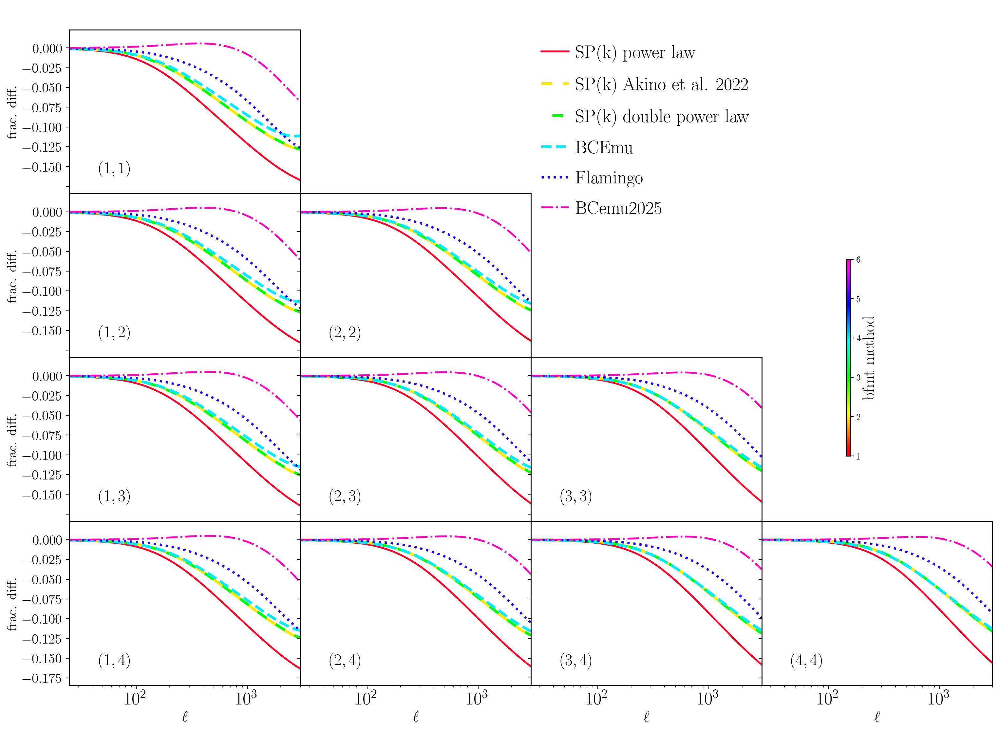

In [36]:
def fitted_ratio_band(curves, reference, keep):
    """Return the ratio band (lo, hi) that fits every plotted curve.

    The shared plotters draw value/reference - 1 and read their ylim as
    multipliers around 1: ylim = (0.8, 1.05) draws -0.2 to 0.05. The
    band runs from the most negative to the most positive
    value/reference - 1 over every curve, every panel (the bin pairs
    i <= j of the lower triangle) and the kept rows; it keeps 0 inside
    and adds 10% of its span on each side.

    Arguments:
      curves    = list of arrays [n_x, n_bin, n_bin], one per method.
      reference = array [n_x, n_bin, n_bin], the no-feedback prediction.
      keep      = boolean array [n_x], True on the plotted multipoles
                  or angles.

    Returns:
      (lo, hi): the band as multipliers around 1, for ylim.
    """
    lowest = 0.0
    highest = 0.0
    n_bin = reference.shape[1]
    for curve in curves:
        for i in range(n_bin):
            for j in range(i, n_bin):
                # curve[keep, i, j] = the kept rows of bin pair (i, j)
                ratio = curve[keep, i, j]/reference[keep, i, j] - 1.0
                lowest = min(lowest, float(np.min(ratio)))
                highest = max(highest, float(np.max(ratio)))
    margin = 0.1*(highest - lowest)
    return (1.0 + lowest - margin, 1.0 + highest + margin)


# param only orders the curve colors, one value per method; the legend
# names the methods.
param = np.arange(1.0, 1.0 + len(labels))

# One line style and width per method, in the order of labels. The
# plotters step through these lists once per curve in every panel, so
# with one entry per method each method keeps its style everywhere. The
# colormap gives the SP(k) Akino relation yellow and BCEmu cyan, the two
# light colors: they get dashes and wide lines. The Akino and double
# power law curves nearly coincide, so they share one dash pattern,
# shifted for the second by one dash length: in (offset, (on, off)) the
# lengths are in units of the line width (matplotlib scales dashes by
# it), both curves have width 3, and the shifted green dashes fill the
# gaps of the yellow ones.
method_linestyle = ["solid",
                    (0, (4, 4)),
                    (4, (4, 4)),
                    "dashed",
                    "dotted",
                    "dashdot"]
method_linewidth = [2.0, 3.0, 3.0, 3.0, 2.5, 2.0]

C_ss_list = [results[label]["C_ss"] for label in labels]
# the multipoles inside the plotted range (all of the default
# np.arange(25, 3000, 15) of compute_probes)
in_ell_range = (ref["ell"] >= 25.0) & (ref["ell"] <= 3000.0)
C_ss_band = fitted_ratio_band(curves=C_ss_list,
                              reference=ref["C_ss"],
                              keep=in_ell_range)

cnu.plot_C_ss_tomo_limber(ell=ref["ell"],
                          C_ss=C_ss_list,
                          C_ss_ref=ref["C_ss"],
                          param=param,
                          lmin=25,
                          lmax=3000,
                          ylim=C_ss_band,
                          colorbarlabel="bfmt method",
                          legend=labels,
                          linestyle=method_linestyle,
                          linewidth=method_linewidth,
                          figsize=(18, 13),
                          legendloc=(0.54, 0.70),
                          legendfontsize=20,
                          bintextpos=[0.2, 0.15],
                          bintextsize=18,
                          xaxisticklabelsize=20,
                          yaxisticklabelsize=15,
                          yaxislabelsize=15)

### Cosmic shear with feedback: $\xi_\pm(\theta)$

The same comparison in real space, first $\xi_+$ and then $\xi_-$ (`cnu.plot_xi` draws one of the two per figure), over the angles the mask keeps, $2.5'\le\theta\le250'$. Each figure has its own band, fitted as for $C_\ell^{EE}$ to the angular bins inside that range. Feedback reaches larger angles in $\xi_-$, which weights smaller physical scales than $\xi_+$ at the same angle.

The figures leave out the CMB lensing × shear predictions: `results[label]["C_ks"]` and `results[label]["w_ks"]` hold them for each method, and `ref["C_ks"]` and `ref["w_ks"]` the feedback-free ones.

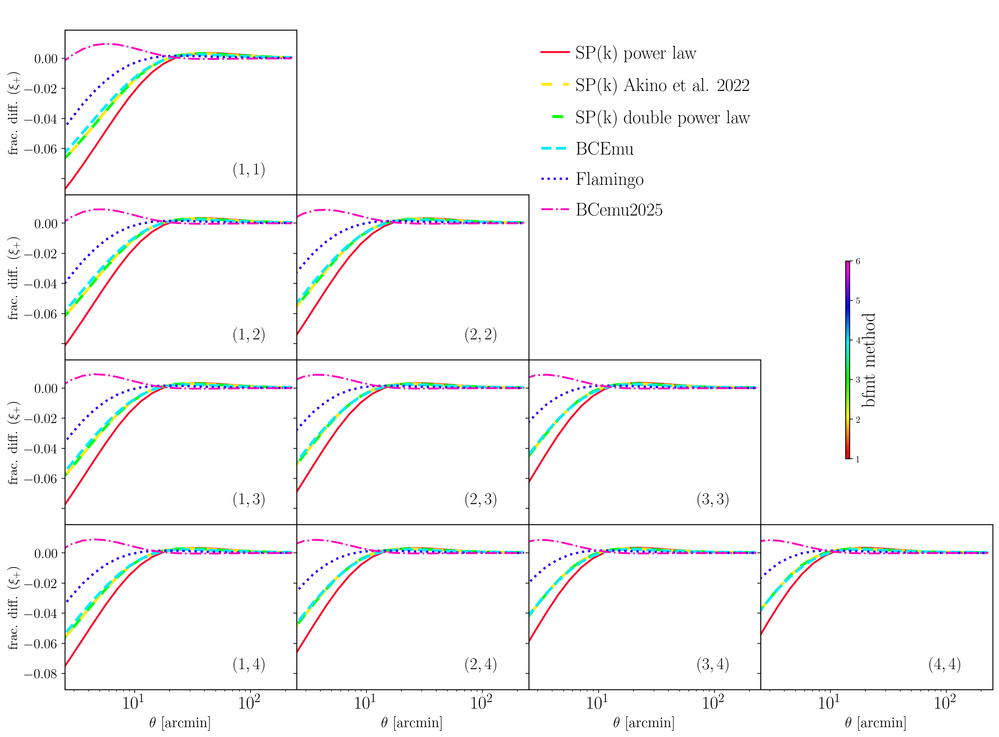

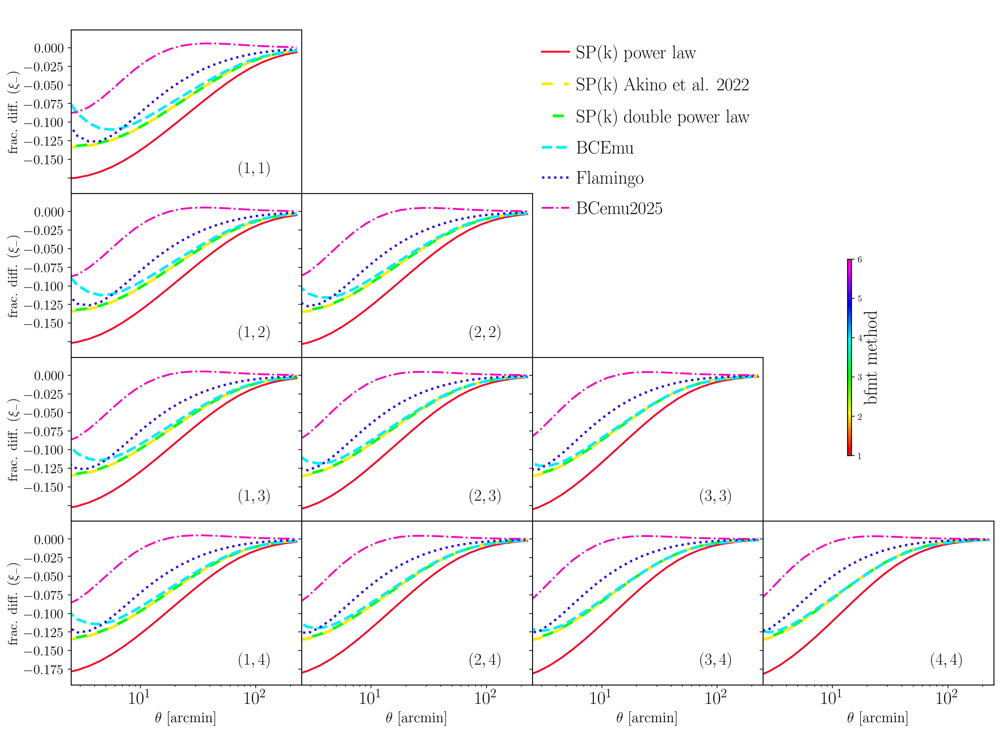

In [37]:
# Each entry is the (theta, xi_plus, xi_minus) tuple that plot_xi expects.
xi_list = [(results[label]["theta"], results[label]["xip"],
            results[label]["xim"]) for label in labels]
xi_ref = (ref["theta"], ref["xip"], ref["xim"])
# the angular bins the mask keeps: centers from 2.84 to 225 arcmin
in_theta_range = (ref["theta"] >= 2.5) & (ref["theta"] <= 250.0)

xip_list = [results[label]["xip"] for label in labels]
xip_band = fitted_ratio_band(curves=xip_list,
                             reference=ref["xip"],
                             keep=in_theta_range)
cnu.plot_xi(pm=1,
            xi=xi_list,
            xi_ref=xi_ref,
            param=param,
            ylim=xip_band,
            colorbarlabel="bfmt method",
            legend=labels,
            linestyle=method_linestyle,
            linewidth=method_linewidth,
            figsize=(18, 13),
            thetashow=[2.5, 250],
            legendloc=(0.54, 0.70),
            legendfontsize=20,
            bintextpos=[[0.8, 0.15], [0.8, 0.15]],
            bintextsize=18,
            xaxisticklabelsize=20,
            yaxisticklabelsize=15,
            yaxislabelsize=15)

# pm <= 0 draws xi_minus, with its own fitted band
xim_list = [results[label]["xim"] for label in labels]
xim_band = fitted_ratio_band(curves=xim_list,
                             reference=ref["xim"],
                             keep=in_theta_range)
cnu.plot_xi(pm=0,
            xi=xi_list,
            xi_ref=xi_ref,
            param=param,
            ylim=xim_band,
            colorbarlabel="bfmt method",
            legend=labels,
            linestyle=method_linestyle,
            linewidth=method_linewidth,
            figsize=(18, 13),
            thetashow=[2.5, 250],
            legendloc=(0.54, 0.70),
            legendfontsize=20,
            bintextpos=[[0.8, 0.15], [0.8, 0.15]],
            bintextsize=18,
            xaxisticklabelsize=20,
            yaxisticklabelsize=15,
            yaxislabelsize=15)

## How the accuracy settings change $C_\ell^{EE}$ and $\xi_\pm(\theta)$

Every wrapper accepts four accuracy arguments:

| Argument | What it refines |
| --- | --- |
| `AccuracyBoost` | Both codes at once: CAMB receives $1+(\mathrm{AccuracyBoost}-1)/3$, and the CosmoLike boost is multiplied by `AccuracyBoost`. |
| `CAMBAccuracyBoost` | CAMB only: its internal accuracy, its maximum wavenumber and wavenumber sampling, and the redshift sampling of the distance table. |
| `CLAccuracyBoost` | CosmoLike only: its interpolation tables, the redshift and wavenumber grids of the power-spectrum tables, and the highest multipole of the $C_\ell$ table. |
| `CLIntegrationAccuracy` | CosmoLike's quadrature rules, the level of numerical integration. |

The wrappers add $|3(\mathrm{CLAccuracyBoost}-1)|$ to the integration level, so raising the CosmoLike boost also refines the integrals. The first figures change only the CosmoLike settings, `CLAccuracyBoost = 1 + x` and `CLIntegrationAccuracy = int(x)`; the later ones change only CAMB, `CAMBAccuracyBoost = 1 + x/3`. The colorbars, labeled "Accuracy Boost", show $x$. Each reference uses boost 1 and integration level 0, so a curve shows how far the default settings are from a refined calculation of that quantity. The $\chi^2$ sections below express such changes as $\Delta\chi^2$, the measure the project tests use.

In [38]:
lmin = 100.
lmax = 6500.
ell = np.arange(lmin, lmax, 30.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
# The colorbar shows x: CLAccuracyBoost = 1 + x and CLIntegrationAccuracy
# = int(x), to which the wrapper adds |3 (CLAccuracyBoost - 1)|.
param = np.arange(1.0, 10.0, 0.5)
C_ss = []
for x in param:
    # Change only Cosmolike Settings
    (Cl, tmp) = nw.C_ss_tomo_limber(ell=ell, AccuracyBoost=1,CAMBAccuracyBoost=1.,CLAccuracyBoost=1+x,CLIntegrationAccuracy=int(x))
    C_ss.append(Cl)
# Plot the Ratio over ref cosmology
(C_ss_ref, tmp) = nw.C_ss_tomo_limber(ell=ell,CAMBAccuracyBoost=1.,CLAccuracyBoost=1,CLIntegrationAccuracy=0)

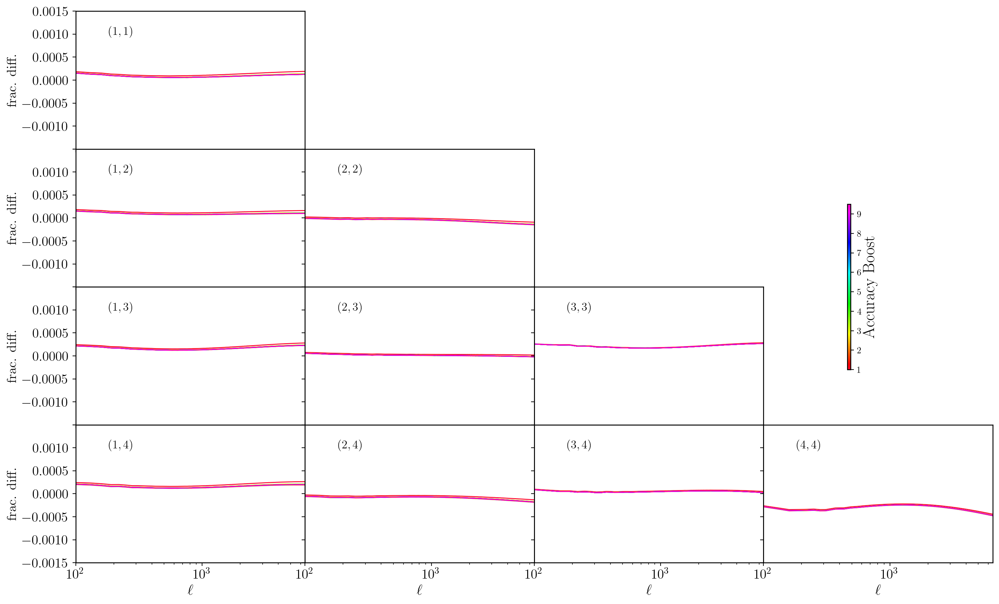

In [39]:
cnu.plot_C_ss_tomo_limber(ell=ell,
                          C_ss=C_ss,
                          C_ss_ref=C_ss_ref,
                          param=param,
                          lmin=lmin,
                          lmax=lmax,
                          ylim=(0.9985,1.0015),
                          colorbarlabel="Accuracy Boost",
                          yaxislabelsize = 15,
                          xaxisticklabelsize=15,
                          yaxisticklabelsize=15,
                          figsize = (18, 11),
                          wspace=0.4)

In [40]:
# x = 0 repeats the reference settings: its curve lies on zero, a check
# of the comparison itself.
param = np.arange(0,10.0,1.0)
xi_theta_ref = nw.xi(ntheta=40,AccuracyBoost=1,CAMBAccuracyBoost=1.,CLAccuracyBoost=1,CLIntegrationAccuracy=0)
xi_theta = []
for x in param:
    xi_theta.append(nw.xi(ntheta=40,AccuracyBoost=1,CAMBAccuracyBoost=1.,CLAccuracyBoost=1+x,CLIntegrationAccuracy=int(x)))

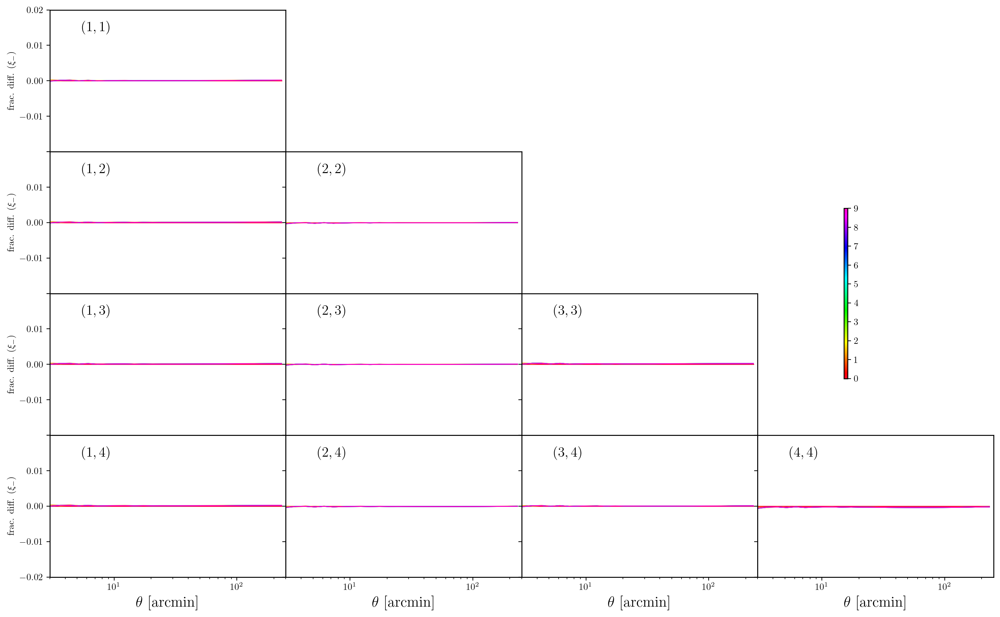

In [41]:
# pm <= 0 draws xi_minus; the next cell draws xi_plus.
cnu.plot_xi(pm=0,
            xi=xi_theta,
            xi_ref=xi_theta_ref,
            param=param,
            ylim=(0.98,1.02),
            yaxislabelsize = 10,
            xaxisticklabelsize=10,
            yaxisticklabelsize=10,
            figsize = (18, 11),
            wspace=0.4)

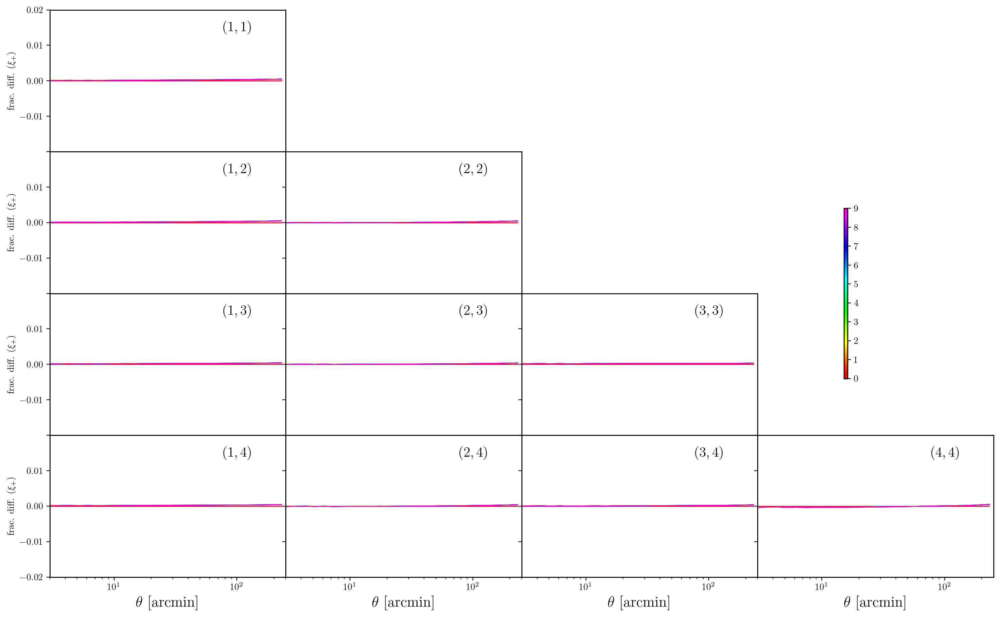

In [42]:
cnu.plot_xi(pm=1,
            xi=xi_theta,
            xi_ref=xi_theta_ref,
            param=param,
            ylim=(0.98,1.02),
            yaxislabelsize = 10,
            xaxisticklabelsize=10,
            yaxisticklabelsize=10,
            figsize = (18, 11),
            wspace=0.4)

In [43]:
lmin = 100.
lmax = 6500.
ell = np.arange(lmin, lmax, 30.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
# CAMBAccuracyBoost = 1 + x/3 also raises CAMB's maximum wavenumber and
# its k sampling (help(cnu.get_camb_cosmology)); the colorbar shows x.
param = np.arange(1.,6.0,1.0)
C_ss = []
for x in param:
    # Change only CAMB Settings
    (Cl, tmp) = nw.C_ss_tomo_limber(ell=ell, AccuracyBoost=1,CAMBAccuracyBoost=1.+x/3,CLAccuracyBoost=1,CLIntegrationAccuracy=0)
    C_ss.append(Cl)
# Plot the Ratio over ref cosmology
(C_ss_ref, tmp) = nw.C_ss_tomo_limber(ell=ell,CAMBAccuracyBoost=1.,CLAccuracyBoost=1,CLIntegrationAccuracy=0)

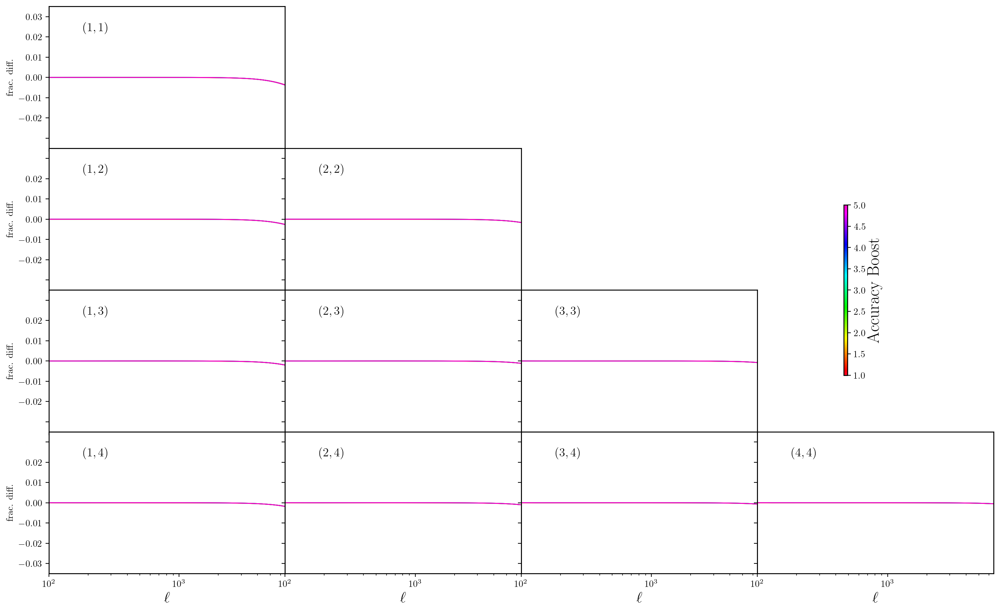

In [44]:
cnu.plot_C_ss_tomo_limber(ell=ell,
                          C_ss=C_ss,
                          C_ss_ref=C_ss_ref,
                          param=param,
                          lmin=lmin,
                          lmax=lmax,
                          ylim=(0.965,1.035),
                          colorbarlabel="Accuracy Boost",
                          yaxislabelsize = 10,
                          xaxisticklabelsize=10,
                          yaxisticklabelsize=10,
                          figsize = (18, 11),
                          wspace=0.4)

In [45]:
param = np.arange(1.,6.0,1.0)
xi_theta_ref = nw.xi(ntheta=40,AccuracyBoost=1,CAMBAccuracyBoost=1.,CLAccuracyBoost=1,CLIntegrationAccuracy=0)
xi_theta = []
for x in param:
    xi_theta.append(nw.xi(ntheta=40,AccuracyBoost=1,CAMBAccuracyBoost=1+x/3,CLAccuracyBoost=1,CLIntegrationAccuracy=0))

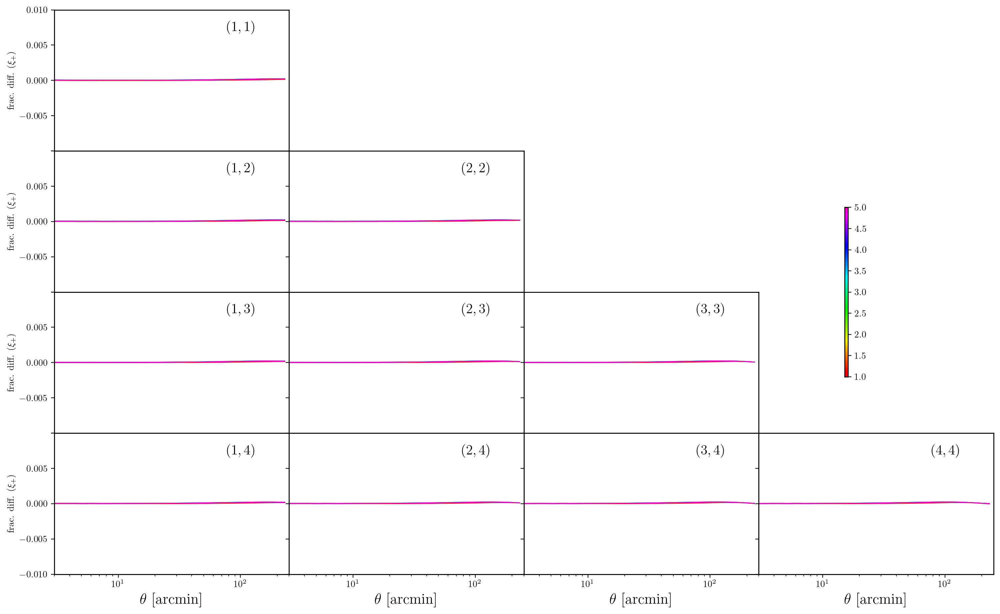

In [46]:
cnu.plot_xi(pm = 1,
            xi = xi_theta,
            xi_ref = xi_theta_ref,
            param=param,
            ylim=(0.99, 1.01),
            yaxislabelsize = 10,
            xaxisticklabelsize=10,
            yaxisticklabelsize=10,
            figsize = (18, 11),
            wspace=0.4)

## The cosmic-shear $\chi^2$ of DES Y3 × Planck PR4

`nw.init_cosmolike(CLprobe="xi", with_data=True)` repeats the initialization, selects the cosmic-shear probe and loads the measured data vector, the covariance and the mask named in the dataset file. The *mask* holds one 0/1 flag per data-vector entry and applies the analysis scale cuts. Together with the probe selection it keeps 400 entries, 200 of $\xi_+$ and 200 of $\xi_-$. `nw.get_chi2` then computes

$$\chi^2=(\mathbf d-\mathbf t)^{\mathsf T}\,\mathbf C^{-1}\,(\mathbf d-\mathbf t),$$

where $\mathbf d$ holds the measurements, $\mathbf t$ the prediction and $\mathbf C$ the supplied covariance, all restricted to the retained entries. `nw.get_chi2(omegam = 0.3)` evaluates the fiducial point, which matches the `override` block of [EXAMPLE_EVALUATE1.yaml](EXAMPLE_EVALUATE1.yaml). That YAML's CAMB block (`kmax: 10`, `k_per_logint: 12`) differs from the notebook's CAMB call (`kmax = 7.5`, `k_per_logint = 10`), so the notebook and the Cobaya run need not agree in every digit. The scan shows how quickly $\chi^2$ changes with $\Omega_m$ between 0.295 and 0.304.

In [47]:
# Re-init with the chi2 machinery: probes, covariance, mask, and
# data vector (nw.init_cosmolike holds the full sequence)
# CLprobe="xi" activates the cosmic-shear blocks only: xi_plus, xi_minus.
ini = nw.init_cosmolike(CLprobe="xi", with_data=True)
allsims = nw.allsims

In [48]:
nw.get_chi2(omegam = 0.3)

748.474630652965

In [49]:
param = np.arange(0.295, 0.305, 0.001)      
chi2 = []
for x in param:
    chi2.append(nw.get_chi2(omegam = x))

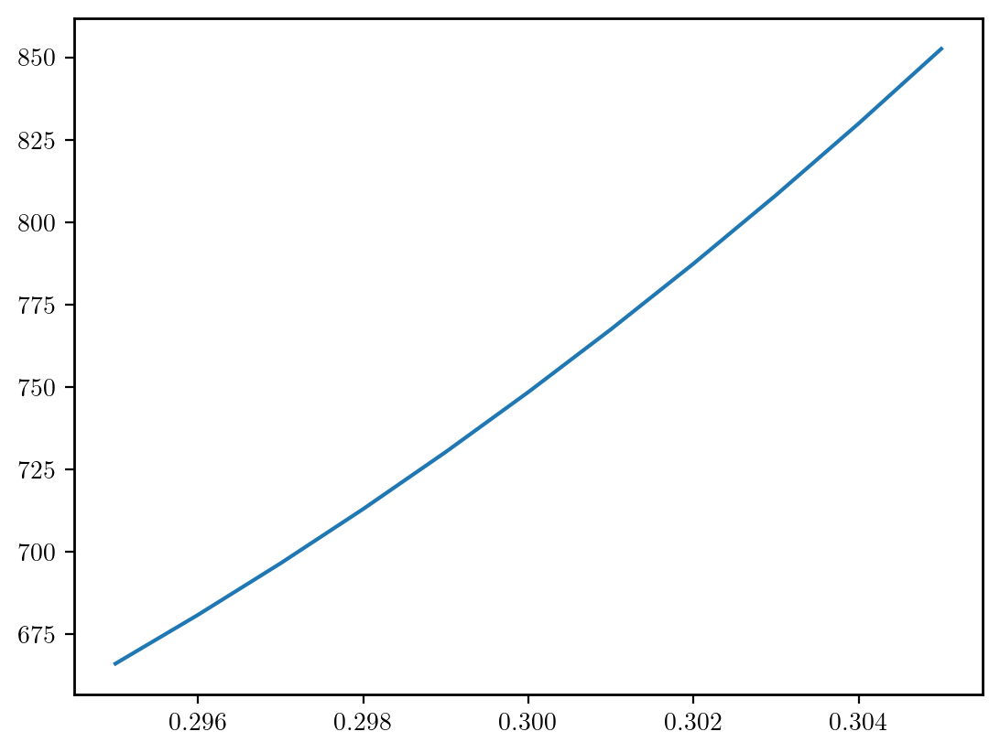

In [50]:
plt.plot(param, chi2)

## $\chi^2$ as a function of the CAMB and CosmoLike accuracy

Both sweeps raise CAMB and CosmoLike together through one variable $x$. The first sets `CAMBAccuracyBoost = 1 + x/3` and `CLAccuracyBoost = 1 + x` at base integration level 1; the second sets `AccuracyBoost = 1 + x`, which applies the same two boosts at base integration level 0. Each figure plots $\chi^2(x)-\chi^2(x_\mathrm{max})$, the change relative to the most accurate setting of the sweep.

These $\chi^2$ values use the real measurements, and the fiducial point is not their best fit. There $\chi^2$ responds linearly to small changes in the prediction, so a shift measures the slope of $\chi^2$ as much as the numerical error. The project tests therefore measure accuracy against a synthetic data vector computed at the fiducial point; see the [data-vector test guide](tests/data_vector/README.md#synthetic_vectors). Compare the shifts with the 0.2 band in $\Delta\chi^2$ that the reference tests allow.

In [51]:
# One variable x raises CAMB (1 + x/3) and CosmoLike (1 + x) together, at
# integration level 1.
param = np.arange(0., 6., 0.5)      
chi2 = []
for x in param:
    chi2.append(nw.get_chi2(AccuracyBoost = 1, CAMBAccuracyBoost = 1.+ x/3.0, CLAccuracyBoost = 1 + x, CLIntegrationAccuracy = 1))
chi2 = np.array(chi2)

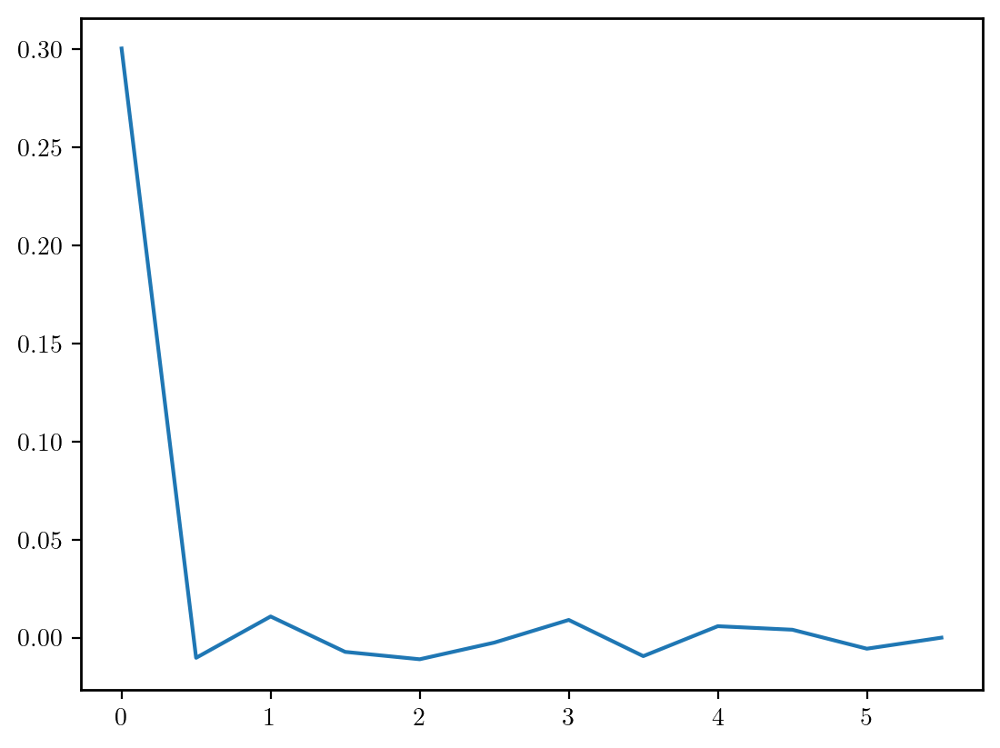

In [52]:
# Change relative to the most accurate setting, the last of the sweep.
plt.plot(param, np.array(chi2 - chi2[-1]))

In [53]:
# AccuracyBoost = 1 + x applies the same CAMB (1 + x/3) and CosmoLike
# (1 + x) boosts as the previous sweep; only the base integration level
# differs (0 here, 1 there).
param = np.arange(0, 6, 0.5)      
chi2 = []
for x in param:
    chi2.append(nw.get_chi2(AccuracyBoost = 1 + x))
chi2 = np.array(chi2)

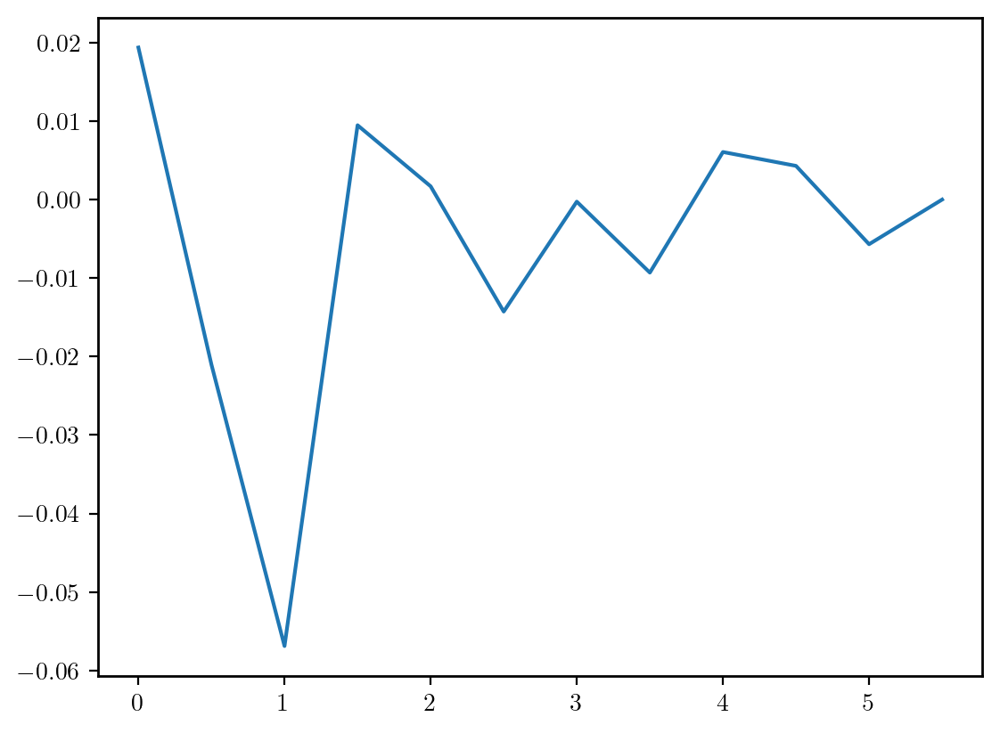

In [54]:
plt.plot(param, np.array(chi2 - chi2[-1]))

## Halofit versus EuclidEmulator2

`non_linear_emul` selects the nonlinear matter power spectrum. The value 2, the default here, uses CAMB's Halofit fitting formula in its Takahashi version. The value 1 multiplies the linear spectrum by the nonlinear boost of EuclidEmulator2, an emulator trained on N-body simulations, below $z=10$, and keeps Halofit above. The first cell prints the cosmic-shear $\chi^2$ for each choice.

The $C_\ell^{EE}$ figure shows $C^\mathrm{Halofit}/C^\mathrm{EE2}-1$. The $\xi_+$ figure divides the other way, $\xi_+^\mathrm{EE2}/\xi_+^\mathrm{Halofit}-1$, and its EuclidEmulator2 curve uses `CAMBAccuracyBoost` $=4/3$, so that comparison also contains a CAMB accuracy change.

In [55]:
# non_linear_emul = 1 uses EuclidEmulator2, 2 uses CAMB's Halofit.
print(rf"$\chi^2$={nw.get_chi2(non_linear_emul=1):3.3f}")
print(rf"$\chi^2$={nw.get_chi2(non_linear_emul=2):3.3f}")

/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/.local/lib/python3.11/site-packages/euclidemu2/ee2_bindata.dat
$\chi^2$=723.060


$\chi^2$=748.475


In [56]:
lmin = 100.
lmax = 6500.
ell = np.arange(lmin, lmax, 20.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
param = [1]
C_ss = []
for x in param:
    # Halofit (non_linear_emul=2); the reference below uses EuclidEmulator2.
    (Cl, tmp) = nw.C_ss_tomo_limber(ell=ell, AccuracyBoost=1,CAMBAccuracyBoost=1.,CLAccuracyBoost=1,CLIntegrationAccuracy=0,non_linear_emul=2)
    C_ss.append(Cl)
(C_ss_ref, tmp) = nw.C_ss_tomo_limber(ell=ell,CAMBAccuracyBoost=1.,CLAccuracyBoost=1,CLIntegrationAccuracy=0,non_linear_emul=1)

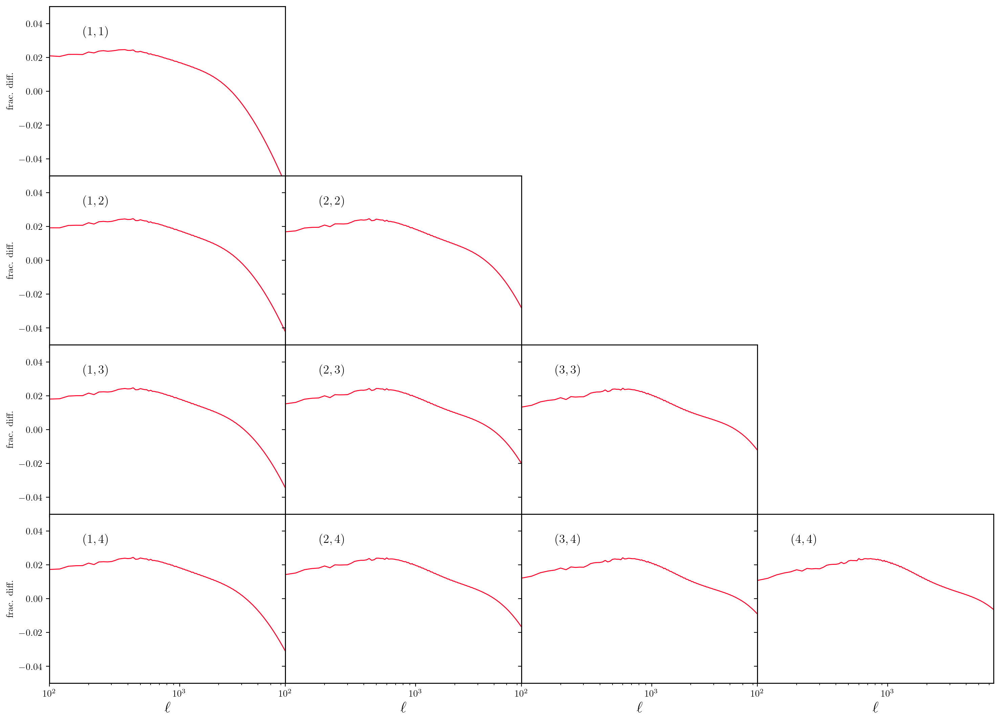

In [57]:
# Halofit / EuclidEmulator2 - 1; one curve, so no colorbar is drawn.
cnu.plot_C_ss_tomo_limber(ell=ell,
                          C_ss=C_ss,
                          C_ss_ref=C_ss_ref,
                          param=param,
                          lmin=lmin,
                          lmax=lmax,
                          ylim=(0.95,1.05),
                          colorbarlabel="Accuracy Boost",
                          colorbar=None,
                          yaxislabelsize = 10,
                          xaxisticklabelsize=10,
                          yaxisticklabelsize=10,
                          figsize = (18, 13),
                          wspace=0.3)

In [58]:
# Roles reversed relative to the C_ell figure: the reference is Halofit
# and the curve EuclidEmulator2, computed with CAMBAccuracyBoost = 1 + 1/3,
# so this ratio also contains a CAMB accuracy change.
param = [1]
xi_theta_ref = nw.xi(ntheta=40,AccuracyBoost=1,CAMBAccuracyBoost=1.,CLAccuracyBoost=1,CLIntegrationAccuracy=0,non_linear_emul=2)
xi_theta = []
for x in param:
    xi_theta.append(nw.xi(ntheta=40,AccuracyBoost=1,CAMBAccuracyBoost=1+x/3,CLAccuracyBoost=1,CLIntegrationAccuracy=0,non_linear_emul=1))

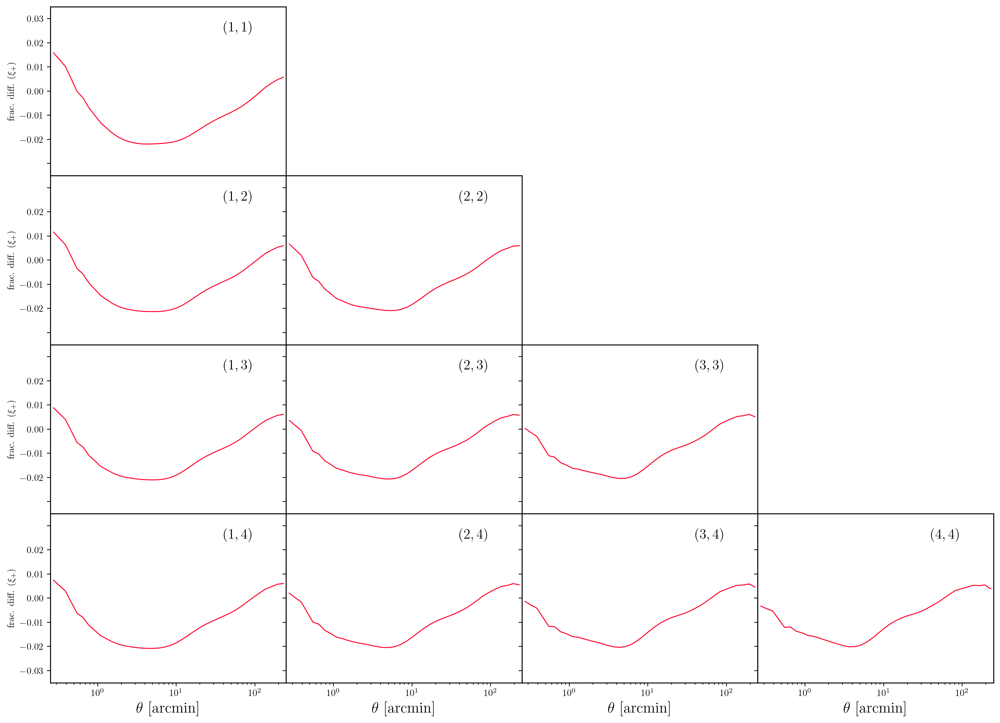

In [59]:
cnu.plot_xi(pm = 1,
            xi = xi_theta,
            xi_ref = xi_theta_ref,
            param=param,
            ylim=(0.965, 1.035),
            colorbar=None,
            yaxislabelsize = 10,
            xaxisticklabelsize=10,
            yaxisticklabelsize=10,
            figsize = (18, 13),
            thetashow=[0.25,250],
            wspace=0.3)

<!-- DRAFT: Fable rewrites -->
## Forecast parameter errors with Fisher matrices

Facts for the text (draft):

- A Fisher matrix approximates the likelihood as a Gaussian around the fiducial point: $F=D^{\mathsf T}C^{-1}D$, where column $p$ of $D$ is the derivative of the masked data vector with respect to parameter $p$ and $C^{-1}$ is the masked inverse covariance (`ci.get_inv_cov_masked()`); $F^{-1}$ is the forecast parameter covariance. The data vector is the cosmic-shear selection of the $\chi^2$ section, `CLprobe="xi"`: the 400 $\xi_\pm$ entries the mask keeps.
- The parameter vector holds the 17 entries of `nw.FISHER_PARAM_NAMES`: $10^9A_s$, $n_s$, $H_0$, $\Omega_b$, $\Omega_m$; the dark-energy pair $w_0$, $w_a$ of $w(a)=w_0+w_a(1-a)$, fiducial $(-1, 0)$; the two NLA parameters $A_\mathrm{IA}$, $\eta_\mathrm{IA}$; the four source photo-z shifts; the four shear calibrations. The likelihood samples $w$ and $w_0+w_a$; the Fisher vector holds $w_0$ and $w_a$, so the dark-energy figure of merit reads two of its entries. $m_\nu=0.06$ eV is fixed.
- Gaussian priors of `params_source.yaml` add $1/\sigma^2$ to the diagonal of $F$: $\sigma=0.018$, 0.015, 0.011, 0.017 on the photo-z shifts and 0.0091, 0.0078, 0.0076, 0.0076 on the shear calibrations. The flat priors of the yaml only clip the sample clouds of the contour plots.
- The figure of merit of a pair is $\mathrm{FoM}=1/\sqrt{\det C_2}$, with $C_2$ the pair's $2\times2$ block of $F^{-1}$, so the other 15 parameters are marginalized. The cells report FoM($w_0$, $w_a$) (indices 5 and 6) and FoM($10^9A_s$, $\Omega_m$) (indices 0 and 4). The contour plots show indices 0–8.
- Cosmic shear alone constrains $w_0$ and $w_a$ weakly: the Gaussian forecast of the pair reaches far past the flat priors, where an MCMC posterior would be cut. The Fisher matrix here tests the derivative machinery; it is not a statement about the posterior.
- Each five-point Fisher matrix takes four data-vector evaluations per parameter, 68 CAMB + CosmoLike runs. The section evaluates 884 five-point data vectors (1 + 4 matrices in the `AccuracyBoost` test, 8 in the step test) plus derivkit's own samples. One data vector takes 0.7 s at `AccuracyBoost` = 1 and 5.7 s at 5 (M2 laptop, 10 OpenMP threads; peak memory about 7 GB at 5). Measured section times: first matrix 44 s, `AccuracyBoost` test 16 min, step test 23 min, derivkit 7.5 min; the FoM-noise subsection 9 min; the whole notebook 61 min.
- No MCMC chain of this project ships with the repository, so the comparison at the end is stencil versus derivkit only (roman_real also overlays a chain).
- Finite differences need CAMB's halofit tolerance patch (the comment in the next cell).

In [60]:
# DRAFT comments (Fable rewrites the final text).
# ---------------------------------------------------------------------------
# Fisher derivatives and CAMB's halofit
# ---------------------------------------------------------------------------
# The Fisher matrices below take five-point-stencil derivatives of the
# data vector: they difference it between nearby cosmologies. Stock
# CAMB's halofit stops its bisection for the nonlinear scale at
# |sigma(R) - 1| <= 1e-3, and where it stops jumps between nearby
# cosmologies: the nonlinear P(k) of whole redshift slices shifts by
# ~0.3%, and the figure of merit moves with the step h. The halofit
# tolerance patch stops the bisection at 1e-7 instead. A fresh install
# applies it (PATCH_CAMB_HALOFIT_TOLERANCE=1 in set_installation_options.sh);
# an existing CAMB gets it only when re-cloned (export
# OVERWRITE_EXISTING_CAMB_CODE=1, then source
# installation_scripts/setup_camb.sh and installation_scripts/compile_camb.sh).
# The patched source shows a !VM block in the bisection of
# external_modules/code/CAMB/fortran/halofit.f90.
# ---------------------------------------------------------------------------
# The Fisher machinery is shared: the generic pieces live in
# cosmolike_core (cnu.get_Fisher, cnu.get_FoM, ...), and this project's
# data vector, fiducial vector, priors and labels live in the wrappers
# module (nw.get_dv, nw.FISHER_PARAM_NAMES, ...).
import time

# Re-init with the chi2 machinery (probes, covariance, mask, data vector);
# CLprobe="xi" keeps the cosmic-shear blocks xi_plus and xi_minus only.
ini = nw.init_cosmolike(CLprobe="xi", with_data=True)
param = nw.fisher_fiducial_point()
param_names = nw.FISHER_PARAM_NAMES
flat_priors = nw.FISHER_FLAT_PRIORS
invcov = ci.get_inv_cov_masked()
# the two figure-of-merit pairs: (w0, wa) and (10^9 A_s, Omega_m)
iw0 = nw.FISHER_W0_INDEX
iwa = nw.FISHER_WA_INDEX
iAs = 0
iOm = 4
# the parameters the contour plots show: the five cosmological
# parameters, w0, wa and the two NLA parameters (indices 0-8); the
# photo-z shifts and shear calibrations are marginalized
sel = [0, 1, 2, 3, 4, 5, 6, 7, 8]
# number of data-vector evaluations of one five-point Fisher matrix
n_eval_fisher = 4*len(param)

<!-- DRAFT: Fable rewrites -->
### A first Fisher matrix

Facts for the text (draft):

- `nw.get_Fisher` differentiates with the five-point stencil
$$f'(p)\approx\frac{-f(p+2\delta)+8f(p+\delta)-8f(p-\delta)+f(p-2\delta)}{12\,\delta},\qquad\delta=h\,p,$$
a relative step that becomes absolute ($\delta=h$) when the fiducial value is zero: $w_a$ and the four photo-z shifts.
- This first matrix uses the likelihood's default accuracy, `AccuracyBoost` = 1, and $h=0.03$. It is the base of the FoM-noise estimate after the Fisher section.
- The cell prints the marginalized error $\sigma_p=\sqrt{(F^{-1})_{pp}}$ of every parameter and the two figures of merit. Numbers: 68 data vectors in 44 s; FoM($w_0$, $w_a$) = 0.102 and FoM($10^9A_s$, $\Omega_m$) = 0.891; $\sigma(w_0)=2.9$, $\sigma(w_a)=10.0$, $\sigma(\Omega_m)=0.27$, $\sigma(10^9A_s)=4.2$. $\sigma(H_0)=156$, $\sigma(\Omega_b)=0.25$ and $\sigma(n_s)=0.30$ lie far beyond the flat priors: cosmic shear alone hardly constrains them, and the Fisher matrix carries no Gaussian prior on them (as in roman_real and lsst_y1). The shear calibrations and photo-z shifts stay at their prior widths.

In [61]:
# DRAFT comments (Fable rewrites the final text).
# h: relative stencil step (absolute for wa and the photo-z shifts, whose
# fiducial is 0). AccuracyBoost = 1 is the likelihood's default accuracy.
h_base = 0.03
AB_base = 1.0
t0 = time.time()
F_base = nw.get_Fisher(CV=param, h=h_base, AccuracyBoost=AB_base)
time_base = time.time() - t0
# marginalized errors: the square roots of the diagonal of F^-1
sigma_base = np.sqrt(np.diag(np.linalg.inv(F_base)))
print("%d data vectors in %.0f s" % (n_eval_fisher, time_base))
print("%-10s %12s %12s" % ("parameter", "fiducial", "sigma"))
for p in range(len(param)):
    print("%-10s %12.5g %12.5g" % (param_names[p], param[p], sigma_base[p]))
print("FoM(w0, wa)            = %.4g" % cnu.get_FoM(iw0, iwa, F_base))
print("FoM(10^9 A_s, Omega_m) = %.4g" % cnu.get_FoM(iAs, iOm, F_base))

68 data vectors in 61 s
parameter      fiducial        sigma
As_1e9              2.1       4.2216
ns              0.96605      0.30438
H0                67.32       156.16
omegab             0.04      0.24982
omegam              0.3      0.26592
w0                   -1       2.9441
wa                    0       9.9859
DES_A1_1           -0.7       1.6934
DES_A1_2           -1.7       4.6161
DES_DZ_S1             0     0.015873
DES_DZ_S2             0     0.012565
DES_DZ_S3             0     0.010212
DES_DZ_S4             0     0.015945
DES_M1          -0.0063    0.0090882
DES_M2          -0.0198    0.0076405
DES_M3          -0.0241    0.0073556
DES_M4          -0.0369    0.0074698
FoM(w0, wa)            = 0.1018
FoM(10^9 A_s, Omega_m) = 0.891


<!-- DRAFT: Fable rewrites -->
### Five-point-stencil derivatives: dependence on `AccuracyBoost`

Facts for the text (draft):

- The step stays at $h=0.03$ and `AccuracyBoost` runs over 1, 2, 3, 4 and 5; the first matrix is `F_base` of the previous cell. In `nw.get_dv`, `AccuracyBoost` reaches both codes: CAMB receives $1+(\mathrm{AccuracyBoost}-1)/3$, and the CosmoLike boost is `AccuracyBoost` squared (the convention of the roman_real and lsst_y1 wrappers).
- The line plot shows each figure of merit relative to the most accurate matrix, $100\,(\mathrm{FoM}/\mathrm{FoM}_\mathrm{ref}-1)$ with the reference at the largest `AccuracyBoost`, for FoM($w_0$, $w_a$) and FoM($10^9A_s$, $\Omega_m$). A FoM that keeps changing with the accuracy reveals numerical noise in the derivatives. The contour plot overlays the forecasts.
- Numbers: FoM($w_0$, $w_a$) = 0.1018, 0.1012, 0.1012, 0.1013, 0.1012 for `AccuracyBoost` = 1–5 (0.5% above the reference at 1, within 0.01% from 2); FoM($10^9A_s$, $\Omega_m$) = 0.891, 0.874, 0.871, 0.869, 0.869 (2.5% above the reference at 1, 0.5% at 2, within 0.25% from 3). Time per matrix: 44, 102, 181, 259, 373 s. The contours of the five matrices overlap.

In [62]:
# DRAFT comments (Fable rewrites the final text).
# One Fisher matrix per AccuracyBoost value at h = 0.03; the first is
# F_base of the previous cell, every further one costs 68 data vectors.
AB1 = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
F1 = [F_base]
time_AB = [time_base]
for x in AB1[1:]:
    t0 = time.time()
    F1.append(nw.get_Fisher(CV=param, h=h_base, AccuracyBoost=x))
    time_AB.append(time.time() - t0)
FOM1_w = np.zeros(len(AB1))
FOM1_As = np.zeros(len(AB1))
for i in range(len(AB1)):
    FOM1_w[i] = cnu.get_FoM(iw0, iwa, F1[i])
    FOM1_As[i] = cnu.get_FoM(iAs, iOm, F1[i])
print("%13s %13s %23s %9s" % ("AccuracyBoost", "FoM(w0, wa)",
                              "FoM(10^9 A_s, Omega_m)", "time [s]"))
for i in range(len(AB1)):
    print("%13.1f %13.4g %23.4g %9.0f" % (AB1[i], FOM1_w[i], FOM1_As[i],
                                         time_AB[i]))

AccuracyBoost   FoM(w0, wa)  FoM(10^9 A_s, Omega_m)  time [s]
          1.0        0.1018                   0.891        61
          2.0        0.1012                  0.8738       139
          3.0        0.1012                  0.8713       243
          4.0        0.1013                  0.8686       381
          5.0        0.1012                  0.8693       569


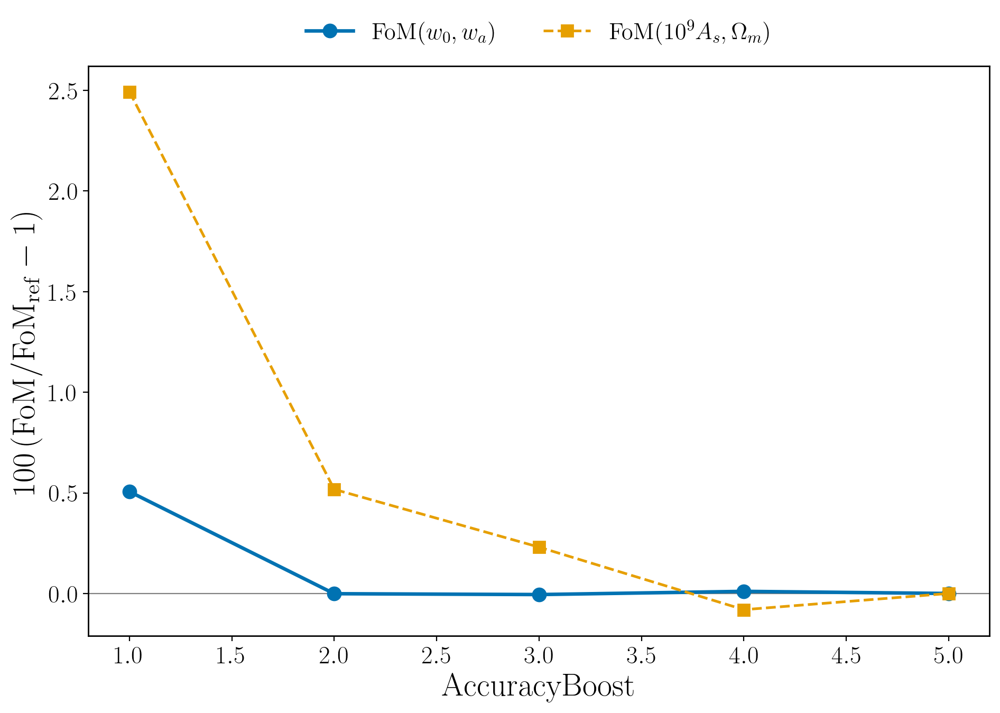

In [63]:
# DRAFT comments (Fable rewrites the final text).
# Each FoM relative to the most accurate matrix, the last of AB1, in
# percent. The two pairs differ in color, width, line style and marker;
# the legend sits above the axes, where it cannot cover a curve.
# colorblind-safe colors (blue, orange), one per pair
colors = ["#0072B2", "#E69F00"]
fig, ax = plt.subplots(figsize=(11, 7))
ax.axhline(0.0, color="gray", linewidth=0.8, zorder=0)
ax.plot(AB1, 100.0*(FOM1_w/FOM1_w[-1] - 1.0), color=colors[0],
        linewidth=2.4, linestyle="solid", marker="o", markersize=9,
        label=r"FoM$(w_0, w_a)$")
ax.plot(AB1, 100.0*(FOM1_As/FOM1_As[-1] - 1.0), color=colors[1],
        linewidth=1.8, linestyle="dashed", marker="s", markersize=8,
        label=r"FoM$(10^9 A_s, \Omega_m)$")
ax.set_xlabel("AccuracyBoost", fontsize=22)
ax.set_ylabel(r"$100\,({\rm FoM}/{\rm FoM}_{\rm ref} - 1)$", fontsize=22)
ax.tick_params(axis="both", labelsize=17)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncols=2,
          frameon=False, fontsize=16)
plt.show()

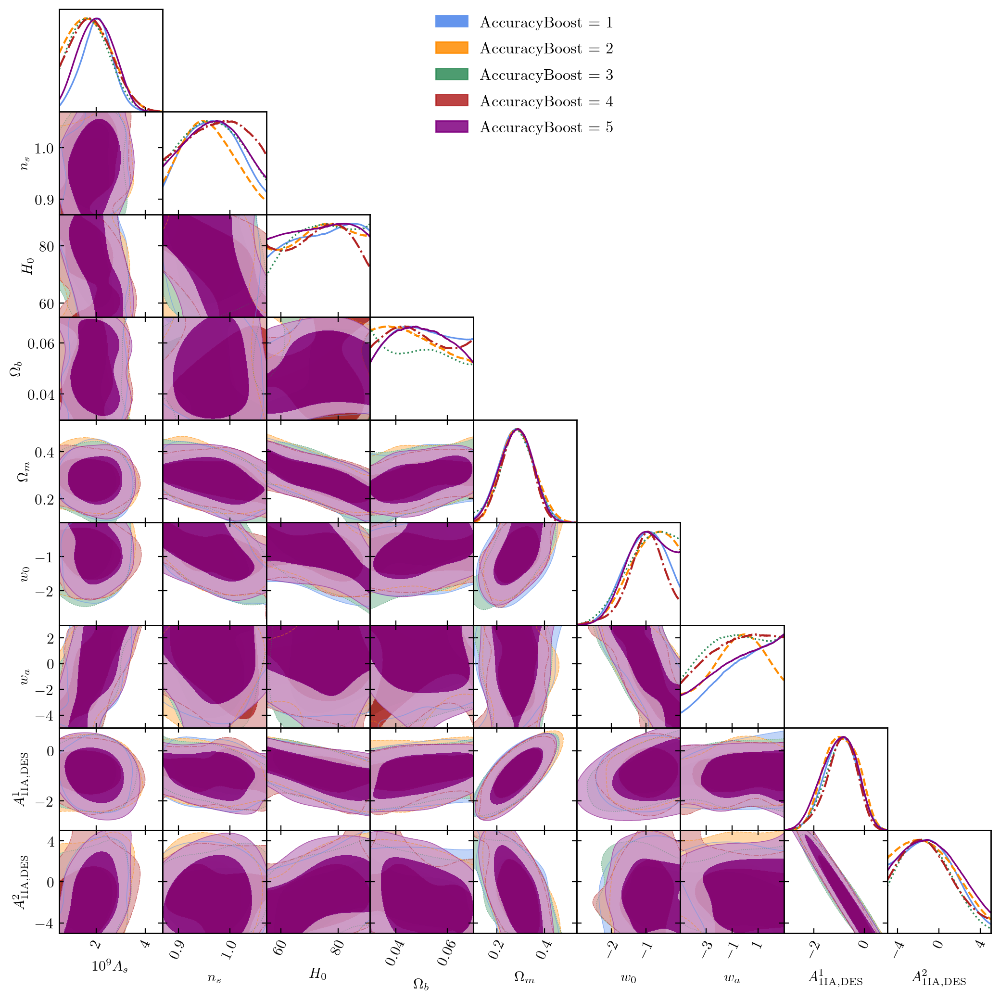

In [64]:
# The five cosmological parameters, w0, wa and the two NLA parameters;
# the eight photo-z and shear-calibration parameters are marginalized.
chain_names = []
for x in AB1:
    chain_names.append("AccuracyBoost = %g" % x)
g = nw.plot_Fisher(F=F1,
                   mu=param,
                   select=sel,
                   filled=True,
                   flat_priors=flat_priors,
                   chain_names=chain_names)

<!-- DRAFT: Fable rewrites -->
### Five-point-stencil derivatives: dependence on the step size

Facts for the text (draft):

- At `AccuracyBoost` = 3 the step $h$ runs from 0.02 to 0.09. A step that is too small amplifies numerical noise in the differences; a step that is too large picks up the curvature of the data vector. A plateau of the FoM over a range of $h$ marks a reliable derivative.
- The line plot shows each FoM relative to its mean over the steps, $100\,(\mathrm{FoM}/\langle\mathrm{FoM}\rangle_h-1)$, so a plateau is a flat line; the contour plot overlays the eight forecasts.
- Numbers: for $h=0.02$–0.09, FoM($w_0$, $w_a$) stays between 0.1003 and 0.1012 and FoM($10^9A_s$, $\Omega_m$) between 0.865 and 0.872, both within ±0.5% of their means: a plateau. 544 data vectors in 1383 s. For the photo-z shifts (fiducial 0) the steps are absolute, $h$ to $2h$ = 0.02–0.18, wider than their priors ($\sigma=0.011$–0.018).

In [65]:
# DRAFT comments (Fable rewrites the final text).
# One Fisher matrix per relative step h = 0.02, ..., 0.09.
AB_h = 3.0
hs2 = np.arange(0.02, 0.1, 0.01)
F2 = []
FOM2_w = np.zeros(len(hs2))
FOM2_As = np.zeros(len(hs2))
t0 = time.time()
for i in range(len(hs2)):
    F2.append(nw.get_Fisher(CV=param, h=hs2[i], AccuracyBoost=AB_h))
    FOM2_w[i] = cnu.get_FoM(iw0, iwa, F2[i])
    FOM2_As[i] = cnu.get_FoM(iAs, iOm, F2[i])
time_h = time.time() - t0
print("%d data vectors in %.0f s" % (len(hs2)*n_eval_fisher, time_h))
print("%6s %13s %23s" % ("h", "FoM(w0, wa)", "FoM(10^9 A_s, Omega_m)"))
for i in range(len(hs2)):
    print("%6.2f %13.4g %23.4g" % (hs2[i], FOM2_w[i], FOM2_As[i]))

544 data vectors in 1987 s
     h   FoM(w0, wa)  FoM(10^9 A_s, Omega_m)
  0.02        0.1011                  0.8706
  0.03        0.1012                  0.8713
  0.04         0.101                  0.8673
  0.05        0.1007                  0.8665
  0.06        0.1003                  0.8651
  0.07        0.1004                  0.8666
  0.08        0.1007                  0.8697
  0.09        0.1007                  0.8722


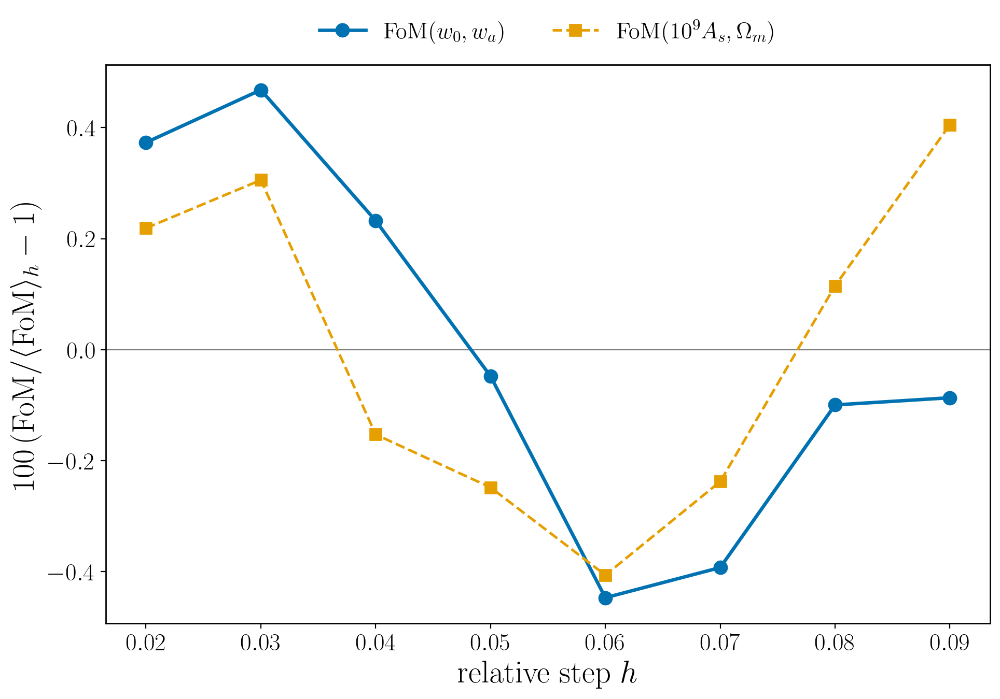

In [66]:
# DRAFT comments (Fable rewrites the final text).
# Each FoM relative to its mean over the steps, in percent: a plateau is
# a flat line. Colors and encodings as in the AccuracyBoost figure.
colors = ["#0072B2", "#E69F00"]
fig, ax = plt.subplots(figsize=(11, 7))
ax.axhline(0.0, color="gray", linewidth=0.8, zorder=0)
ax.plot(hs2, 100.0*(FOM2_w/np.mean(FOM2_w) - 1.0), color=colors[0],
        linewidth=2.4, linestyle="solid", marker="o", markersize=9,
        label=r"FoM$(w_0, w_a)$")
ax.plot(hs2, 100.0*(FOM2_As/np.mean(FOM2_As) - 1.0), color=colors[1],
        linewidth=1.8, linestyle="dashed", marker="s", markersize=8,
        label=r"FoM$(10^9 A_s, \Omega_m)$")
ax.set_xlabel(r"relative step $h$", fontsize=22)
ax.set_ylabel(r"$100\,({\rm FoM}/\langle{\rm FoM}\rangle_h - 1)$", fontsize=22)
ax.tick_params(axis="both", labelsize=17)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncols=2,
          frameon=False, fontsize=16)
plt.show()

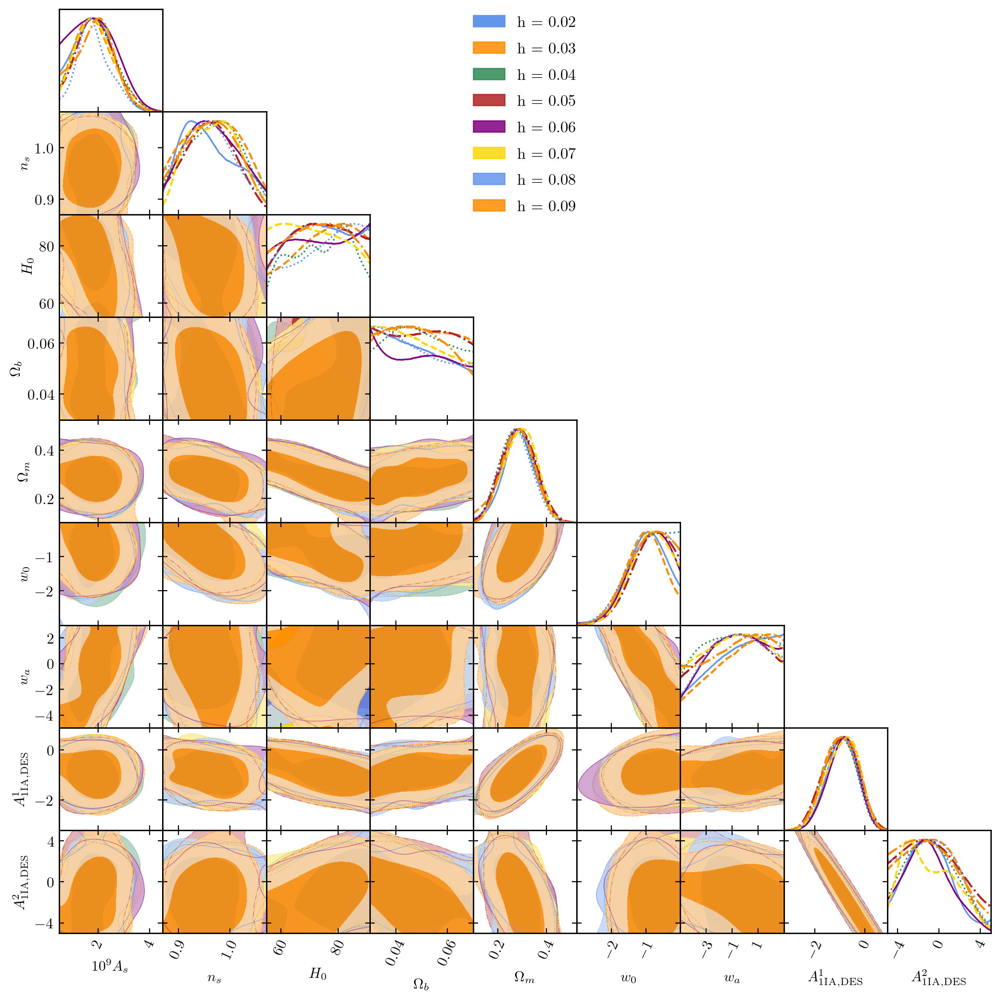

In [67]:
chain_names = []
for x in hs2:
    chain_names.append("h = %.2f" % x)
g = nw.plot_Fisher(F=F2,
                   mu=param,
                   select=sel,
                   filled=True,
                   flat_priors=flat_priors,
                   chain_names=chain_names)

<!-- DRAFT: Fable rewrites -->
### Five-point stencil versus derivkit

Facts for the text (draft):

- `nw.get_Fisher2` builds the derivatives with the derivkit package, which fits polynomials through adaptively chosen samples of the data vector and differentiates the fit, so numerical noise averages out instead of entering the derivative at full strength. For a fiducial of zero ($w_a$, the photo-z shifts) derivkit takes absolute steps from $10^{-6}$ up to $10^{-2}$.
- The figure overlays the five-point forecast ($h=0.06$, `AccuracyBoost` = 3, taken from the step test above) and the derivkit forecast (`AccuracyBoost` = 2.5).
- Numbers: derivkit at `AccuracyBoost` = 2.5 (450 s) gives FoM($w_0$, $w_a$) = 0.0979 against 0.1003 for the stencil ($-2.4$%) and FoM($10^9A_s$, $\Omega_m$) = 0.881 against 0.865 (+1.8%). The marginalized errors agree within a few percent; the diagonal entries $F_{pp}$ differ most for the four photo-z shifts (derivkit/stencil = 0.85–0.97), where the steps differ most (derivkit $10^{-6}$ to $10^{-2}$, the stencil 0.06 and 0.12). At `AccuracyBoost` = 1 (measured outside the notebook) derivkit gave FoM($w_0$, $w_a$) = 0.68 with $\sigma(w_a)\approx1$: its tiny absolute steps for $w_a$ (fiducial 0) see the numerical noise of the data vector, which looks like information. Importing derivkit rewrites matplotlib's global rcParams (usetex off, sans-serif fonts); the cell wraps the call in `matplotlib.rc_context()`, so the later figures keep the notebook style.

In [68]:
# DRAFT comments (Fable rewrites the final text).
# The stencil matrix at h = 0.06 is the one of the step test (no new
# evaluations); derivkit evaluates the data vector at its own samples.
F_stencil = F2[4]
t0 = time.time()
# The first call imports derivkit, and the import runs derivkit's own
# plot style (derivkit/plotutils/plot_style.py), which rewrites
# matplotlib's global rcParams: usetex off, sans-serif fonts, gray text.
# matplotlib.rc_context() saves the notebook's rcParams on entry and
# restores them when the with-block ends, so every later figure keeps
# the style of the setup cell.
with matplotlib.rc_context():
    F_dkit = nw.get_Fisher2(CV=param, AccuracyBoost=2.5)
time_dkit = time.time() - t0
print("derivkit Fisher matrix in %.0f s" % time_dkit)
print("%-24s %13s %23s" % ("", "FoM(w0, wa)", "FoM(10^9 A_s, Omega_m)"))
print("%-24s %13.4g %23.4g" % ("5-point stencil, h=%.2f" % hs2[4],
                               cnu.get_FoM(iw0, iwa, F_stencil),
                               cnu.get_FoM(iAs, iOm, F_stencil)))
print("%-24s %13.4g %23.4g" % ("derivkit",
                               cnu.get_FoM(iw0, iwa, F_dkit),
                               cnu.get_FoM(iAs, iOm, F_dkit)))
# where the two differ: the marginalized errors sqrt((F^-1)_pp) and the
# diagonal entries F_pp (the information on p with every other parameter
# fixed) of the two matrices, parameter by parameter
sigma_stencil = np.sqrt(np.diag(np.linalg.inv(F_stencil)))
sigma_dkit = np.sqrt(np.diag(np.linalg.inv(F_dkit)))
print()
print("%-10s %14s %14s %22s" % ("parameter", "sigma stencil", "sigma derivkit",
                                "F_pp derivkit/stencil"))
for p in range(len(param)):
    print("%-10s %14.4g %14.4g %22.4g" % (param_names[p], sigma_stencil[p],
                                          sigma_dkit[p],
                                          F_dkit[p, p]/F_stencil[p, p]))

derivkit Fisher matrix in 652 s
                           FoM(w0, wa)  FoM(10^9 A_s, Omega_m)
5-point stencil, h=0.06         0.1003                  0.8651
derivkit                       0.09785                  0.8811

parameter   sigma stencil sigma derivkit  F_pp derivkit/stencil
As_1e9              4.331          4.242                 0.9998
ns                 0.3081         0.2988                 0.9994
H0                  158.9          155.5                 0.9987
omegab             0.2572         0.2531                      1
omegam             0.2669         0.2677                 0.9994
w0                  2.965           3.09                      1
wa                  10.05          10.68                  1.003
DES_A1_1            1.692          1.699                      1
DES_A1_2            4.612          4.575                      1
DES_DZ_S1         0.01571         0.0163                 0.8514
DES_DZ_S2         0.01257         0.0129                 0.8748
DES_DZ_S3 

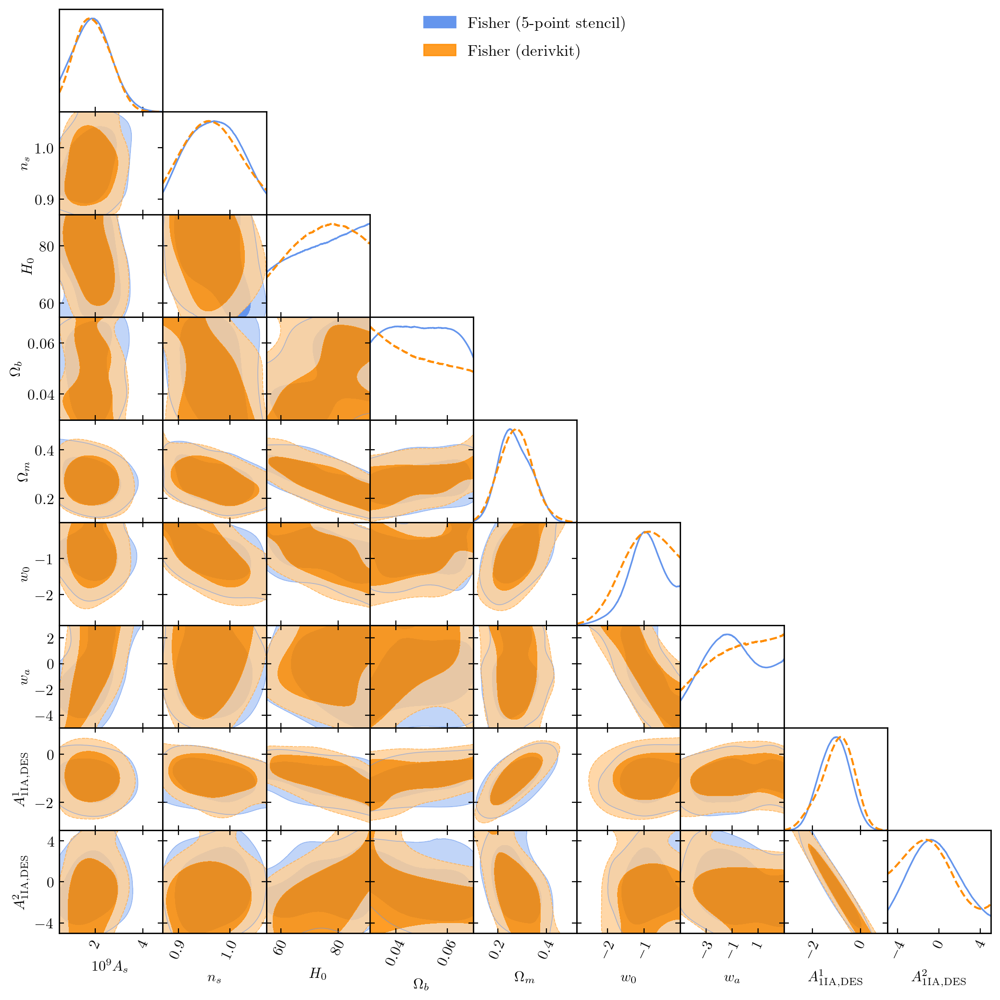

In [69]:
g = nw.plot_Fisher(F=F_stencil,
                   F2=F_dkit,
                   mu=param,
                   select=sel,
                   filled=True,
                   flat_priors=flat_priors,
                   chain_names=["Fisher (5-point stencil)", "Fisher (derivkit)"])

### How numerical noise moves the dark-energy figure of merit

A computed data vector is the smooth model plus a small numerical
error: the integration grids, the distance grids and CAMB's tolerances
leave a remnant that changes irregularly from one parameter value to
the next. A finite-difference derivative divides that error by the
step, so each derivative column $j$ carries a noise vector $e_j$ beside
the true derivative. In the Fisher matrix $F = D^{\mathsf T}C^{-1}D$
the noise term $e_j^{\mathsf T}C^{-1}e_j$ is a sum of squares, positive
for every realization, so on average the noise only adds to $F_{jj}$:
noise looks like information. Off the diagonal, products of independent
errors average to zero. The average addition
$a_j = \langle e_j^{\mathsf T}C^{-1}e_j\rangle$ therefore acts exactly
like a Gaussian prior of width $a_j^{-1/2}$ on parameter $p_j$ - a
prior the data do not carry. Marginalization passes that fake prior to
the $(w_0, w_a)$ block, and to first order it moves the figure of merit
$\mathrm{FoM} = \det C_w^{-1/2}$ (the inverse area of the pair's error
ellipse, with $C_w = (F^{-1})_{ww}$ the pair's marginalized covariance)
by

$$\delta\ln\mathrm{FoM}(w_0, w_a) \simeq \frac{1}{2}\sum_j R_j^2\,a_j\,\sigma_j^2,$$

one term per sampled parameter (the Fisher note of the lssty1xdesi
project, `projects/lssty1xdesi/notes/fisher_machinery`, section
"Derivative accuracy"):

- $\sigma_j^2 = (F^{-1})_{jj}$ is the marginalized forecast variance of
  $p_j$, so $a_j\sigma_j^2$ compares the fake prior with the
  information the data leave on $p_j$ after marginalization;
- $R_j^2 = (F^{-1})_{j,w}\,C_w^{-1}\,(F^{-1})_{w,j}/\sigma_j^2$, with
  $w = (w_0, w_a)$, is the squared multiple correlation of $p_j$ with
  the pair: the share of $p_j$'s forecast variance that a linear fit to
  $(w_0, w_a)$ explains. It is 1 for $w_0$ and $w_a$ themselves and 0
  for a parameter uncorrelated with the pair, so a column's noise
  reaches the figure of merit only through its correlation with the
  pair.

The noise is measured from the five stencil points
$p_j + k\,\varepsilon_j$, $k = -2, \dots, 2$, of the five-point
derivative (`cnu.get_stencil_noise`, five evaluations per column). The
fourth difference
$\Delta_4 m = m(-2) - 4\,m(-1) + 6\,m(0) - 4\,m(1) + m(2)$ removes the
smooth part of the model - every derivative below the fourth cancels,
leaving $O(\varepsilon^4)$ - and keeps the point-to-point jitter.
Whitening it with the data covariance (whitening transforms a vector so
its errors become unit and uncorrelated; its squared length is then a
$\chi^2$) gives the noise of one evaluation,
$\hat\sigma_j = \sqrt{\Delta_4 m^{\mathsf T}C^{-1}\Delta_4 m/70}$, and
the spurious prior $a_j = (130/144)\,(\hat\sigma_j/\varepsilon_j)^2$.
The two constants count squared stencil weights:
$70 = 1 + 16 + 36 + 16 + 1$ from the fourth difference and
$130/144 = (1 + 64 + 64 + 1)/12^2$ from the derivative weights
$(-1, 8, -8, 1)/12$. The step $\varepsilon_j$ is $h\,|p_j|$, or $h$
where the fiducial is zero ($|p_j| \le 10^{-12}$) - the rule of
`cnu.get_ddv`.

The estimate is cheap because $F$, $R_j$ and $\sigma_j$ come once, from
the base matrix of this section. Column $j$ contributes
$(130/288)\,\hat\sigma_j^2\,W_j$ with the dimensionless lever
$W_j = R_j^2\,(\sigma_j/\varepsilon_j)^2$, so the lever ranks the
columns before any noise is measured: the rows below measure the
seven columns that carry 99% of the lever sum
($w_a$, $w_0$, $A_\mathrm{IA}$, $\eta_\mathrm{IA}$, $H_0$, $\Omega_b$, $\Omega_m$) and keep $a_j = 0$ for the rest.

The table has one row per `AccuracyBoost` (the range of the `AccuracyBoost` test above), the
highest as the reference. Its columns: the first-order
$\delta\ln\mathrm{FoM}$; the predicted FoM ratio against the reference -
the exact diagonal form $\mathrm{FoM}(F + \mathrm{diag}\,a)/\mathrm{FoM}(F)$ of
the row divided by the reference row's own ratio, since the reference
is not noise free (`cnu.predict_fom_noise`); the measured columns; the
number of data-vector evaluations; the time. A setting has settled when
$\sum_j R_j^2 a_j \sigma_j^2$ ($= 2\,\delta\ln\mathrm{FoM}$) is below
about $10^{-2}$, which keeps the figure of merit within about half a
percent; here the sum lies between $1.0\times10^{-4}$ and $1.3\times10^{-4}$ in every row, the default `AccuracyBoost` = 1 included, so every row has settled.

The estimate sees one error family only. An error that varies smoothly
across the five stencil points - a resolution offset that bends gently
with the parameter - cancels in the fourth difference exactly as the
smooth model does, yet can still move the derivative. On lsst_y1's
cosmic-shear Fisher matrix the full FoM at `AccuracyBoost` = 1 sat
0.23% from the reference while the jitter prediction was about
$3\times10^{-5}$: that 0.23% is a smooth change of the data vector with
the accuracy settings, invisible to the fourth difference.
The last block prints the full-Fisher
FoM($w_0$, $w_a$) ratios of the scan above next to the predicted
ratios for the same reading here. The prediction answers where the
point-to-point jitter stops mattering; the direct comparison of full
Fisher matrices is what tests the smooth family.

In [70]:
# DRAFT comments (Fable rewrites the final text).
# eps[j]: the absolute step of column j, h |p0_j|, or h for a fiducial of
# zero (wa and the photo-z shifts): the step convention of cnu.get_ddv
eps = np.zeros(len(param))
for j in range(len(param)):
    if np.isclose(param[j], 0.0, atol=1e-12):
        eps[j] = h_base
    else:
        eps[j] = h_base*abs(param[j])
# R2, sigma2 and the lever W_j = R_j^2 (sigma_j/eps_j)^2 of every column,
# from the normal-accuracy matrix F_base
weights = cnu.get_fom_noise_weights(F=F_base, i=iw0, j=iwa, eps=eps)
lever = weights["lever"]
# the columns by decreasing lever: np.argsort sorts ascending, and [::-1]
# reverses that order
order = np.argsort(lever)[::-1]
share = np.cumsum(lever[order])/np.sum(lever)
# the heavy columns: the fewest leading columns whose levers reach 99% of
# the lever sum (np.searchsorted returns the first position where the
# cumulative share is >= 0.99)
n_heavy = int(np.searchsorted(share, 0.99)) + 1
heavy = order[:n_heavy]
print("%-10s %8s %11s %11s %11s %10s" % ("column", "R^2", "sigma",
                                         "eps", "lever W", "cum. share"))
for rank in range(len(order)):
    j = order[rank]
    print("%-10s %8.3f %11.4g %11.4g %11.4g %10.6f" % (
        param_names[j], weights["R2"][j], np.sqrt(weights["sigma2"][j]),
        eps[j], lever[j], share[rank]))
heavy_names = []
for j in heavy:
    heavy_names.append(param_names[j])
print("measured columns (99% of the lever sum):", ", ".join(heavy_names))

column          R^2       sigma         eps     lever W cum. share
wa            1.000       9.986        0.03   1.108e+05   0.833873
w0            1.000       2.944        0.03        9631   0.906352
DES_A1_1      0.748       1.693       0.021        4864   0.942958
DES_A1_2      0.492       4.616       0.051        4034   0.973320
H0            0.189       156.2        2.02        1127   0.981803
omegab        0.024      0.2498      0.0012        1031   0.989561
omegam        0.920      0.2659       0.009         803   0.995604
As_1e9        0.128       4.222       0.063       574.6   0.999929
DES_M4        0.062     0.00747    0.001107        2.83   0.999950
DES_M3        0.022    0.007356    0.000723       2.289   0.999967
DES_M2        0.011    0.007641    0.000594         1.9   0.999982
ns            0.012      0.3044     0.02898       1.294   0.999991
DES_M1        0.000    0.009088    0.000189       1.071   0.999999
DES_DZ_S4     0.201     0.01595        0.03     0.05665   1.00

In [71]:
# DRAFT comments (Fable rewrites the final text).
# One row per AccuracyBoost of the test above, the last as reference. In
# each row only the heavy columns are measured (five data vectors each);
# the other columns enter with a = 0.
noise_rows = []
for x in AB1:
    t0 = time.time()
    a = np.zeros(len(param))
    for j in heavy:
        noise = nw.get_stencil_noise(index=int(j), h=h_base, CV=param,
                                     AccuracyBoost=x, invcov=invcov)
        a[j] = noise["a"]
    # first-order change of ln FoM(w0, wa) and the exact ratio
    # FoM(F_base + diag(a))/FoM(F_base)
    prediction = cnu.predict_fom_noise(F=F_base, i=iw0, j=iwa, a=a)
    noise_rows.append({
        "AccuracyBoost": x,
        "a": a,
        "terms": prediction["terms"],
        "dlnFoM": prediction["dlnFoM"],
        "ratio": prediction["ratio"],
        "n_evals": 5*len(heavy),
        "time": time.time() - t0,
    })
ratio_ref = noise_rows[-1]["ratio"]
print("FoM(w0, wa); base F: AccuracyBoost = %g, h = %g; reference row: "
      "AccuracyBoost = %g" % (AB_base, h_base, AB1[-1]))
print("%13s %12s %18s %6s %9s  %s" % ("AccuracyBoost", "dlnFoM",
      "FoM ratio / ref.", "evals", "time [s]", "measured columns"))
for row in noise_rows:
    print("%13.1f %12.3e %18.8f %6d %9.0f  %s" % (
        row["AccuracyBoost"], row["dlnFoM"], row["ratio"]/ratio_ref,
        row["n_evals"], row["time"], ", ".join(heavy_names)))
# the per-column terms R_j^2 a_j sigma_j^2 of each row (their sum is
# 2 dlnFoM; the convergence rule asks for a sum below about 1e-2)
print()
print("%13s" % "AccuracyBoost" + "".join(["%12s" % name for name in heavy_names])
      + "%12s" % "sum")
for row in noise_rows:
    line = "%13.1f" % row["AccuracyBoost"]
    for j in heavy:
        line = line + "%12.3e" % row["terms"][j]
    line = line + "%12.3e" % np.sum(row["terms"])
    print(line)

FoM(w0, wa); base F: AccuracyBoost = 1, h = 0.03; reference row: AccuracyBoost = 5
AccuracyBoost       dlnFoM   FoM ratio / ref.  evals  time [s]  measured columns
          1.0    6.395e-05         1.00001160     35        33  wa, w0, DES_A1_1, DES_A1_2, H0, omegab, omegam
          2.0    5.917e-05         1.00000683     35        74  wa, w0, DES_A1_1, DES_A1_2, H0, omegab, omegam
          3.0    5.011e-05         0.99999776     35       131  wa, w0, DES_A1_1, DES_A1_2, H0, omegab, omegam
          4.0    5.519e-05         1.00000284     35       204  wa, w0, DES_A1_1, DES_A1_2, H0, omegab, omegam
          5.0    5.235e-05         1.00000000     35       309  wa, w0, DES_A1_1, DES_A1_2, H0, omegab, omegam

AccuracyBoost          wa          w0    DES_A1_1    DES_A1_2          H0      omegab      omegam         sum
          1.0   2.581e-05   2.614e-05   1.704e-20   3.373e-10   6.337e-05   7.801e-08   1.249e-05   1.279e-04
          2.0   1.286e-05   1.683e-06   2.678e-20   3.372e-1

In [72]:
# DRAFT comments (Fable rewrites the final text).
# A short comparison with the full Fisher matrices of the AccuracyBoost
# test: their FoM(w0, wa) relative to the reference AccuracyBoost against
# the predicted ratio. The full matrices also change smoothly with the
# accuracy and carry their own random noise, which the prediction (the
# average effect of the measured jitter) does not contain.
print("%13s %26s %22s" % ("AccuracyBoost", "full Fisher FoM / FoM_ref",
                          "predicted ratio / ref."))
for i in range(len(AB1)):
    print("%13.1f %26.6f %22.8f" % (AB1[i], FOM1_w[i]/FOM1_w[-1],
                                    noise_rows[i]["ratio"]/ratio_ref))

AccuracyBoost  full Fisher FoM / FoM_ref predicted ratio / ref.
          1.0                   1.005062             1.00001160
          2.0                   0.999988             1.00000683
          3.0                   0.999946             0.99999776
          4.0                   1.000105             1.00000284
          5.0                   1.000000             1.00000000


## Which wavenumbers each measurement probes

### Log-response $d\ln C_{\mathrm{ss}}^{\mathrm{EE}} \big/ d\ln k$ (normalized)

A Limber spectrum is an integral of the matter power spectrum along the line of sight, which can be written as an integral over $\ln k$: $C_\ell=\int d\ln k\;dC_\ell/d\ln k$. The log-response $d\ln C_\ell/d\ln k=(dC_\ell/d\ln k)/C_\ell$ is the fraction of the signal contributed per unit $\ln k$. It shows which wavenumbers a multipole measures, the input for choosing scale cuts ([arXiv:2011.06469](https://arxiv.org/abs/2011.06469), Eq. 17). The figure shows the auto-correlations $(i,i)$ of the four source bins (one dash pattern per bin) at $\ell=30$, 300 and 3000 (one color per multipole), each curve divided by its own maximum.

In [73]:
# dlnC_dlss_tomo_limber lives in this project's interface/
# (cosmolike_desy1xplanck_notebook_wrappers, imported above as nw),
# shared by every notebook of this project; call as
# nw.dlnC_dlss_tomo_limber.

In [74]:
# dlnCEEdlnk has axes [k, ell, i, j] with k in h/Mpc; tmp receives the
# B-mode response.
ell  = [30.,300.,3000.]
kk = 10.0 ** np.arange(-2.2, 1.6, 0.025)
(dlnCEEdlnk, tmp) = nw.dlnC_dlss_tomo_limber(k=kk, ell=ell, CLAccuracyBoost=1.00)

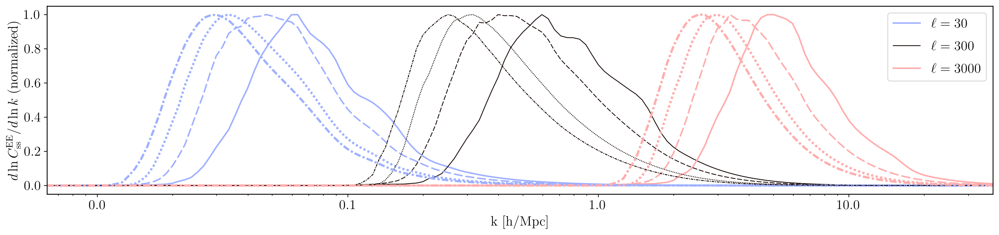

In [75]:
cnu.plot_response_function(k=kk,
                           resp=dlnCEEdlnk,
                           labels=[r"$\ell=30$", r"$\ell=300$", r"$\ell=3000$"],
                           ylabel=r"$d\ln C_{\mathrm{ss}}^{\mathrm{EE}} / d\ln k$ (normalized)",
                           normalize=True,
                           xtickformat="scalar")


### Log-response $d\ln \xi_{\pm} \big/ d\ln k$ (normalized)

The Legendre sums that build $\xi_\pm$ from $C_\ell$, applied to $dC_\ell/d\ln k$, give the log-response of each angular bin. The figures show angular bins 10 and 20 (`idx`, counted from 0), centered near 2.8′ and 28′; the printed array lists all 30 centers in arcminutes. At a given angle, $\xi_-$ responds to larger $k$ than $\xi_+$.

In [76]:
# dlnxi_dlnk_pm_tomo_limber lives in this project's interface/
# (cosmolike_desy1xplanck_notebook_wrappers, imported above as nw),
# shared by every notebook of this project; call as
# nw.dlnxi_dlnk_pm_tomo_limber.

In [77]:
kk = 10.0**np.arange(-3., 1.02, 0.02)

In [78]:
# theta in arcmin; both responses have axes [k, theta, i, j].
(theta, dlnxip_dlnk, dlnxim_dlnk) = nw.dlnxi_dlnk_pm_tomo_limber(k = kk)

In [79]:
print(theta)

[0.2836022963386458, 0.35703413770390113, 0.44947934883345914, 0.5658609743231364, 0.7123767601180032, 0.8968292060841517, 1.1290410775785265, 1.4213785035230764, 1.7894095178631664, 2.2527331141442906, 2.8360229633864567, 3.570341377039011, 4.494793488334589, 5.658609743231364, 7.12376760118003, 8.968292060841518, 11.290410775785269, 14.21378503523077, 17.894095178631662, 22.527331141442893, 28.36022963386455, 35.70341377039008, 44.94793488334587, 56.58609743231363, 71.2376760118003, 89.68292060841516, 112.90410775785266, 142.13785035230768, 178.9409517863167, 225.27331141442897]


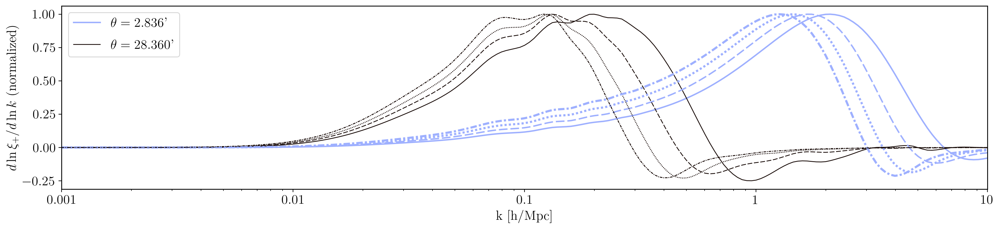

In [80]:
# Angular bins 10 and 20, counted from 0: theta near 2.8 and 28 arcmin.
idx = [10, 20]
cnu.plot_response_function(k=kk,
                           resp=dlnxip_dlnk,
                           labels=[rf"$\theta={theta[i]:.3f}$'" for i in idx],
                           idx=idx,
                           ncolors=3,
                           ylabel=r"$d\ln \xi_{+} / d\ln k$ (normalized)",
                           normalize=True)


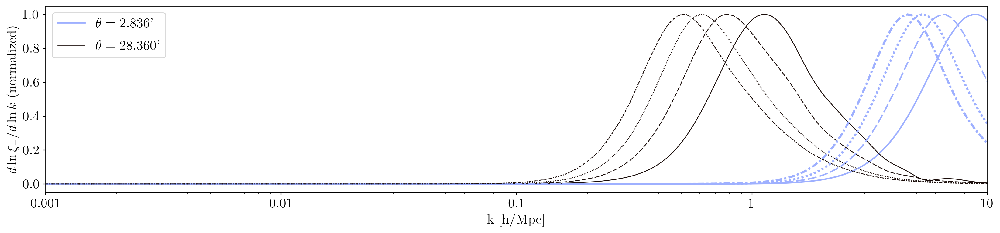

In [81]:
cnu.plot_response_function(k=kk,
                           resp=dlnxim_dlnk,
                           labels=[rf"$\theta={theta[i]:.3f}$'" for i in idx],
                           idx=idx,
                           ncolors=3,
                           ylabel=r"$d\ln \xi_{-} / d\ln k$ (normalized)",
                           normalize=True)


### Cumulative response $R(k_\mathrm{max})$ of $C_{\mathrm{ss}}^{\mathrm{EE}}$

$$R_\ell(k_\mathrm{max})=\frac{\int_{-\infty}^{\ln k_\mathrm{max}} d\ln k\,\big|d\ln C_{\mathrm{ss}}^{\mathrm{EE}}(\ell)/d\ln k\big|}{\int_{-\infty}^{\infty} d\ln k\,\big|d\ln C_{\mathrm{ss}}^{\mathrm{EE}}(\ell)/d\ln k\big|}$$

$R$ grows from 0 to 1 with $k_\mathrm{max}$: it is the fraction of a measurement's absolute log-response that comes from wavenumbers below $k_\mathrm{max}$. Where $R=0.9$, a tenth of the response still comes from larger $k$, where the nonlinear and baryonic modeling is least certain. A scale cut can require $R$ to reach a chosen fraction at a trusted $k_\mathrm{max}$. These curves are drawn as computed, without normalization.

In [82]:
# rf_C_ss_tomo_limber lives in this project's interface/
# (cosmolike_desy1xplanck_notebook_wrappers, imported above as nw),
# shared by every notebook of this project; call as
# nw.rf_C_ss_tomo_limber.

In [83]:
# rfCEE has axes [k_max, ell, i, j]; tmp receives the B-mode result.
ell  = [30.,300.,3000.]
kk = 10.0 ** np.arange(-2.2, 1.6, 0.05)
(rfCEE, tmp) = nw.rf_C_ss_tomo_limber(k=kk, ell=ell, CLAccuracyBoost=1.00, CLIntegrationAccuracy=0)

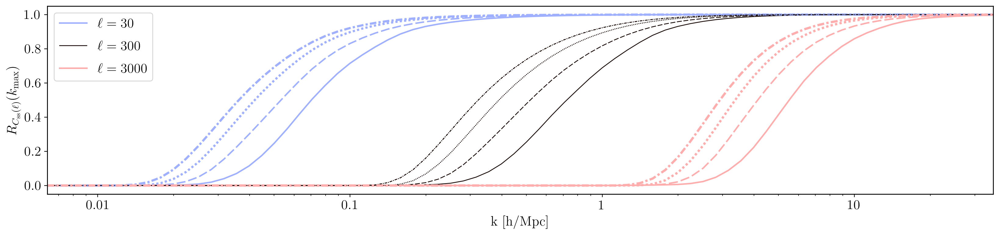

In [84]:
cnu.plot_response_function(k=kk,
                           resp=rfCEE,
                           labels=[r"$\ell=30$", r"$\ell=300$", r"$\ell=3000$"],
                           ylabel=r"$R_{C_{\mathrm{ss}}(\ell)}(k_{\mathrm{max}})$",
                           normalize=False)


### Cumulative response $R(k_\mathrm{max})$ of $\xi_\pm$

$$R_\theta(k_\mathrm{max})=\frac{\int_{-\infty}^{\ln k_\mathrm{max}} d\ln k\,\big|d\ln \xi_\pm(\theta)/d\ln k\big|}{\int_{-\infty}^{\infty} d\ln k\,\big|d\ln \xi_\pm(\theta)/d\ln k\big|}$$

The same fraction for angular bins 10 and 20 of $\xi_+$ and $\xi_-$.

In [85]:
# rf_xi_tomo_limber lives in this project's interface/
# (cosmolike_desy1xplanck_notebook_wrappers, imported above as nw),
# shared by every notebook of this project; call as
# nw.rf_xi_tomo_limber.

In [86]:
kk = 10.0 ** np.arange(-2, 1.2, 0.02)

In [87]:
# theta in arcmin; rf_xip and rf_xim have axes [k_max, theta, i, j].
(theta, rf_xip, rf_xim) = nw.rf_xi_tomo_limber(k = kk)

In [88]:
print(theta)

[0.2836022963386458, 0.35703413770390113, 0.44947934883345914, 0.5658609743231364, 0.7123767601180032, 0.8968292060841517, 1.1290410775785265, 1.4213785035230764, 1.7894095178631664, 2.2527331141442906, 2.8360229633864567, 3.570341377039011, 4.494793488334589, 5.658609743231364, 7.12376760118003, 8.968292060841518, 11.290410775785269, 14.21378503523077, 17.894095178631662, 22.527331141442893, 28.36022963386455, 35.70341377039008, 44.94793488334587, 56.58609743231363, 71.2376760118003, 89.68292060841516, 112.90410775785266, 142.13785035230768, 178.9409517863167, 225.27331141442897]


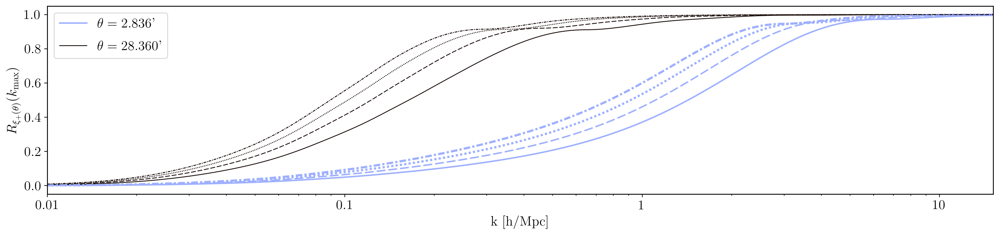

In [89]:
# Angular bins 10 and 20, counted from 0: theta near 2.8 and 28 arcmin.
idx = [10, 20]
cnu.plot_response_function(k=kk,
                           resp=rf_xip,
                           labels=[rf"$\theta={theta[i]:.3f}$'" for i in idx],
                           idx=idx,
                           ncolors=3,
                           ylabel=r"$R_{\xi_+(\theta)}(k_{\mathrm{max}})$",
                           normalize=False)


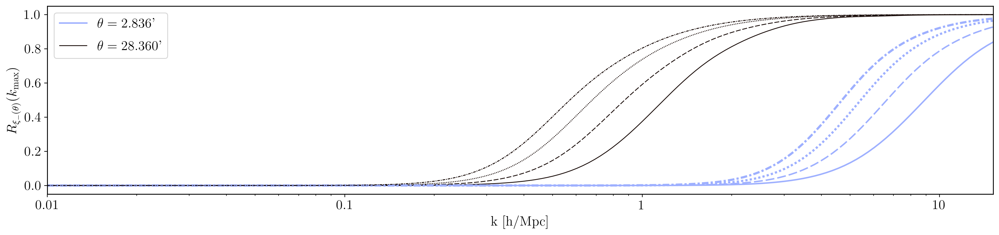

In [90]:
cnu.plot_response_function(k=kk,
                           resp=rf_xim,
                           labels=[rf"$\theta={theta[i]:.3f}$'" for i in idx],
                           idx=idx,
                           ncolors=3,
                           ylabel=r"$R_{\xi_-(\theta)}(k_{\mathrm{max}})$",
                           normalize=False)


## CMB lensing × shear: $C_\ell^{\kappa s}$ and $w_{\kappa s}(\theta)$

CMB photons are deflected by all the matter between the last-scattering surface ($z\approx1090$) and the observer, so the reconstructed lensing convergence $\kappa$ of Planck PR4 correlates with the cosmic shear of each DES source bin. $\kappa$ has a single source plane, so the arrays carry one tomographic index, the source bin $i$, and only the shear nuisance parameters enter.

- $C_\ell^{\kappa s}$, axes `[ell, i]`, is the Limber cross-spectrum, drawn as $\ell(\ell+1)C_\ell/2\pi$.
- $w_{\kappa s}(\theta)$, axes `[theta, i]` with $\theta$ in arcminutes, is the real-space correlation of $\kappa$ with the tangential shear. It includes the filtering of the lensing map set in the dataset file: a Gaussian beam of 7′ full width at half maximum, the HEALPix pixel window and the multipole range $8\le\ell\le2048$. $C_\ell^{\kappa s}$ omits that filter.

$w_{\kappa s}(\theta)$ is the CMB lensing × shear block of the 6x2pt data vector (120 entries). The covariance generated by this project's covariance notebook does not include it.

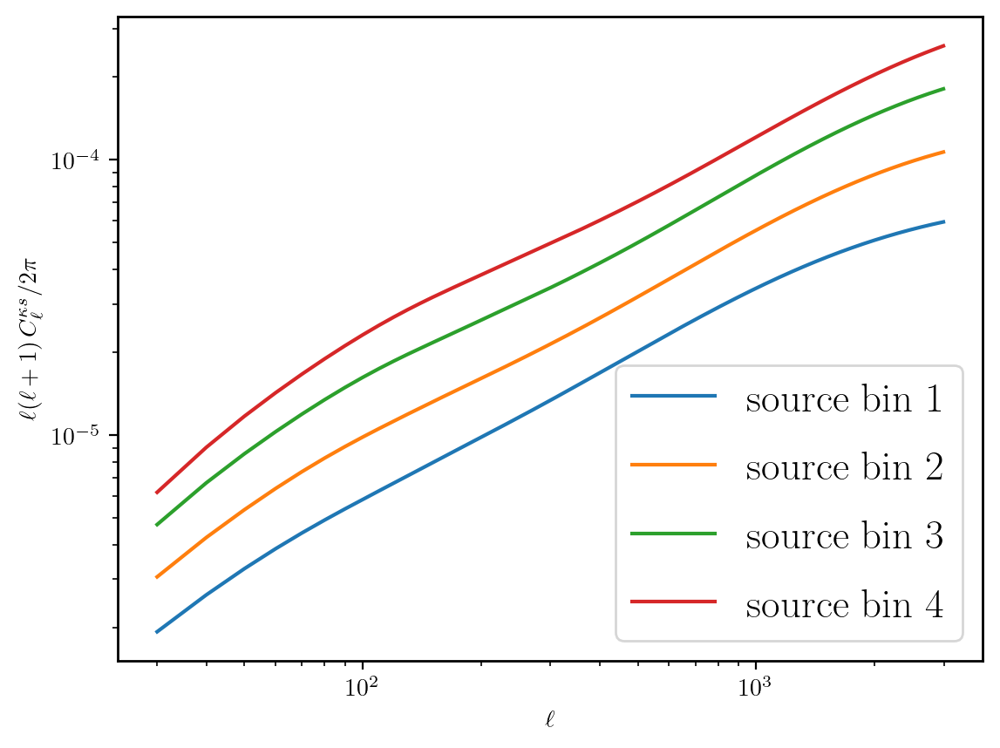

In [91]:
# C_ks_tomo_limber, w_ks, and their scale-cut diagnostics live in this
# project's interface/ (cosmolike_desy1xplanck_notebook_wrappers,
# imported above as nw); the CMB beam/pixel-window filter entering the
# w_ks projection was initialized by nw.init_cosmolike from the
# .dataset keys.
lmin = 30.
lmax = 3000.
ell = np.arange(lmin, lmax, 10.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
Cks = np.array(nw.C_ks_tomo_limber(ell=ell))
for b in range(Cks.shape[1]):
    plt.loglog(ell, ell*(ell + 1)*Cks[:, b]/(2*np.pi),
               label=rf"source bin {b + 1}")
plt.xlabel(r"$\ell$")
plt.ylabel(r"$\ell(\ell+1)\, C_\ell^{\kappa s}/2\pi$")
plt.legend()

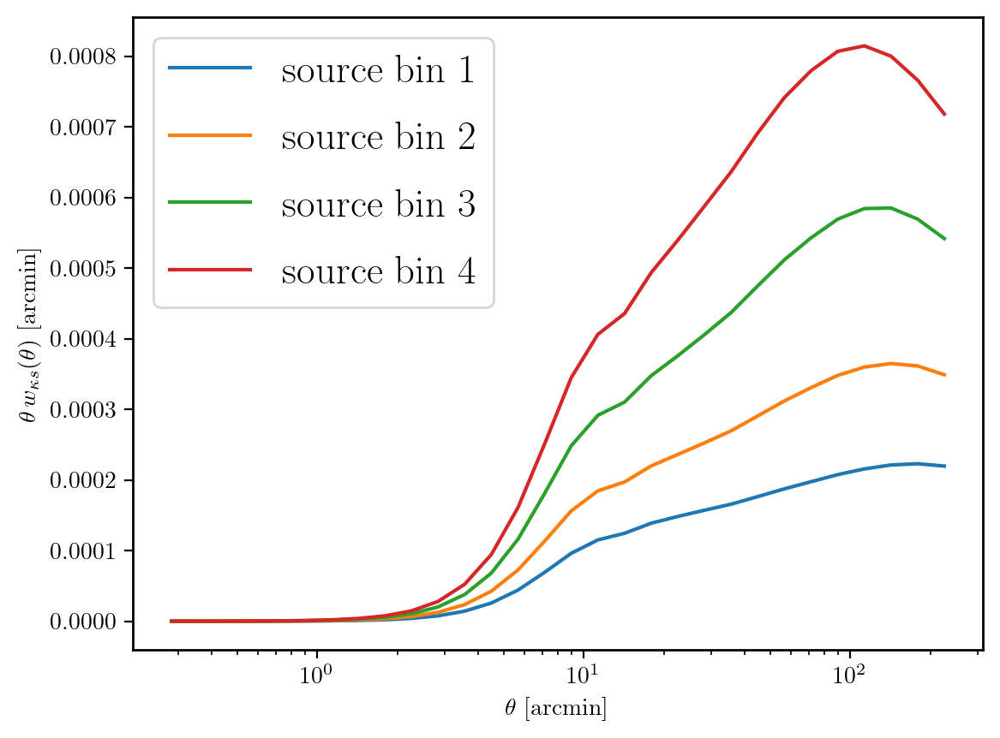

In [92]:
# w_ks includes the lensing-map filter (beam, pixel window, 8 <= ell <= 2048);
# axes [theta, source bin], theta in arcmin.
(theta, wks) = nw.w_ks()
wks = np.array(wks)
for b in range(wks.shape[1]):
    plt.semilogx(theta, theta*wks[:, b], label=rf"source bin {b + 1}")
plt.xlabel(r"$\theta$ [arcmin]")
plt.ylabel(r"$\theta\, w_{\kappa s}(\theta)$ [arcmin]")
plt.legend()

### Log-response $d\ln C_{\kappa s} \big/ d\ln k$ (normalized)

The log-response of the CMB lensing × shear spectrum at $\ell=30$, 300 and 3000, one dash pattern per source bin; `dlnCks` has axes `[k, ell, i]`.

In [93]:
# dlnCks has axes [k, ell, i]: one source index, because the CMB lensing
# map has a single source plane.
ell  = [30.,300.,3000.]
kk = 10.0 ** np.arange(-2.2, 1.6, 0.025)
dlnCks = nw.dlnC_ks_dlnk_tomo_limber(k=kk, ell=ell)

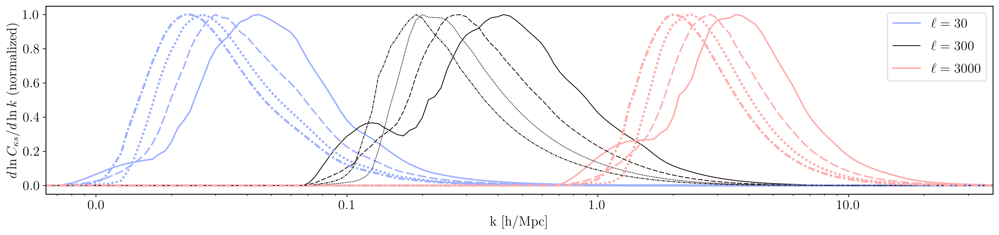

In [94]:
cnu.plot_response_function(k=kk,
                           resp=dlnCks,
                           labels=[r"$\ell=30$", r"$\ell=300$", r"$\ell=3000$"],
                           ylabel=r"$d\ln C_{\kappa s} / d\ln k$ (normalized)",
                           normalize=True,
                           xtickformat="scalar")


### Log-response $d\ln w_{\kappa s} \big/ d\ln k$ (normalized)

The log-response of $w_{\kappa s}$ in angular bins 10 and 20, one dash pattern per source bin. Like $w_{\kappa s}$ itself, it includes the filter of the lensing map.

In [95]:
# dlnwks has axes [k, theta, i]; theta in arcmin.
kk = 10.0**np.arange(-3., 1.02, 0.02)
(theta, dlnwks) = nw.dlnw_ks_dlnk_tomo(k = kk)
print(theta)

[0.2836022963386458, 0.35703413770390113, 0.44947934883345914, 0.5658609743231364, 0.7123767601180032, 0.8968292060841517, 1.1290410775785265, 1.4213785035230764, 1.7894095178631664, 2.2527331141442906, 2.8360229633864567, 3.570341377039011, 4.494793488334589, 5.658609743231364, 7.12376760118003, 8.968292060841518, 11.290410775785269, 14.21378503523077, 17.894095178631662, 22.527331141442893, 28.36022963386455, 35.70341377039008, 44.94793488334587, 56.58609743231363, 71.2376760118003, 89.68292060841516, 112.90410775785266, 142.13785035230768, 178.9409517863167, 225.27331141442897]


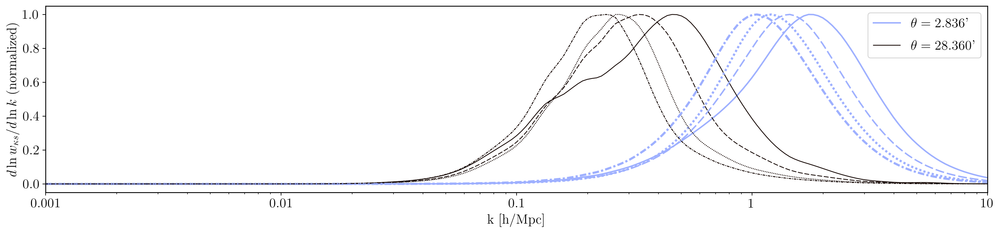

In [96]:
# Angular bins 10 and 20, counted from 0: theta near 2.8 and 28 arcmin.
idx = [10, 20]
cnu.plot_response_function(k=kk,
                           resp=dlnwks,
                           labels=[rf"$\theta={theta[i]:.3f}$'" for i in idx],
                           idx=idx,
                           ncolors=3,
                           ylabel=r"$d\ln w_{\kappa s} / d\ln k$ (normalized)",
                           normalize=True)


### Cumulative response $R(k_\mathrm{max})$ of $C_{\kappa s}$

$$R_\ell(k_\mathrm{max})=\frac{\int_{-\infty}^{\ln k_\mathrm{max}} d\ln k\,\big|d\ln C_{\kappa s}(\ell)/d\ln k\big|}{\int_{-\infty}^{\infty} d\ln k\,\big|d\ln C_{\kappa s}(\ell)/d\ln k\big|}$$

The fraction of the absolute log-response below $k_\mathrm{max}$, at $\ell=30$, 300 and 3000.

In [97]:
# rfCks has axes [k_max, ell, i].
ell  = [30.,300.,3000.]
kk = 10.0 ** np.arange(-2.2, 1.6, 0.05)
rfCks = nw.rf_C_ks_tomo_limber(k=kk, ell=ell)

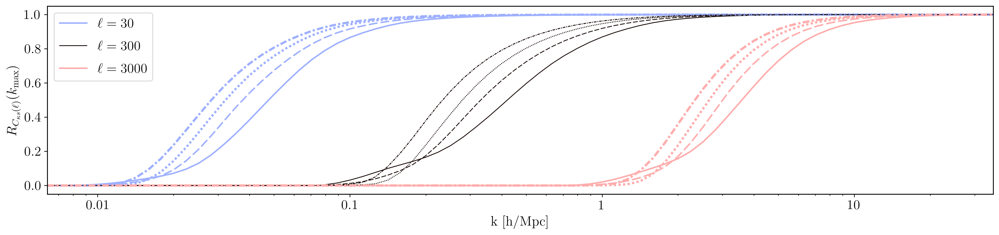

In [98]:
cnu.plot_response_function(k=kk,
                           resp=rfCks,
                           labels=[r"$\ell=30$", r"$\ell=300$", r"$\ell=3000$"],
                           ylabel=r"$R_{C_{\kappa s}(\ell)}(k_{\mathrm{max}})$",
                           normalize=False)


### Cumulative response $R(k_\mathrm{max})$ of $w_{\kappa s}$

$$R_\theta(k_\mathrm{max})=\frac{\int_{-\infty}^{\ln k_\mathrm{max}} d\ln k\,\big|d\ln w_{\kappa s}(\theta)/d\ln k\big|}{\int_{-\infty}^{\infty} d\ln k\,\big|d\ln w_{\kappa s}(\theta)/d\ln k\big|}$$

The same fraction for angular bins 10 and 20.

In [99]:
# rfwks has axes [k_max, theta, i]; theta in arcmin.
kk = 10.0 ** np.arange(-2, 1.2, 0.02)
(theta, rfwks) = nw.rf_w_ks_tomo(k = kk)
print(theta)

[0.2836022963386458, 0.35703413770390113, 0.44947934883345914, 0.5658609743231364, 0.7123767601180032, 0.8968292060841517, 1.1290410775785265, 1.4213785035230764, 1.7894095178631664, 2.2527331141442906, 2.8360229633864567, 3.570341377039011, 4.494793488334589, 5.658609743231364, 7.12376760118003, 8.968292060841518, 11.290410775785269, 14.21378503523077, 17.894095178631662, 22.527331141442893, 28.36022963386455, 35.70341377039008, 44.94793488334587, 56.58609743231363, 71.2376760118003, 89.68292060841516, 112.90410775785266, 142.13785035230768, 178.9409517863167, 225.27331141442897]


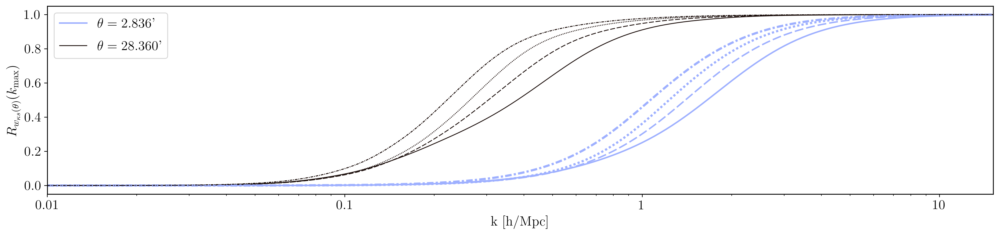

In [100]:
# Angular bins 10 and 20, counted from 0: theta near 2.8 and 28 arcmin.
idx = [10, 20]
cnu.plot_response_function(k=kk,
                           resp=rfwks,
                           labels=[rf"$\theta={theta[i]:.3f}$'" for i in idx],
                           idx=idx,
                           ncolors=3,
                           ylabel=r"$R_{w_{\kappa s}(\theta)}(k_{\mathrm{max}})$",
                           normalize=False)


## The UV-fraction scale cut of $w(\theta)$: $\theta_\mathrm{min}$ against $k_\mathrm{max}$

A scale cut removes the data points a model cannot be trusted to
predict. The UV-fraction criterion (arXiv:2603.13031) asks each data
point how much of it comes from small scales: the 3D power spectrum is
multiplied by a step at $k_\mathrm{max}/D(z)$, with $D$ the linear growth
factor normalized to $D(0) = 1$, which splits every clustering
multipole into $C_\ell = C_\ell^\mathrm{IR} + C_\ell^\mathrm{UV}$ - the part
sourced by modes $k \le k_\mathrm{max}/D(z)$ (IR, infrared: large scales)
and the rest (UV, ultraviolet: small scales). The split passes linearly
through the bin-averaged Legendre projection, so
$w = w_\mathrm{IR} + w_\mathrm{UV}$, and an angular bin is kept while its UV
fraction stays below the threshold $\alpha$:

$$\frac{|w_\mathrm{UV}(\theta)|}{|w_\mathrm{UV}(\theta)| + |w_\mathrm{IR}(\theta)|} < \alpha, \qquad \alpha = 0.05$$

($\alpha = 0.01$ is the conservative variant). $k_\mathrm{max}$ is quoted
at $z = 0$ in $h$/Mpc: each lens bin is cut at $k_\mathrm{max}/D(z)$, a
larger wavenumber at higher redshift. The $1/D$ scaling is an adopted
growth-scaled prescription, not a derived law. This criterion is not
the response-function cut of arXiv:2011.06469, which the response-function sections of this notebook compute for
cosmic shear: that criterion thresholds the cumulative response
$R(k_{\mathrm{max}})$ of the data vector to the matter power spectrum,
while the UV fraction thresholds the share of $w(\theta)$ itself that
the cut modes source.

Two structural rules keep the kept set well defined near the zero
crossings of $w(\theta)$, where either part can change sign and the
fraction is fragile. The kept set is a suffix in $\theta$: the scan starts at the
largest angle and stops at the first bin above $\alpha$, so a smaller
angle whose fraction dips back below $\alpha$ stays cut. And the suffix
only shrinks as $k_\mathrm{max}$ decreases. $\theta_\mathrm{min}$ is the
area-weighted center (arcmin) of the smallest kept bin; when no bin
survives, $\theta_\mathrm{min}$ is reported as the upper edge of the
angular range, 250 arcmin, and the all-zero mask row is the
authoritative statement.

The cut is a diagnostic of the evaluated model, not a filter on the
data: an analysis fixes the selected rows and evaluates the full,
unwindowed theory on them, and the window is never applied to measured
correlation functions. Only the clustering autos are cut - the $k$
window exists in the galaxy-clustering engines only, so $\gamma_t$ and
$\xi_\pm$ are outside it. The cut runs on whichever projection the
likelihood selected; here that is this project's default: the exact
non-Limber evaluation (FKEM) below $\ell = 150$ and the Limber
approximation above (Limber collapses the line-of-sight integral so
each multipole reads a single wavenumber per distance; FKEM keeps the
full integral).

The first figure draws $\theta_\mathrm{min}$ against $k_\mathrm{max}$, one
curve per lens bin, on 12 log-spaced $k_\mathrm{max}$ from 0.05 to
1.0 $h$/Mpc. At the three smallest cuts ($k_\mathrm{max} \le 0.086\,h$/Mpc) every lens bin loses all its angular bins. At $k_\mathrm{max} = 0.3\,h$/Mpc, $\theta_\mathrm{min}$ is 113 arcmin for the first lens bin and 45 arcmin for the last.
In comoving units the smallest kept scale is
$R = \theta_\mathrm{min}\,\chi(\bar z)$, with $\chi(\bar z)$ the comoving
distance to the lens bin's mean redshift: at
$k_\mathrm{max} = 0.3\,h$/Mpc, $R \approx$ 27 Mpc/$h$ for the lowest and
30 Mpc/$h$ for the highest lens bin. The second figure shows $w$,
$w_\mathrm{IR}$ and $w_\mathrm{UV}$ for lens bin 3 at
$k_\mathrm{max} = 0.3\,h$/Mpc, with the cut region
$\theta < \theta_\mathrm{min}$ shaded: the UV part grows toward small
angles until the fraction crosses $\alpha$.

How much does the projection matter for the cut? Running the same cut
with Limber at every $\ell$ changes $\theta_\mathrm{min}$ only at
$0.113 \le k_\mathrm{max} \le 0.336\,h$/Mpc, at the largest angles,
and in both directions: the affected bins sit near a zero crossing of
$w$ with fractions close to $\alpha$, so a small change of the
multipoles moves a bin across the threshold - not a smooth shift of the
cut. The largest change is +169 arcmin, for lens bin 5 at $k_\mathrm{max} = 0.195$ and $0.256\,h$/Mpc; Limber and FKEM give the same $\theta_\mathrm{min}$ in every bin for $k_\mathrm{max} \le 0.086$ and $k_\mathrm{max} \ge 0.442\,h$/Mpc. The low-rank (SVD) non-Limber
engine gives the same $\theta_\mathrm{min}$ as FKEM in every bin and at every $k_\mathrm{max}$. The notebook then
restores the default engine, and the next ordinary evaluation
reproduces the data vector bit for bit.

In [101]:
# DRAFT comments (Fable rewrites the final text).
# Re-init with the clustering probes: the cut needs the six lens bins and
# their nuisance state (galaxy bias, lens photo-z shifts and stretches,
# magnification), which nw.compute_probes sets at the fiducial point
# together with the cosmology and the accuracy defaults. The cut runs the
# projection the interface holds: the default non-Limber FKEM path.
ini = nw.init_cosmolike(CLprobe="6x2pt", with_data=True)
ref6 = nw.compute_probes()
# 12 log-spaced k_max in h/Mpc at z = 0, strictly ascending
kmax = np.geomspace(0.05, 1.0, 12)
alpha = 0.05
t0 = time.time()
cuts = ci.w_gg_scale_cuts_tomo(kmax=kmax, alpha=alpha)
time_cut = time.time() - t0
# theta and kmax arrive as (n, 1) columns; np.ravel flattens them
theta_w = np.ravel(cuts["theta"])
# theta_min[b, k]: arcmin, the cut of lens bin b at kmax[k]; 250 means
# that no angular bin is kept (the mask row is then all zero)
theta_min = np.array(cuts["theta_min"])
print("12 cuts in %.2f s (FKEM)" % time_cut)
print("theta_min [arcmin], alpha = %.2f" % alpha)
print("%10s" % "k_max" + "".join(["%7.3f" % k for k in kmax]))
for b in range(theta_min.shape[0]):
    print("%10s" % ("lens bin %d" % (b + 1))
          + "".join(["%7.3g" % value for value in theta_min[b]]))
# The UV fraction of the three largest angular bins at k_max = 0.149
# h/Mpc (kmax[4]), against alpha = 0.05: a fraction within a few
# percent of alpha decides the cut there, so a small accuracy change can
# move theta_min by one or more angular bins (uv_fraction has axes
# [lens bin, theta, k_max])
uv_fraction = np.array(cuts["uv_fraction"])
print()
print("f_UV at k_max = %.3f h/Mpc, theta = %s arcmin"
      % (kmax[4], ", ".join(["%.0f" % t for t in theta_w[-3:]])))
for b in range(uv_fraction.shape[0]):
    print("%10s" % ("lens bin %d" % (b + 1))
          + "".join(["%9.4f" % value for value in uv_fraction[b, -3:, 4]]))

12 cuts in 0.55 s (FKEM)
theta_min [arcmin], alpha = 0.05
     k_max  0.050  0.066  0.086  0.113  0.149  0.195  0.256  0.336  0.442  0.580  0.762  1.000
lens bin 1    250    250    250    250    225    179    113   89.7   71.2   56.6   35.7   28.4
lens bin 2    250    250    250    250    225    179   71.2   56.6   35.7   28.4   22.5   17.9
lens bin 3    250    250    250    250    179    179    142   89.7   56.6   28.4   22.5   17.9
lens bin 4    250    250    250    250    250    142    113   56.6   28.4   22.5   17.9   14.2
lens bin 5    250    250    250    250    142   56.6   56.6   44.9   35.7   14.2   14.2   11.3
lens bin 6    250    250    250    225    225    225   71.2   28.4   22.5   17.9   14.2   7.12

f_UV at k_max = 0.149 h/Mpc, theta = 142, 179, 225 arcmin
lens bin 1   0.1584   0.1351   0.0265
lens bin 2   0.1222   0.1012   0.0382
lens bin 3   0.0553   0.0070   0.0497
lens bin 4   0.0183   0.0635   0.1024
lens bin 5   0.0201   0.0476   0.0190
lens bin 6   0.0440   0.0364

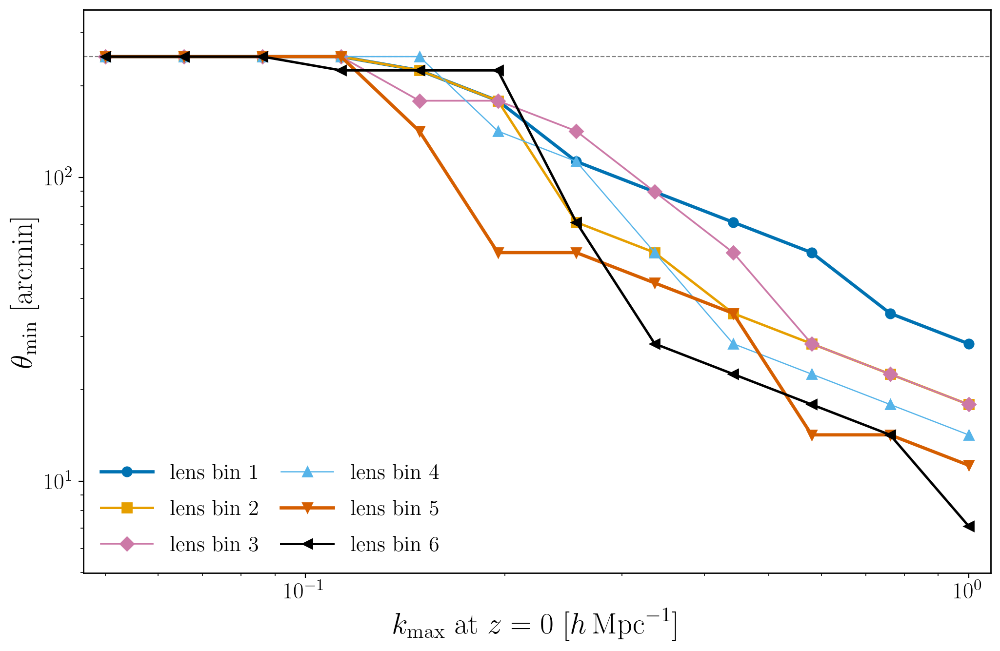

In [102]:
# The upper edge of the angular range, 250 arcmin, marks "no bin kept"
# (gray dashed reference line, no legend entry).
binlabels = []
for b in range(theta_min.shape[0]):
    binlabels.append("lens bin %d" % (b + 1))
cnu.plot_scale_cuts(kmax=kmax,
                    cut=theta_min,
                    ylabel=r"$\theta_{\rm min}$ [arcmin]",
                    binlabels=binlabels,
                    xscale="log",
                    yscale="log",
                    yref=[ini.float("theta_max_arcmin")],
                    figsize=(12, 7.5),
                    markersize=7,
                    legendfontsize=16,
                    yaxislabelsize=22,
                    xaxislabelsize=22,
                    yaxisticklabelsize=17,
                    xaxisticklabelsize=17)

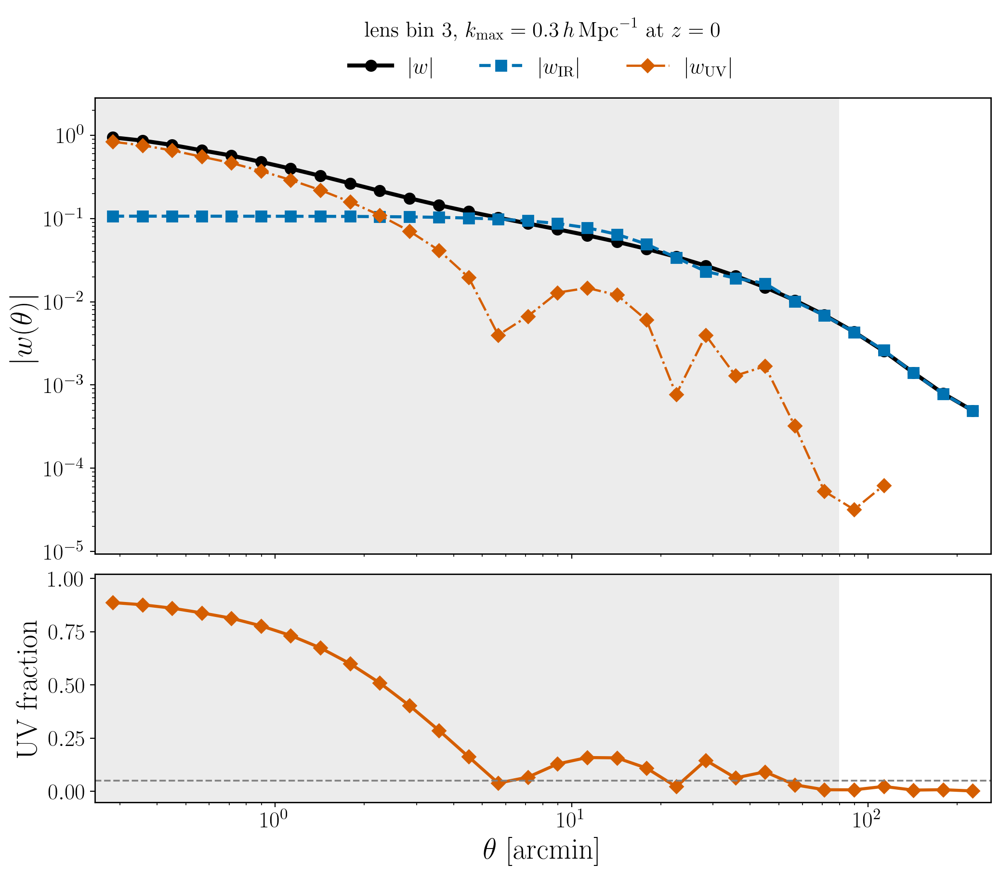

lens bin 3, k_max = 0.3 h/Mpc at z = 0: theta_min = 89.7 arcmin, 5 of 30 angular bins kept
theta_min at k_max = 0.3 h/Mpc, lens bins 1-6 [arcmin]: [112.9   89.68  89.68  56.59  44.95  44.95]


In [103]:
# DRAFT comments (Fable rewrites the final text).
# The full, IR and UV w(theta) of lens bin 3 (index 2), a middle bin of
# the six, at k_max = 0.3 h/Mpc at z = 0. kmax <= 0 gives the full w,
# keep_ir = 1 the IR part, 0 the UV part; each array is
# (lens bin, angular bin).
panel_bin = 2
kmax_panel = 0.3
w_full = np.array(ci.w_gg_kwindow_tomo(kmax=-1.0, keep_ir=1))
w_ir = np.array(ci.w_gg_kwindow_tomo(kmax=kmax_panel, keep_ir=1))
w_uv = np.array(ci.w_gg_kwindow_tomo(kmax=kmax_panel, keep_ir=0))
n_lens = w_full.shape[0]
# the cut at k_max = 0.3 comes from the figure's grid with 0.3 added, so
# the monotone rule (the kept set only shrinks as k_max decreases)
# applies to it as it does to the figure: a cut at 0.3 alone could keep
# more angular bins than the grid keeps at the next larger value, 0.336.
# column_panel is the position of 0.3 in the sorted grid.
kmax_with_panel = np.sort(np.append(kmax, kmax_panel))
column_panel = int(np.argmin(np.abs(kmax_with_panel - kmax_panel)))
cut_panel = ci.w_gg_scale_cuts_tomo(kmax=kmax_with_panel, alpha=alpha)
# theta_min of every lens bin at 0.3, and the UV fraction and the kept
# mask of the drawn bin
theta_min_panel = np.array(cut_panel["theta_min"])[:, column_panel]
uv_fraction_panel = np.array(cut_panel["uv_fraction"])[panel_bin, :, column_panel]
kept_panel = np.array(cut_panel["mask"])[panel_bin, :, column_panel]

# the x range: the bin centers with 15% margins on a log axis
theta_low = theta_w[0]/1.15
theta_high = theta_w[-1]*1.15
# the gray band covers the cut bins: from the left end of the axis to the
# edge between the last cut bin and the first kept one (the geometric
# mean of their centers, the bins being log-spaced); with no bin kept it
# covers the whole axis
band_edge = None
if np.sum(kept_panel) == 0:
    band_edge = theta_high
else:
    # np.argmax returns the first index where the mask is 1
    first_kept = int(np.argmax(kept_panel > 0.5))
    if first_kept > 0:
        band_edge = np.sqrt(theta_w[first_kept - 1]*theta_w[first_kept])

# |w| of each part on a log axis that ends five decades below the largest
# |w| of the bin; smaller values (where w or a part crosses zero) are not
# drawn
abs_full = np.abs(w_full[panel_bin])
abs_ir = np.abs(w_ir[panel_bin])
abs_uv = np.abs(w_uv[panel_bin])
y_high = 3.0*np.max(abs_full)
y_low = 1.0e-5*np.max(abs_full)
for curve in (abs_full, abs_ir, abs_uv):
    curve[curve < y_low] = np.nan

# colorblind-safe colors: blue for the IR part, vermillion for the UV
# part and its fraction; the full w is black. Each curve also has its
# own width, line style and marker.
colors = ["#0072B2", "#D55E00"]
fig, axes = plt.subplots(2, 1, figsize=(12, 9.5), sharex=True,
                         gridspec_kw={"hspace": 0.06, "height_ratios": [2, 1]})
axes[0].plot(theta_w, abs_full, color="black", linewidth=3.0, marker="o",
             markersize=8, label=r"$|w|$")
axes[0].plot(theta_w, abs_ir, color=colors[0], linewidth=2.3,
             linestyle="dashed", marker="s", markersize=8,
             label=r"$|w_{\rm IR}|$")
axes[0].plot(theta_w, abs_uv, color=colors[1], linewidth=1.7,
             linestyle="dashdot", marker="D", markersize=7,
             label=r"$|w_{\rm UV}|$")
axes[0].set_yscale("log")
axes[0].set_ylim(y_low, y_high)
axes[0].set_ylabel(r"$|w(\theta)|$", fontsize=22)
# the legend sits above the panels, where no curve is drawn
axes[0].legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncols=3,
               frameon=False, fontsize=16, title_fontsize=16,
               title=(r"lens bin %d, $k_{\rm max} = %g\,h\,{\rm Mpc}^{-1}$ "
                      r"at $z = 0$" % (panel_bin + 1, kmax_panel)))
# the UV fraction against the threshold alpha (gray dashed line)
axes[1].plot(theta_w, uv_fraction_panel, color=colors[1], linewidth=2.3,
             marker="D", markersize=7)
axes[1].axhline(y=alpha, color="gray", linestyle="dashed", linewidth=1.3)
# the fraction axis fits the data, 15% above the largest fraction and at
# least three times alpha, so the threshold line sits low in the panel
fraction_top = max(1.15*np.max(uv_fraction_panel), 3.0*alpha)
axes[1].set_ylim(-0.05*fraction_top, fraction_top)
axes[1].set_xscale("log")
axes[1].set_xlim(theta_low, theta_high)
axes[1].set_xlabel(r"$\theta$ [arcmin]", fontsize=22)
axes[1].set_ylabel("UV fraction", fontsize=22)
for ax in axes:
    if band_edge is not None:
        ax.axvspan(theta_low, band_edge, color="gray", alpha=0.15,
                   linewidth=0, zorder=0)
    ax.tick_params(axis="both", labelsize=17)
plt.show()
print("lens bin %d, k_max = %g h/Mpc at z = 0: theta_min = %.3g arcmin, "
      "%d of %d angular bins kept"
      % (panel_bin + 1, kmax_panel, theta_min_panel[panel_bin],
         int(np.sum(kept_panel)), len(theta_w)))
print("theta_min at k_max = %g h/Mpc, lens bins 1-%d [arcmin]:"
      % (kmax_panel, n_lens), np.round(theta_min_panel, 2))

In [104]:
# DRAFT comments (Fable rewrites the final text).
# The comoving scale R = theta_min chi(zbar) of the lowest and highest
# lens bins at k_max = 0.3 h/Mpc. zbar is the mean redshift of the lens
# n(z) file (its z column holds the left bin edges, so the centers sit
# half a bin higher) plus the fiducial photo-z shift dz_i; the stretch s_i
# of the MagLim model keeps the mean. chi(z) in Mpc/h comes from one CAMB
# run at the fiducial cosmology.
nz_lens = np.loadtxt(ini.relativeFileName("nz_lens_file"))
z_centers = nz_lens[:, 0] + 0.5*(nz_lens[1, 0] - nz_lens[0, 0])
(log10k_2D, z_2D, lnPL, lnPNL, G_growth, z_growth,
 z_1D, chi_1D, omegan2, lnPL_cb) = cnu.get_camb_cosmology(
    omegam=omegam, omegab=omegab, H0=H0, ns=ns, As_1e9=As_1e9,
    w=w, w0pwa=w0pwa, mnu=mnu, kmax=7.5, k_per_logint=10,
    CAMBAccuracyBoost=1.0, non_linear_emul=non_linear_emul)
arcmin = np.pi/(180.0*60.0)
for b in [0, n_lens - 1]:
    weights_nz = nz_lens[:, b + 1]
    zbar = np.sum(z_centers*weights_nz)/np.sum(weights_nz) + nw.LENS_PHOTOZ_FID[b]
    chi_bar = np.interp(zbar, z_1D, chi_1D)
    print("lens bin %d: zbar = %.3f, chi = %.0f Mpc/h, theta_min = %.3g arcmin, "
          "R = %.2f Mpc/h" % (b + 1, zbar, chi_bar, theta_min_panel[b],
                              theta_min_panel[b]*arcmin*chi_bar))

lens bin 1: zbar = 0.292, chi = 815 Mpc/h, theta_min = 113 arcmin, R = 26.75 Mpc/h
lens bin 6: zbar = 0.969, chi = 2259 Mpc/h, theta_min = 44.9 arcmin, R = 29.54 Mpc/h


In [105]:
# DRAFT comments (Fable rewrites the final text).
# Limber at every multipole
ci.init_adopt_limber_gg(adopt_limber_gg=1)
t0 = time.time()
cuts_limber = ci.w_gg_scale_cuts_tomo(kmax=kmax, alpha=alpha)
time_limber = time.time() - t0
ci.init_adopt_limber_gg(adopt_limber_gg=0)
# the low-rank (SVD) non-Limber engine, then back to FKEM
ci.init_lowrank_nonlimber_gg(flag=1, nrank=5, lmax=150)
t0 = time.time()
cuts_svd = ci.w_gg_scale_cuts_tomo(kmax=kmax, alpha=alpha)
time_svd = time.time() - t0
ci.init_lowrank_nonlimber_gg(flag=0, nrank=5, lmax=150)
theta_min_limber = np.array(cuts_limber["theta_min"])
theta_min_svd = np.array(cuts_svd["theta_min"])
diff_limber = theta_min_limber - theta_min
print("12 cuts: FKEM %.2f s, Limber %.2f s, SVD %.2f s"
      % (time_cut, time_limber, time_svd))
print("theta_min(Limber) - theta_min(FKEM) [arcmin]; '.' = 0")
print("%10s" % "k_max" + "".join(["%7.3f" % k for k in kmax]))
for b in range(diff_limber.shape[0]):
    line = "%10s" % ("lens bin %d" % (b + 1))
    for value in diff_limber[b]:
        if value == 0.0:
            line = line + "%7s" % "."
        else:
            line = line + "%+7.3g" % value
    print(line)
n_changed = int(np.count_nonzero(diff_limber))
print("entries that change: %d of %d" % (n_changed, diff_limber.size))
print("max |theta_min(SVD) - theta_min(FKEM)| = %g arcmin"
      % np.max(np.abs(theta_min_svd - theta_min)))
# the default engine is back: the FKEM cut is reproduced exactly
cuts_again = ci.w_gg_scale_cuts_tomo(kmax=kmax, alpha=alpha)
print("FKEM cut after restoring the engine identical:",
      np.array_equal(np.array(cuts_again["theta_min"]), theta_min))

12 cuts: FKEM 0.55 s, Limber 0.26 s, SVD 1.62 s


theta_min(Limber) - theta_min(FKEM) [arcmin]; '.' = 0
     k_max  0.050  0.066  0.086  0.113  0.149  0.195  0.256  0.336  0.442  0.580  0.762  1.000
lens bin 1      .      .      .      .  +24.7  +71.1      .      .      .      .      .      .
lens bin 2      .      .      .      .      .      .      .      .      .      .      .      .
lens bin 3      .      .      .      .  +71.1  +46.3      .      .      .      .      .      .
lens bin 4      .      .      .      .  -24.7  +36.8      .  +14.7      .      .      .      .
lens bin 5      .      .      .  -24.7  +83.1   +169   +169      .      .      .      .      .
lens bin 6      .      .      .      .  -46.3   -112      .      .      .      .      .      .
entries that change: 13 of 72
max |theta_min(SVD) - theta_min(FKEM)| = 0 arcmin
FKEM cut after restoring the engine identical: True
